# Burmese Classical Poetry Generation

## Problem Statement

The aim of this project is to develop and evaluate a sequence-to-sequence deep-learning model for Burmese classical-style poetry generation. The model will receive a complete Burmese poetic phrase and generate a continuation containing one phrase, several consecutive phrases, or the remainder of a stanza. Burmese text will be represented using orthographic syllable-like sound units rather than English-style words, while explicit `<PHRASE_END>` and `<STANZA_END>` tokens will allow phrase and stanza lengths to remain flexible.

The project begins with dataset inspection, Unicode-quality checks and syllable analysis before any train-validation-test split or model fitting. Baseline LSTM and GRU encoder-decoder models will later be compared under the same data split, after which attention can be introduced as a controlled improvement. Evaluation will combine token-level likelihood with boundary, rhyme, diversity and qualitative measures because a valid generated poem does not need to reproduce the single reference continuation exactly.

## 1. Environment Setup

### 1.1 Install Required Libraries

The project uses TensorFlow 2.10 because it is the final TensorFlow release with native-Windows NVIDIA GPU support. The remaining package versions are fixed to maintain compatibility and make the notebook reproducible. Run the installation cell once; if packages are installed or changed, restart the kernel before continuing.

In [1]:
%pip install -q "tensorflow<2.11" "numpy==1.23.5" "protobuf==3.19.6" "pandas==2.0.3" "openpyxl==3.1.5" "scikit-learn==1.3.2" "matplotlib==3.7.5" "seaborn==0.13.2"

Note: you may need to restart the kernel to use updated packages.


### 1.2 Import Libraries and Set Reproducibility

The CUDA DLL directory is registered before TensorFlow is imported so the native-Windows environment can locate the required GPU libraries. A common random seed is then applied to Python, NumPy and TensorFlow. Fixed seeds reduce accidental variation between experiments, although GPU operations may still contain some nondeterminism. The installed versions and available attention layers are printed to document the working environment.

In [1]:
import os
import platform
import random
import sys
import warnings
from pathlib import Path
import re
import unicodedata
from collections import Counter
from pathlib import Path

# Must happen BEFORE importing TensorFlow.
cuda_dll_dir = Path(sys.prefix) / "Library" / "bin"

if platform.system() == "Windows":
    if not cuda_dll_dir.exists():
        raise FileNotFoundError(f"CUDA DLL directory not found: {cuda_dll_dir}")

    # Keep this handle alive for the entire notebook session.
    _cuda_dll_handle = os.add_dll_directory(str(cuda_dll_dir))
    os.environ["PATH"] = str(cuda_dll_dir) + os.pathsep + os.environ["PATH"]

os.environ["PYTHONHASHSEED"] = "42"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.sequence import pad_sequences
from IPython.display import Markdown, display


warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"Python:        {sys.version.split()[0]}")
print(f"TensorFlow:   {tf.__version__}")
print(f"NumPy:        {np.__version__}")
print(f"Pandas:       {pd.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print(f"CUDA DLL path:{cuda_dll_dir}")
print(f"CUDA build:   {tf.test.is_built_with_cuda()}")

gpus = tf.config.list_physical_devices("GPU")
print(f"GPU devices:  {gpus}")

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print("Memory-growth warning:", error)

print("Attention:", tf.keras.layers.Attention)
print("Additive attention:", tf.keras.layers.AdditiveAttention)

<CONDA_ENV>\lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Python:        3.10.20
TensorFlow:   2.10.1
NumPy:        1.23.5
Pandas:       2.0.3
Scikit-learn: 1.3.2
CUDA DLL path:<CONDA_ENV>\Library\bin
CUDA build:   True
GPU devices:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Attention: <class 'keras.layers.attention.attention.Attention'>
Additive attention: <class 'keras.layers.attention.additive_attention.AdditiveAttention'>


### 1.3 Verify GPU Availability

TensorFlow is checked separately to confirm that the NVIDIA GPU is visible. Memory growth is enabled so TensorFlow allocates GPU memory as required instead of reserving all available memory at startup. Successful detection confirms that the later recurrent-model experiments can use GPU acceleration.

In [3]:
# Check whether TensorFlow can use a GPU.
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            # Memory growth must be configured before the GPU is initialized.
            pass
    print(f"GPU available: {gpus}")
else:
    print("No TensorFlow GPU detected; training will use the CPU.")
    if platform.system() == "Windows":
        print("For current TensorFlow GPU support on Windows, use a WSL2 environment.")

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Dataset Import and Structural Validation

The workbook stores poetry in fixed-width chunks for data collection, but these chunk rows are not necessarily complete stanzas. The original order and boundary markers must therefore be preserved before modelling.

### 2.1 Load the Chunked Poetry Workbook

The `Data` worksheet has no heading row. Columns A–E contain up to five consecutive phrases and column F contains `<CONTINUES>`, `<STANZA_END>` or `<REVIEW_END>`. The `NeedsReview` worksheet is retained as an audit record. All poetry columns are imported as strings so that pandas does not reinterpret Burmese text or numeric-looking content.

In [3]:
DATA_PATH = Path("burmese_classical_poetry_chunked.xlsx")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Place the workbook in the same folder as this notebook."
    )

PHRASE_COLUMNS = [f"phrase_{i}" for i in range(1, 6)]
DATA_COLUMNS = PHRASE_COLUMNS + ["boundary"]

with pd.ExcelFile(DATA_PATH, engine="openpyxl") as workbook:
    print("Worksheets:", workbook.sheet_names)
    poetry_df = pd.read_excel(
        workbook,
        sheet_name="Data",
        header=None,
        names=DATA_COLUMNS,
        dtype=str,
    )
    review_df = pd.read_excel(
        workbook,
        sheet_name="NeedsReview",
        dtype={"Output row": "Int64", "Original row": "Int64"},
    )

unresolved_review_count = int((poetry_df["boundary"] == "<REVIEW_END>").sum())

print(f"Data shape: {poetry_df.shape}")
print(f"Unresolved <REVIEW_END> markers in Data: {unresolved_review_count}")
print(f"Entries retained in NeedsReview audit sheet: {len(review_df)}")
poetry_df.head()

Worksheets: ['Data', 'NeedsReview']
Data shape: (13442, 6)
Unresolved <REVIEW_END> markers in Data: 0
Entries retained in NeedsReview audit sheet: 8


,phrase_1,phrase_2,phrase_3,phrase_4,phrase_5,boundary
0,သုစိပုဘာ၊,ဝိလိသိဓာ၊,အက္ခရာ စွဲသုံး၊,ဤရှစ်လုံးကို၊,သီကုံးပန်းသွင်၊,<CONTINUES>
1,နေ့တိုင်းဆင်လော့။,NaN,NaN,NaN,NaN,<STANZA_END>
2,စာသင်ပျိုနု၊,အခြေပြုတို့၊,ဥဇုဘူတ၊,လုံ့လပြင်းစွာ၊,သူ့ထက်ငါဟု၊,<CONTINUES>
3,နှုတ်မှာရွရွ၊,ကြိုးပမ်းကလျှင်၊,သိပ္ပကျေးဇူး၊,အထူးသိမြင်၊,ပညာရှင်ဟု၊,<CONTINUES>
4,မထင်မပေါ်၊,မကျော်စောဘဲ၊,တီမှာလွဲအံ့။,NaN,NaN,<STANZA_END>


### 2.2 Validate the Imported Structure

The workbook is checked for the expected six-column structure, missing boundary values and unexpected boundary labels. Phrase cells are counted without altering their text. Any unresolved `<REVIEW_END>` marker must be corrected before stanza reconstruction and before the final data split, because its meaning determines whether adjacent chunk rows belong to the same stanza.

In [4]:
# Perform basic structural checks without changing the poetry text.
EXPECTED_BOUNDARIES = {"<CONTINUES>", "<STANZA_END>", "<REVIEW_END>"}
observed_boundaries = set(poetry_df["boundary"].dropna().unique())
unexpected_boundaries = observed_boundaries - EXPECTED_BOUNDARIES

assert poetry_df.shape[1] == 6, "Expected five phrase columns and one boundary column."
assert poetry_df["boundary"].notna().all(), "Every row must have a boundary marker."
assert not unexpected_boundaries, f"Unexpected boundary markers: {unexpected_boundaries}"

phrase_count = int(poetry_df[PHRASE_COLUMNS].notna().sum().sum())
boundary_counts = poetry_df["boundary"].value_counts()

print(f"Imported phrase cells: {phrase_count:,}")
print("\nBoundary counts:")
display(boundary_counts.to_frame("rows"))

if unresolved_review_count:
    print("\nResolve <REVIEW_END> markers before the final train/validation/test split.")
else:
    print("\nNo unresolved boundary markers remain in the Data worksheet.")

Imported phrase cells: 63,685

Boundary counts:


,rows
boundary,
<CONTINUES>,11720
<STANZA_END>,1722



No unresolved boundary markers remain in the Data worksheet.


## 3. Stanza Reconstruction and Exploratory Data Analysis

The five phrase columns are storage chunks rather than independent stanzas. Genuine stanzas are reconstructed by following the rows in their original order until `<STANZA_END>` is reached. Exploratory analysis is then performed without deleting, normalising or reordering the source poetry.

### 3.1 Reconstruct Complete Stanzas

Each non-empty phrase cell is appended to the active stanza. `<CONTINUES>` keeps the stanza open, while `<STANZA_END>` closes it and assigns a stanza identifier. Assertions verify that reconstruction preserves every imported phrase and that the number of reconstructed stanzas agrees with the number of stanza-ending markers.

In [5]:
def reconstruct_stanzas(dataframe):
    stanzas = []
    current_phrases = []
    start_chunk_row = None

    for row_index, row in dataframe.iterrows():
        phrases = [
            str(row[column]).strip()
            for column in PHRASE_COLUMNS
            if pd.notna(row[column]) and str(row[column]).strip()
        ]

        if not phrases:
            raise ValueError(f"Chunk row {row_index + 1} contains no phrases.")

        if start_chunk_row is None:
            start_chunk_row = row_index + 1

        current_phrases.extend(phrases)
        boundary = row["boundary"]

        if boundary == "<STANZA_END>":
            stanzas.append(
                {
                    "stanza_id": len(stanzas),
                    "start_chunk_row": start_chunk_row,
                    "end_chunk_row": row_index + 1,
                    "phrases": current_phrases.copy(),
                    "phrase_count": len(current_phrases),
                }
            )
            current_phrases = []
            start_chunk_row = None
        elif boundary == "<REVIEW_END>":
            raise ValueError(
                f"Resolve <REVIEW_END> at chunk row {row_index + 1} before reconstruction."
            )
        elif boundary != "<CONTINUES>":
            raise ValueError(f"Unexpected boundary {boundary!r} at chunk row {row_index + 1}.")

    if current_phrases:
        raise ValueError("The dataset ends with an unfinished stanza.")

    return pd.DataFrame(stanzas)


stanzas_df = reconstruct_stanzas(poetry_df)

assert stanzas_df["phrase_count"].sum() == phrase_count
assert len(stanzas_df) == int((poetry_df["boundary"] == "<STANZA_END>").sum())

print(f"Reconstructed stanzas: {len(stanzas_df):,}")
print(f"Preserved phrases:      {stanzas_df['phrase_count'].sum():,}")
stanzas_df.head()

Reconstructed stanzas: 1,722
Preserved phrases:      63,685


,stanza_id,start_chunk_row,end_chunk_row,phrases,phrase_count
0,0,1,2,"[သုစိပုဘာ၊, ဝိလိသိဓာ၊, အက္ခရာ စွဲသုံး၊, ဤရှစ်လ...",6
1,1,3,5,"[စာသင်ပျိုနု၊, အခြေပြုတို့၊, ဥဇုဘူတ၊, လုံ့လပြင...",13
2,2,6,8,"[အရဲကြိုးကုတ်၊, ကြက်ရဲသုတ်သို့၊, အားထုတ်ခုံမင်...",11
3,3,9,13,"[စာသင်ဟူက၊, ကျမ်းထိုမျှကို၊, တွေ့ကမရှောင်၊, ကြ...",25
4,4,14,18,"[အံ့လောက်ဘွယ်သာ၊, ဂါထာပါဌ်သား၊, စကားဝိုက်လည်၊,...",22


### 3.2 Prepare Phrase-Level Inspection Tables

A phrase-level table is created by expanding each reconstructed stanza while retaining its stanza identifier. Character counts, phrase-ending punctuation and exact-duplicate indicators are added for inspection only. The original phrase remains unchanged; the normalised inspection key is used solely to identify visually equivalent duplicates and must not replace the training text at this stage.

In [6]:
# One row per phrase, while retaining the stanza identifier.
phrase_df = (
    stanzas_df[["stanza_id", "phrases"]]
    .explode("phrases", ignore_index=True)
    .rename(columns={"phrases": "phrase"})
)

def inspection_key(text):
    # Used only for duplicate inspection; the original phrase remains unchanged.
    text = unicodedata.normalize("NFC", str(text)).strip()
    return re.sub(r"\s+", " ", text)

phrase_df["inspection_key"] = phrase_df["phrase"].map(inspection_key)
phrase_df["character_count"] = phrase_df["phrase"].map(len)
phrase_df["ending_type"] = np.select(
    [
        phrase_df["phrase"].str.rstrip().str.endswith("၊"),
        phrase_df["phrase"].str.rstrip().str.endswith("။"),
    ],
    ["comma (၊)", "full stop (။)"],
    default="other",
)

stanzas_df["inspection_key"] = stanzas_df["phrases"].map(
    lambda phrases: "\u241f".join(inspection_key(phrase) for phrase in phrases)
)
stanzas_df["is_exact_duplicate"] = stanzas_df["inspection_key"].duplicated(keep=False)
phrase_df["is_exact_duplicate"] = phrase_df["inspection_key"].duplicated(keep=False)

print(f"Exact duplicate stanza rows: {int(stanzas_df['is_exact_duplicate'].sum()):,}")
print(f"Phrases occurring more than once: {int(phrase_df['is_exact_duplicate'].sum()):,}")

Exact duplicate stanza rows: 204
Phrases occurring more than once: 14,214


#### Duplicate Analysis

The dataset contains **204 exactly duplicated stanza rows**, which likely resulted from data collection and should be removed before modelling. However, the **14,214 repeated phrase occurrences** may be genuine poetic repetition and will not be removed automatically.

### 3.3 Summary Statistics

Descriptive statistics are calculated for stanza length, phrase character length, phrases stored per chunk row and ending punctuation. Percentiles are included because poetry lengths are not expected to follow a symmetric distribution, and extreme values may otherwise distort the mean.

In [7]:
stanza_length_summary = stanzas_df["phrase_count"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame("stanza phrase count")

phrase_length_summary = phrase_df["character_count"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame("phrase character count")

chunk_phrase_counts = (
    poetry_df[PHRASE_COLUMNS]
    .notna()
    .sum(axis=1)
    .value_counts()
    .sort_index()
    .rename_axis("phrases in chunk row")
    .to_frame("rows")
)

ending_counts = phrase_df["ending_type"].value_counts().to_frame("phrases")

display(stanza_length_summary)
display(phrase_length_summary)
display(chunk_phrase_counts)
display(ending_counts)

,stanza phrase count
count,1722.000000
mean,36.983159
std,43.242761
min,2.000000
50%,31.000000
75%,55.000000
90%,68.000000
95%,77.950000
99%,178.430000
max,561.000000


,phrase character count
count,63685.000000
mean,14.397959
std,3.506650
min,2.000000
50%,14.000000
75%,16.000000
90%,18.000000
95%,20.000000
99%,26.000000
max,53.000000


,rows
phrases in chunk row,
1,282
2,405
3,413
4,356
5,11986


,phrases
ending_type,
comma (၊),60922
full stop (။),2181
other,582


#### Length and Structure Analysis

The dataset contains **1,722 poem or stanza sequences** with a median of **31 phrases**, but sequence length varies considerably from **2 to 561 phrases**. Very long sequences are expected where an entire poem was collected without explicit stanza separation and are retained because the dataset is limited. Individual phrases are more consistent, with a median of **14 characters**. Most chunk rows contain five phrases because this is the storage format rather than a poetic rule. Most phrases end with the Burmese comma `၊`, while fewer use the full stop `။`.

### 3.4 Length and Punctuation Distributions

The plots show variation in reconstructed stanza length, phrase character length and ending punctuation. Length values are clipped at the 99th percentile for visualisation only; the underlying dataframe is not truncated. These distributions will later guide separate encoder and decoder padding lengths without imposing a fixed poetic structure.

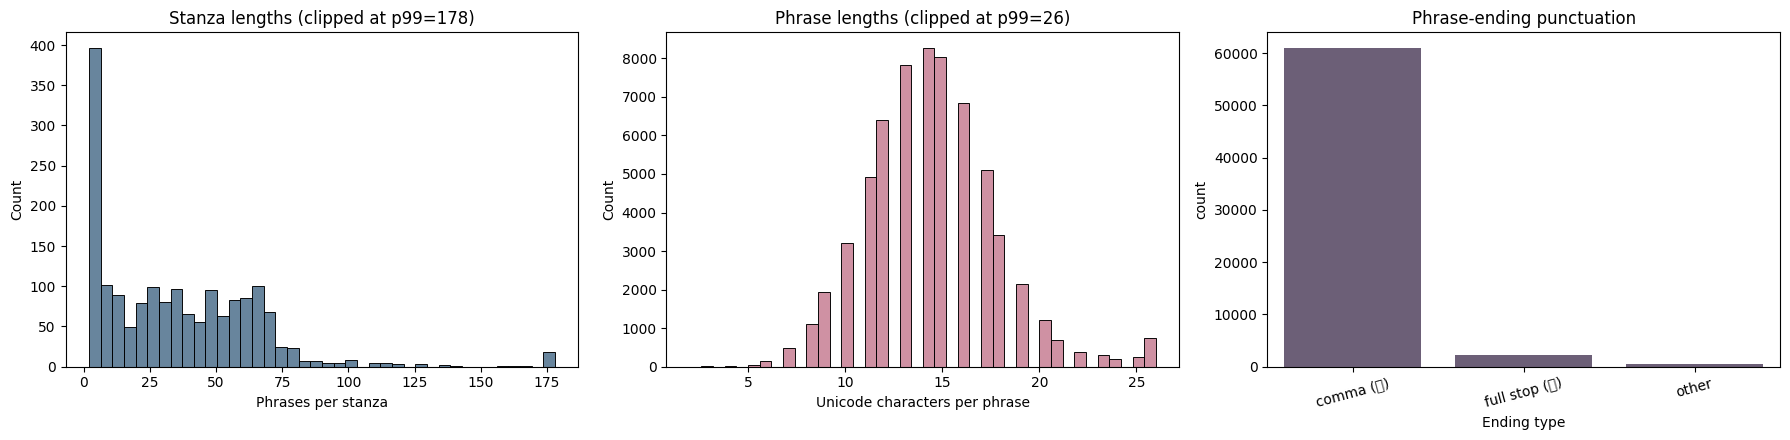

In [8]:
stanza_p99 = int(stanzas_df["phrase_count"].quantile(0.99))
phrase_p99 = int(phrase_df["character_count"].quantile(0.99))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

sns.histplot(
    stanzas_df["phrase_count"].clip(upper=stanza_p99),
    bins=40,
    ax=axes[0],
    color="#355C7D",
)
axes[0].set_title(f"Stanza lengths (clipped at p99={stanza_p99})")
axes[0].set_xlabel("Phrases per stanza")

sns.histplot(
    phrase_df["character_count"].clip(upper=phrase_p99),
    bins=40,
    ax=axes[1],
    color="#C06C84",
)
axes[1].set_title(f"Phrase lengths (clipped at p99={phrase_p99})")
axes[1].set_xlabel("Unicode characters per phrase")

sns.countplot(
    data=phrase_df,
    x="ending_type",
    order=["comma (၊)", "full stop (။)", "other"],
    ax=axes[2],
    color="#6C5B7B",
)
axes[2].set_title("Phrase-ending punctuation")
axes[2].set_xlabel("Ending type")
axes[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

#### Distribution Analysis

Stanza lengths vary greatly and are right-skewed, with many short stanzas and a small number of very long ones. Phrase lengths are more consistent, mostly around **14–16 characters**. The Burmese comma `၊` is the dominant phrase-ending mark, while full stops `။` mainly indicate larger structural endings.

### 3.5 Inspect Long Sequences and Frequent Phrases

The longest stanzas and phrase cells are displayed for manual review because they may represent genuine long-form poetry, missing boundaries or collection errors. Frequent exact phrases are also inspected. Repetition is not removed automatically because repeated expressions may be legitimate features of classical poetry; however, duplicate stanzas must later be grouped before splitting to prevent leakage.

In [9]:
print("Longest reconstructed stanzas:")
display(
    stanzas_df.nlargest(10, "phrase_count")[
        ["stanza_id", "start_chunk_row", "end_chunk_row", "phrase_count"]
    ]
)

print("Longest individual phrase cells:")
display(
    phrase_df.nlargest(15, "character_count")[
        ["stanza_id", "phrase", "character_count", "ending_type"]
    ]
)

print("Most frequent exact phrases:")
display(
    phrase_df["phrase"]
    .value_counts()
    .head(15)
    .rename_axis("phrase")
    .to_frame("frequency")
)

Longest reconstructed stanzas:


,stanza_id,start_chunk_row,end_chunk_row,phrase_count
1637,1637,12400,12512,561
1632,1632,11926,12035,547
1633,1633,12036,12126,451
1634,1634,12127,12217,451
1635,1635,12218,12308,451
1636,1636,12309,12399,451
1638,1638,12513,12587,371
1639,1639,12588,12653,330
1640,1640,12654,12719,330
1641,1641,12720,12785,330


Longest individual phrase cells:


,stanza_id,phrase,character_count,ending_type
1674,190,တီးသည့်စောင့်နှင့် လောင်းသည့်ကြက်ကို ပိုက်လို့...,53,comma (၊)
1688,192,မောင်ကလေးအောက်သို့စုန် ရွှေဂုန်ကျွန်း ဝေးလွန်း...,53,full stop (။)
19208,671,ဓမ္မိကာနံရာဇူနံ ကာလေ အနုဒသာဟံ အနုပဉ္စာဟံ ဒေဝေါ...,51,comma (၊)
27474,837,မျက်ခြည်ညောင်းသည် တမ်းကြောင်းဖြေဆည် ထားတော့သည်။,48,full stop (။)
442,44,မှောင်မှောင်သာ မိုက်ပါလို့ ပိန်းစိုက်ကာရွာသလေ။,46,full stop (။)
1498,156,ချစ်တဲ့သူငယ်လေ သူငယ်ချင်းကောင်း ယောက်မတို့လေ။,45,full stop (။)
439,44,ကျေးလုံးညိုညိုပြာ ပေါင်စိမ်းလဲ့ ငွေရောင်၊,41,comma (၊)
27499,838,သိမ်းမပြင်သည် ရက်ဖျင်တာရှည် များတော့သည်။,41,full stop (။)
1004,100,မာလာအလယ်မှာ နွဲ့ချင်တဲ့ နှလုံးရယ်ကြောင့်,40,other
1727,198,အပျိုဖြူငယ်က ကျွမ်းသည့် လွမ်းတုံ့တင်လေး။,40,full stop (။)


Most frequent exact phrases:


,frequency
phrase,
ရန်ငူးနတ်ရှင်မြေးတည့်လေး၊,60
ဧလည်းယင်ယင်ဧ၊,45
ဧလည်းယင်ယင်ဧ။,45
ဘွားတော်ရှင်ပင်မြေးတည့်လေး၊,30
ပျော်ကြောင်းကျူးသည်၊,30
ပျော်ကြောင်းဖျော်သည်၊,16
ကျက်သရေအပေါင်း၊,14
ကင်းစင်ဝေး၊,14
ဥပဒ်ရန်ဘေး၊,14


#### Outlier and Frequency Analysis

Several reconstructed stanzas contain more than **300 phrases**, with a maximum of **561**. These long sequences are expected when a complete poem was collected without explicit stanza separation and are therefore retained because the dataset is limited. The longest phrase cells and frequently repeated expressions are also kept, as they may represent valid poetic units, refrains or formulaic features of Burmese classical poetry.

## 4. Text Quality and Burmese Syllable Analysis

This section combines text-quality inspection, removal decisions and Burmese syllable analysis. Burmese strings can look identical while containing different Unicode sequences, invisible characters or inconsistent whitespace, while inappropriate segmentation can create incomplete sound units. The checks are performed before modelling so that cleaning and tokenisation decisions are supported by evidence.

### 4.1 Unicode and Whitespace Checks

Each phrase is checked for NFC changes, zero-width characters, Latin letters, digits, outer whitespace and repeated whitespace. The counts indicate which transformations may be justified in a later cleaning copy. Original text is retained so that every proposed correction remains auditable.

In [10]:
def is_myanmar_character(character):
    codepoint = ord(character)

    return (
        0x1000 <= codepoint <= 0x109F
        or 0xA9E0 <= codepoint <= 0xA9FF
        or 0xAA60 <= codepoint <= 0xAA7F
    )


def contains_zero_width(text):
    zero_width_characters = {
        "\u200b",  # zero-width space
        "\u200c",  # zero-width non-joiner
        "\u200d",  # zero-width joiner
        "\ufeff",  # byte-order mark
    }

    return any(character in text for character in zero_width_characters)


phrase_df["nfc_changes_text"] = phrase_df["phrase"].map(
    lambda text: text != unicodedata.normalize("NFC", text)
)

phrase_df["has_zero_width"] = phrase_df["phrase"].map(
    contains_zero_width
)

phrase_df["has_latin"] = phrase_df["phrase"].str.contains(
    r"[A-Za-z]",
    regex=True,
)

phrase_df["has_digit"] = phrase_df["phrase"].str.contains(
    r"[0-9၀-၉]",
    regex=True,
)

phrase_df["has_outer_whitespace"] = phrase_df["phrase"].map(
    lambda text: text != text.strip()
)

phrase_df["has_repeated_whitespace"] = phrase_df["phrase"].str.contains(
    r"\s{2,}",
    regex=True,
)

quality_summary = pd.Series(
    {
        "NFC changes text": phrase_df["nfc_changes_text"].sum(),
        "Contains zero-width characters": phrase_df["has_zero_width"].sum(),
        "Contains Latin characters": phrase_df["has_latin"].sum(),
        "Contains digits": phrase_df["has_digit"].sum(),
        "Has leading/trailing whitespace": (
            phrase_df["has_outer_whitespace"].sum()
        ),
        "Has repeated whitespace": (
            phrase_df["has_repeated_whitespace"].sum()
        ),
    },
    name="phrase count",
)

display(quality_summary.to_frame())

,phrase count
NFC changes text,0
Contains zero-width characters,0
Contains Latin characters,0
Contains digits,18
Has leading/trailing whitespace,0
Has repeated whitespace,8


#### Text Quality Analysis

No NFC inconsistencies, zero-width characters, Latin characters or outer whitespace were found. However, **18 phrases contain digits** and **8 contain repeated whitespace**. These cases will be handled during preprocessing to prevent unnecessary or inconsistent model tokens.

### 4.2 Unexpected Character Inventory

Characters outside the Myanmar Unicode blocks and permitted poetic punctuation are counted with their code points and Unicode names. The observed minus signs, English punctuation, left-to-right marks, plus signs and quotation marks are citation or reference artefacts rather than poetic content and will therefore be removed from the cleaned modelling copy.

In [11]:
allowed_non_myanmar = {
    " ",
    "\t",
    "\n",
    "၊",
    "။",
    "…",
    "-",
    "—",
    "(",
    ")",
    "[",
    "]",
    "{",
    "}",
    "'",
    '"',
}

unexpected_characters = Counter()

for phrase in phrase_df["phrase"]:
    for character in phrase:
        if (
            not is_myanmar_character(character)
            and character not in allowed_non_myanmar
            and not character.isspace()
        ):
            unexpected_characters[character] += 1

unexpected_character_table = pd.DataFrame(
    [
        {
            "character": character,
            "count": count,
            "codepoint": f"U+{ord(character):04X}",
            "unicode_name": unicodedata.name(character, "UNKNOWN"),
        }
        for character, count in unexpected_characters.most_common()
    ]
)

display(unexpected_character_table.head(30))

,character,count,codepoint,unicode_name
0,−,133,U+2212,MINUS SIGN
1,",",90,U+002C,COMMA
2,‎,25,U+200E,LEFT-TO-RIGHT MARK
3,+,12,U+002B,PLUS SIGN
4,“,4,U+201C,LEFT DOUBLE QUOTATION MARK
5,”,4,U+201D,RIGHT DOUBLE QUOTATION MARK
6,.,1,U+002E,FULL STOP
7,:,1,U+003A,COLON


#### Unexpected Character Analysis

Several non-Myanmar characters were found, including minus signs, English punctuation, left-to-right marks, plus signs and quotation marks. These are considered citation or reference artefacts rather than poetic content and must be removed during preprocessing. The cleaned text will be checked again to confirm that none remain.

### 4.3 Segment Complete Burmese Sound Units

English-style whitespace tokenisation is unsuitable because Burmese phrases may contain several sound units without spaces. The modelling unit is therefore an orthographic syllable-like unit in which combining marks, medials, killed finals and stacked consonants remain attached to the relevant onset. The segmentation rule handles forms such as `ရယ်`, `တည့်`, `မြင့်` and `နှင့်`, prevents incomplete fragments such as `ည့်` and `င့်`, and keeps `ကျွန်တော်` as the two units `ကျွန်` and `တော်`. Punctuation is excluded from syllable counts but remains available in the original phrase text.

In [12]:
MYANMAR_CONSONANTS = r"က-အ"
ENGLISH_AND_DIGITS = r"a-zA-Z0-9"
MYANMAR_OTHER_CHARACTERS = r"ဣဤဥဦဧဩဪဿ၌၍၏၀-၉၊။!-/:-@[-`{-~\s"
MYANMAR_PRE_ASAT_MARKS = r"\u1037"  # dot below in ည့်, င့်, etc.
MYANMAR_VIRAMA = "္"
MYANMAR_ASAT = "်"

# Insert a boundary before a consonant only when it is not stacked and is
# not followed by asat/virama, optionally after dot below. This keeps
# ရယ်, တည့်, မြင့်, and နှင့် intact without merging ကျွန် + တော်.
SYLLABLE_BREAK_PATTERN = re.compile(
    r"((?<!" + MYANMAR_VIRAMA + r")[" + MYANMAR_CONSONANTS
    + r"](?![" + MYANMAR_PRE_ASAT_MARKS + r"]*["
    + MYANMAR_ASAT + MYANMAR_VIRAMA + r"])|["
    + ENGLISH_AND_DIGITS + MYANMAR_OTHER_CHARACTERS + r"])",
    re.UNICODE,
)


def is_punctuation_or_space(token):
    return all(
        character.isspace()
        or unicodedata.category(character).startswith("P")
        for character in token
    )


def split_myanmar_syllables(text, keep_punctuation=False):
    if pd.isna(text):
        return []

    text = unicodedata.normalize("NFC", str(text)).strip()
    if not text:
        return []

    marked_text = SYLLABLE_BREAK_PATTERN.sub(r"|\1", text)
    syllables = [
        part.strip()
        for part in marked_text.split("|")
        if part.strip()
    ]

    if not keep_punctuation:
        syllables = [
            syllable
            for syllable in syllables
            if not is_punctuation_or_space(syllable)
        ]

    return syllables


# Regression checks for previously observed incomplete fragments.
SEGMENTATION_CHECKS = {
    "ရယ်": ["ရယ်"],
    "တည့်": ["တည့်"],
    "မြင့်": ["မြင့်"],
    "နှင့်": ["နှင့်"],
    "ကျွန်တော်": ["ကျွန်", "တော်"],
}
for text, expected in SEGMENTATION_CHECKS.items():
    assert split_myanmar_syllables(text) == expected

phrase_df["syllables"] = phrase_df["phrase"].map(
    split_myanmar_syllables
)
phrase_df["syllable_count"] = phrase_df["syllables"].map(len)

test_words = ["ရယ်", "တည့်", "မြင့်", "နှင့်", "မြန်မာ", "ကျွန်တော်"]
for word in test_words:
    print(f"{word} -> {split_myanmar_syllables(word)}")

display(
    phrase_df[["phrase", "syllables", "syllable_count"]]
    .sample(min(20, len(phrase_df)), random_state=SEED)
)

ရယ် -> ['ရယ်']
တည့် -> ['တည့်']
မြင့် -> ['မြင့်']
နှင့် -> ['နှင့်']
မြန်မာ -> ['မြန်', 'မာ']
ကျွန်တော် -> ['ကျွန်', 'တော်']


,phrase,syllables,syllable_count
28266,ပူဖြူအနောက်၊,"[ပူ, ဖြူ, အ, နောက်]",4
3104,ဝင်းဝင်းတောက်ပ၊,"[ဝင်း, ဝင်း, တောက်, ပ]",4
23444,ကြည်ဖြူစကြ၊,"[ကြည်, ဖြူ, စ, ကြ]",4
18746,နတ်မိဖုရား၊,"[နတ်, မိ, ဖု, ရား]",4
52586,နေ့နှင့်ညတိ၊,"[နေ့, နှင့်, ည, တိ]",4
13728,မိပြည် ဘရွာ၊,"[မိ, ပြည်, ဘ, ရွာ]",4
61730,ခန့်လောက်ဆံကို၊,"[ခန့်, လောက်, ဆံ, ကို]",4
37296,ညာကြော်ပစ်ဘောက်၊,"[ညာ, ကြော်, ပစ်, ဘောက်]",4
10189,ပူပင်ဆန်းသာ၊,"[ပူ, ပင်, ဆန်း, သာ]",4
55785,ပယဉ်းမှာလူတိမ်၊,"[ပ, ယဉ်း, မှာ, လူ, တိမ်]",5


#### Syllable Segmentation Analysis

The test cases confirm that complete sound units such as `ရယ်`, `တည့်`, `မြင့်` and `နှင့်` remain intact. Most sampled phrases contain **four syllables**, while some contain three, five or more. This supports learning the common four-syllable pattern from the data while allowing flexible phrase lengths.

### 4.4 Syllable Counts per Phrase

The number and percentage of phrases containing two, three and four syllables are calculated from the corrected segmentation. This tests whether the expected 4-3-2 tendency is present in the corpus. The results describe the data rather than enforce a rule; phrase length will remain flexible during generation.

In [13]:
syllable_count_distribution = (
    phrase_df["syllable_count"]
    .value_counts()
    .sort_index()
    .rename_axis("estimated syllables")
    .to_frame("phrases")
)

syllable_count_distribution["percentage"] = (
    syllable_count_distribution["phrases"]
    / len(phrase_df)
    * 100
)

display(syllable_count_distribution.head(20))

for count in [2, 3, 4]:
    number = (
        phrase_df["syllable_count"] == count
    ).sum()

    percentage = number / len(phrase_df) * 100

    print(
        f"{count}-syllable phrases: "
        f"{number:,} ({percentage:.2f}%)"
    )

,phrases,percentage
estimated syllables,,
1,42,0.065950
2,460,0.722305
3,7054,11.076392
4,50792,79.755044
5,2814,4.418623
6,1057,1.659731
7,1138,1.786920
8,254,0.398838
9,39,0.061239


2-syllable phrases: 460 (0.72%)
3-syllable phrases: 7,054 (11.08%)
4-syllable phrases: 50,792 (79.76%)


#### Phrase Syllable Distribution

Approximately **79.76%** of phrases contain four syllables, confirming that four-syllable phrasing is the dominant structure. Three-syllable phrases account for **11.08%**, while shorter and longer forms occur less frequently. Therefore, the model should learn this pattern from the data without enforcing a fixed phrase length.

### 4.5 Syllable Vocabulary Analysis

All syllable tokens are combined to measure vocabulary size, frequency and the number of singleton types. The explicit invalid-fragment assertion stops the analysis if `ည့်` or `င့်` appears as an isolated token. Because the observed vocabulary is manageable and rare units may contain meaningful classical language or rhyme information, the baseline will retain every syllable found in the training partition. Only syllables unseen during vocabulary fitting will map to `<UNK>`.

In [14]:
all_syllables = [
    syllable
    for phrase_syllables in phrase_df["syllables"]
    for syllable in phrase_syllables
]

syllable_frequency = Counter(all_syllables)

# These indicate that a killed final was incorrectly split from its onset.
invalid_fragment_counts = Counter(
    syllable for syllable in all_syllables
    if syllable in {"ည့်", "င့်"}
)
assert not invalid_fragment_counts, (
    f"Incomplete syllable fragments found: {dict(invalid_fragment_counts)}"
)

unique_syllables = len(syllable_frequency)
singleton_syllables = sum(
    frequency == 1
    for frequency in syllable_frequency.values()
)

print(f"Total syllable tokens:  {len(all_syllables):,}")
print(f"Unique syllable types:  {unique_syllables:,}")
print(f"Singleton syllables:     {singleton_syllables:,}")
print(
    f"Singleton percentage:   "
    f"{singleton_syllables / unique_syllables * 100:.2f}%"
)

display(
    pd.DataFrame(
        syllable_frequency.most_common(30),
        columns=["syllable", "frequency"],
    )
)

Total syllable tokens:  256,448
Unique syllable types:  3,185
Singleton syllables:     816
Singleton percentage:   25.62%


,syllable,frequency
0,မ,6014
1,အ,4233
2,သည်,4021
3,တ,3092
4,ကို,3070
5,တော်,2702
6,က,2410
7,နှင့်,2406
8,သာ,2319
9,သ,2316


#### Syllable Vocabulary Analysis

The dataset contains **256,448 syllable tokens** and **3,185 unique syllable types**, providing a manageable vocabulary for sequence modelling. Although **816 types (25.62%)** occur only once, these may represent meaningful classical forms or rhyme endings. The baseline will therefore retain all syllable types found in the training partition, while genuinely unseen validation and test syllables will map to `<UNK>`.

### 4.6 Phrase-Ending Syllables

The most frequent final syllables are inspected because phrase endings carry important rhyme information. These exact orthographic endings provide an initial baseline for rhyme analysis. A later phonetic normalisation or rhyme-class component may be required because different written forms can share related rhyme sounds.

In [15]:
phrase_df["ending_syllable"] = phrase_df[
    "syllables"
].map(
    lambda syllables: syllables[-1] if syllables else None
)

ending_syllable_counts = (
    phrase_df["ending_syllable"]
    .value_counts()
    .head(30)
    .rename_axis("ending syllable")
    .to_frame("frequency")
)

display(ending_syllable_counts)

,frequency
ending syllable,
သည်,2536
ကို,2480
နှင့်,1850
က,1176
လည်း,1134
လျှင်,1084
သို့,951
ဟု,913
လျက်,844


#### Phrase-Ending Analysis

Phrase endings are dominated by recurring grammatical and poetic syllables such as `သည်`, `ကို`, `နှင့်` and `လည်း`. Their high frequencies provide useful patterns for learning phrase completion and structure. However, exact ending syllables do not fully represent rhyme, so a phonetic rhyme analysis may be required later.

### 4.7 EDA Findings and Modelling Implications

The workbook contains **13,442 storage rows** and **63,685 phrase cells**. Reconstruction preserves every phrase and produces **1,722 poem or stanza sequences**, with no unresolved `<REVIEW_END>` markers. The **204 exactly duplicated stanza rows** are considered collection duplicates and will be reduced to one copy before modelling. In contrast, the **14,214 repeated phrase occurrences** are retained because repetition, refrains and formulaic expressions can be genuine features of classical poetry.

Sequence length varies from 2 to 561 phrases. The very long sequences are retained because some sources contain a complete poem without explicit stanza separation and the available dataset is limited. Phrase lengths are more stable, with a median of 14 characters, and the Burmese comma `၊` is the dominant phrase-ending mark.

The text is already consistently NFC-normalised and contains no zero-width characters, Latin letters or outer whitespace. Nevertheless, 18 phrases contain digits and 8 contain repeated whitespace, which must be handled during preprocessing. Non-Myanmar minus signs, English punctuation, left-to-right marks, plus signs and quotation marks are treated as citation artefacts and will be removed. Cleaning will be applied to a copy so the original source remains auditable.

The corrected segmentation produces complete sound units. Four-syllable phrases dominate at **79.76%**, while three-syllable phrases account for **11.08%** and other lengths remain valid. The model should therefore learn the common four-syllable tendency without enforcing a fixed 4-3-2 structure. The vocabulary contains **3,185 syllable types** across **256,448 tokens** and is small enough to retain all training-set types, including rare classical forms; unseen validation or test syllables will use `<UNK>`. Frequent phrase endings provide useful structural evidence, but exact spelling alone is insufficient for a complete rhyme evaluation, so phonetic rhyme analysis can be added later.

#### Next Steps

1. Create a cleaned copy that removes citation artefacts, handles digits and repeated whitespace, and preserves the original text for auditing.
2. Remove exact duplicate stanzas while retaining repeated phrases and long complete-poem sequences.
3. Split complete non duplicated sequences into training, validation and test partitions before creating overlapping examples, preventing phrases from the same poem from crossing partitions.
4. Fit the syllable vocabulary on the training partition only and add `<PAD>`, `<UNK>`, `<START>`, `<PHRASE_END>` and `<STANZA_END>`.
5. Prepare controlled datasets for phrase completion, next-phrase prediction, three-phrase continuation and continuation to sequence end.
6. Compare LSTM and GRU baselines using the same split and masked metrics, select the stronger baseline, and then test attention as a controlled improvement.

## 5. Data Preprocessing

Preprocessing is performed on a copy of the reconstructed data so the original poem text remains available for auditing. The modelling token is a **Burmese syllable-like sound unit**, not a phrase. Phrases and poem or stanza sequences remain structural containers: `<PHRASE_END>` separates groups of syllable tokens and `<STANZA_END>` marks the end of the complete sequence.

### 5.1 Clean a Copy of the Poetry Text

The cleaning rules follow the EDA findings. Numeric-only range or page-reference cells are removed as non-poetic material. Within genuine phrases, the historical or OCR forms `၄င်း` and `၀` are repaired as `၎င်း` and `ဝ`. Confirmed citation artefacts are removed, repeated whitespace is collapsed and spacing before Burmese punctuation is corrected. Artefact separators are first converted to spaces so adjacent Burmese words are not accidentally joined.

In [16]:
REFERENCE_ONLY_PATTERN = re.compile(
    r"^\s*[0-9၀-၉]+(?:\s*မှ\s*[0-9၀-၉]+\s*ထိ)?\s*[၊။]?\s*$"
)

CITATION_ARTIFACTS = {
    "−",  # U+2212 minus sign
    ",",  # ASCII comma
    "+",
    "“",
    "”",
    ".",  # ASCII full stop
    ":",
}
ARTIFACT_TO_SPACE = str.maketrans(
    {character: " " for character in CITATION_ARTIFACTS}
)


def clean_poetry_phrase(text):
    text = unicodedata.normalize("NFC", str(text))

    # Remove numeric headings, ranges and page references as whole cells.
    if REFERENCE_ONLY_PATTERN.fullmatch(text):
        return None

    # Repair digit-shaped characters used inside genuine Burmese words.
    text = text.replace("၄င်း", "၎င်း")
    text = text.replace("၀", "ဝ")

    # Remove the invisible direction mark and replace visible reference
    # separators with spaces before whitespace normalisation.
    text = text.replace("\u200e", "")
    text = text.translate(ARTIFACT_TO_SPACE)

    # Any remaining digits are not treated as poetic syllables.
    text = re.sub(r"[0-9၁-၉]+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    text = re.sub(r"\s+([၊။])", r"\1", text)

    # Remove punctuation-only cells that contain no syllable-bearing letter.
    if not re.search(r"[က-အဣဤဥဦဧဩဪဿ]", text):
        return None

    return text


cleaning_records = []
cleaned_phrase_lists = {}

for stanza in stanzas_df.itertuples(index=False):
    cleaned_phrases = []

    for position, original_phrase in enumerate(stanza.phrases, start=1):
        cleaned_phrase = clean_poetry_phrase(original_phrase)

        cleaning_records.append(
            {
                "source_stanza_id": stanza.stanza_id,
                "phrase_position": position,
                "original_phrase": original_phrase,
                "cleaned_phrase": cleaned_phrase,
                "removed_non_poetic_cell": cleaned_phrase is None,
                "changed": cleaned_phrase != original_phrase,
            }
        )

        if cleaned_phrase is not None:
            cleaned_phrases.append(cleaned_phrase)

    if not cleaned_phrases:
        raise ValueError(
            f"Cleaning removed every phrase from stanza {stanza.stanza_id}."
        )

    cleaned_phrase_lists[stanza.stanza_id] = cleaned_phrases

cleaning_audit_df = pd.DataFrame(cleaning_records)

cleaned_stanzas_df = stanzas_df[
    ["stanza_id", "start_chunk_row", "end_chunk_row"]
].rename(columns={"stanza_id": "source_stanza_id"}).copy()

cleaned_stanzas_df["phrases"] = cleaned_stanzas_df[
    "source_stanza_id"
].map(cleaned_phrase_lists)
cleaned_stanzas_df["phrase_count"] = cleaned_stanzas_df[
    "phrases"
].map(len)

cleaning_summary = pd.Series(
    {
        "original phrase cells": len(cleaning_audit_df),
        "changed phrase cells": int(cleaning_audit_df["changed"].sum()),
        "removed non-poetic/reference cells": int(
            cleaning_audit_df["removed_non_poetic_cell"].sum()
        ),
        "retained cleaned phrases": int(
            cleaned_stanzas_df["phrase_count"].sum()
        ),
    },
    name="count",
)

display(cleaning_summary.to_frame())
display(
    cleaning_audit_df.loc[cleaning_audit_df["changed"]]
    .head(30)
)

,count
original phrase cells,63685
changed phrase cells,335
removed non-poetic/reference cells,9
retained cleaned phrases,63676


,source_stanza_id,phrase_position,original_phrase,cleaned_phrase,removed_non_poetic_cell,changed
297,26,8,မင်းဘွယ်စိုးရလောက်ပေလေး ။,မင်းဘွယ်စိုးရလောက်ပေလေး။,False,True
774,94,31,မှန်စွာ၄င်း၊,မှန်စွာ၎င်း၊,False,True
1066,109,7,“ဖိုးမောင်လာပြီ” ဆိုကြသည်။,ဖိုးမောင်လာပြီ ဆိုကြသည်။,False,True
1070,110,4,“ညခါ ငါးထောင်၊,ညခါ ငါးထောင်၊,False,True
1072,110,6,ရွာတောင်ချောင်းက ပြန်ခဲ့ပြီ”။,ရွာတောင်ချောင်းက ပြန်ခဲ့ပြီ။,False,True
1110,115,5,“မောင်းကိုထုပါ၊,မောင်းကိုထုပါ၊,False,True
1115,115,10,ဖမ်း၍ထား” ဟု,ဖမ်း၍ထား ဟု,False,True
1135,117,9,“ဖိုးမောင်လာပြီ” ဆိုဆဲပင်။,ဖိုးမောင်လာပြီ ဆိုဆဲပင်။,False,True
1570,166,1,နှမထွေး ၊,နှမထွေး၊,False,True
1576,167,2,အုတ်ပလ္လင်နှင့် ၊,အုတ်ပလ္လင်နှင့်၊,False,True


### 5.2 Validate the Cleaned Text

The cleaned copy is checked for remaining digits, citation characters, direction marks, repeated whitespace and empty phrases. These assertions prevent later tokenisation from silently accepting known artefacts. The source and cleaned strings remain paired in `cleaning_audit_df` for manual inspection.

In [17]:
cleaned_phrases_flat = [
    phrase
    for phrases in cleaned_stanzas_df["phrases"]
    for phrase in phrases
]

remaining_quality_issues = pd.Series(
    {
        "contains digits": sum(
            bool(re.search(r"[0-9၀-၉]", phrase))
            for phrase in cleaned_phrases_flat
        ),
        "contains citation artefacts": sum(
            any(character in phrase for character in CITATION_ARTIFACTS)
            for phrase in cleaned_phrases_flat
        ),
        "contains left-to-right mark": sum(
            "\u200e" in phrase for phrase in cleaned_phrases_flat
        ),
        "contains repeated whitespace": sum(
            bool(re.search(r"\s{2,}", phrase))
            for phrase in cleaned_phrases_flat
        ),
        "empty phrase": sum(not phrase for phrase in cleaned_phrases_flat),
    },
    name="remaining phrases",
)

display(remaining_quality_issues.to_frame())
assert int(remaining_quality_issues.sum()) == 0
assert len(cleaned_phrases_flat) == int(
    cleaning_summary["retained cleaned phrases"]
)

,remaining phrases
contains digits,0
contains citation artefacts,0
contains left-to-right mark,0
contains repeated whitespace,0
empty phrase,0


### 5.3 Remove Exact Duplicate Sequences

Exact duplicates are identified again after cleaning because normalisation can make previously different strings identical. One copy of each complete poem or stanza sequence is retained. Repeated phrases inside otherwise different sequences are not removed because they may represent genuine refrains or formulaic classical language.

In [18]:
cleaned_stanzas_df["stanza_key"] = cleaned_stanzas_df["phrases"].map(
    lambda phrases: "\u241f".join(phrases)
)

duplicate_sequence_rows = int(
    cleaned_stanzas_df["stanza_key"].duplicated(keep=False).sum()
)

preprocessed_stanzas_df = (
    cleaned_stanzas_df
    .drop_duplicates(subset="stanza_key", keep="first")
    .reset_index(drop=True)
)

duplicate_copies_removed = (
    len(cleaned_stanzas_df) - len(preprocessed_stanzas_df)
)

assert not preprocessed_stanzas_df["stanza_key"].duplicated().any()

deduplication_summary = pd.Series(
    {
        "sequences before deduplication": len(cleaned_stanzas_df),
        "rows belonging to duplicate groups": duplicate_sequence_rows,
        "duplicate copies removed": duplicate_copies_removed,
        "unique sequences retained": len(preprocessed_stanzas_df),
    },
    name="count",
)

display(deduplication_summary.to_frame())

,count
sequences before deduplication,1722
rows belonging to duplicate groups,204
duplicate copies removed,120
unique sequences retained,1602


### 5.4 Create Leakage-Safe Training, Validation and Test Splits

Complete deduplicated sequences are split before overlapping input-output examples are created. This prevents phrases from the same poem from appearing in more than one partition. A fixed 80/10/10 split is used, with approximate stratification across five sequence-length groups so the partitions contain a comparable mixture of short and long material. The larger training share is suitable for the limited corpus, while the validation set supports model selection and early stopping and the test set remains untouched until final evaluation.

In [19]:

# Create five approximate groups based on stanza/poem length.
# This helps preserve a similar mixture of short and long sequences.
preprocessed_stanzas_df["length_bin"] = pd.qcut(
    preprocessed_stanzas_df["phrase_count"],
    q=5,
    duplicates="drop",
)

# First split: 80% training and 20% temporary.
train_partition, temporary_partition = train_test_split(
    preprocessed_stanzas_df,
    test_size=0.20,
    random_state=SEED,
    stratify=preprocessed_stanzas_df["length_bin"],
)

# Second split: divide the temporary 20% equally.
# Final proportions: 80% training, 10% validation and 10% test.
validation_partition, test_partition = train_test_split(
    temporary_partition,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_partition["length_bin"],
)

# Assign each complete stanza/poem to exactly one partition.
split_by_stanza_id = {
    **{
        stanza_id: "train"
        for stanza_id in train_partition["source_stanza_id"]
    },
    **{
        stanza_id: "validation"
        for stanza_id in validation_partition["source_stanza_id"]
    },
    **{
        stanza_id: "test"
        for stanza_id in test_partition["source_stanza_id"]
    },
}

preprocessed_stanzas_df["split"] = preprocessed_stanzas_df[
    "source_stanza_id"
].map(split_by_stanza_id)

# The length bin was required only for stratified splitting.
preprocessed_stanzas_df = preprocessed_stanzas_df.drop(
    columns="length_bin"
)

train_stanzas_df = preprocessed_stanzas_df.loc[
    preprocessed_stanzas_df["split"] == "train"
].copy()

validation_stanzas_df = preprocessed_stanzas_df.loc[
    preprocessed_stanzas_df["split"] == "validation"
].copy()

test_stanzas_df = preprocessed_stanzas_df.loc[
    preprocessed_stanzas_df["split"] == "test"
].copy()

# Summarise the resulting partitions.
split_summary = (
    preprocessed_stanzas_df.groupby("split")
    .agg(
        sequences=("source_stanza_id", "size"),
        phrases=("phrase_count", "sum"),
        median_phrases=("phrase_count", "median"),
        maximum_phrases=("phrase_count", "max"),
    )
    .reindex(["train", "validation", "test"])
)

split_summary["sequence_percentage"] = (
    split_summary["sequences"]
    / len(preprocessed_stanzas_df)
    * 100
)

# Validate that every sequence was assigned.
assert preprocessed_stanzas_df["split"].notna().all()

# Validate the expected approximate proportions.
assert abs(split_summary.loc["train", "sequence_percentage"] - 80) < 1
assert abs(split_summary.loc["validation", "sequence_percentage"] - 10) < 1
assert abs(split_summary.loc["test", "sequence_percentage"] - 10) < 1

# Confirm that no exact stanza appears across different partitions.
assert set(train_stanzas_df["stanza_key"]).isdisjoint(
    validation_stanzas_df["stanza_key"]
)

assert set(train_stanzas_df["stanza_key"]).isdisjoint(
    test_stanzas_df["stanza_key"]
)

assert set(validation_stanzas_df["stanza_key"]).isdisjoint(
    test_stanzas_df["stanza_key"]
)

display(split_summary)

,sequences,phrases,median_phrases,maximum_phrases,sequence_percentage
split,,,,,
train,1281,48013,32.0,561,79.962547
validation,160,5943,34.0,182,9.987516
test,161,5853,34.0,301,10.049938


### 5.5 Tokenise into Syllable IDs

Every cleaned phrase is segmented into syllable-like sound units using the validated Burmese segmenter. The vocabulary contains **syllables and special boundary tokens only**; complete phrases never receive their own vocabulary IDs. All syllables observed in the training partition are retained. Validation and test syllables that were not observed during training map to `<UNK>`, preventing vocabulary leakage.

In [20]:
preprocessed_stanzas_df["syllable_phrases"] = preprocessed_stanzas_df[
    "phrases"
].map(
    lambda phrases: [
        split_myanmar_syllables(phrase) for phrase in phrases
    ]
)

assert preprocessed_stanzas_df["syllable_phrases"].map(
    lambda phrases: all(len(syllables) > 0 for syllables in phrases)
).all()

# Refresh the partition views so they include the syllable-token column.
train_stanzas_df = preprocessed_stanzas_df.loc[
    preprocessed_stanzas_df["split"] == "train"
].copy()
validation_stanzas_df = preprocessed_stanzas_df.loc[
    preprocessed_stanzas_df["split"] == "validation"
].copy()
test_stanzas_df = preprocessed_stanzas_df.loc[
    preprocessed_stanzas_df["split"] == "test"
].copy()

train_syllable_tokens = [
    syllable
    for phrase_groups in preprocessed_stanzas_df.loc[
        preprocessed_stanzas_df["split"] == "train",
        "syllable_phrases",
    ]
    for phrase_syllables in phrase_groups
    for syllable in phrase_syllables
]

training_syllable_frequency = Counter(train_syllable_tokens)

SPECIAL_TOKENS = [
    "<PAD>",
    "<UNK>",
    "<START>",
    "<PHRASE_END>",
    "<STANZA_END>",
]

training_vocabulary = [
    syllable
    for syllable, frequency in sorted(
        training_syllable_frequency.items(),
        key=lambda item: (-item[1], item[0]),
    )
]

id_to_token = SPECIAL_TOKENS + training_vocabulary
token_to_id = {
    token: token_id for token_id, token in enumerate(id_to_token)
}

PAD_ID = token_to_id["<PAD>"]
UNK_ID = token_to_id["<UNK>"]
START_ID = token_to_id["<START>"]
PHRASE_END_ID = token_to_id["<PHRASE_END>"]
STANZA_END_ID = token_to_id["<STANZA_END>"]


def calculate_oov_statistics(dataframe):
    tokens = [
        syllable
        for phrase_groups in dataframe["syllable_phrases"]
        for phrase_syllables in phrase_groups
        for syllable in phrase_syllables
    ]
    oov_count = sum(token not in token_to_id for token in tokens)

    return pd.Series(
        {
            "syllable_tokens": len(tokens),
            "unknown_tokens": oov_count,
            "unknown_percentage": (
                oov_count / len(tokens) * 100 if tokens else 0.0
            ),
        }
    )


tokenisation_summary = pd.DataFrame(
    {
        "train": calculate_oov_statistics(
            preprocessed_stanzas_df.loc[
                preprocessed_stanzas_df["split"] == "train"
            ]
        ),
        "validation": calculate_oov_statistics(
            preprocessed_stanzas_df.loc[
                preprocessed_stanzas_df["split"] == "validation"
            ]
        ),
        "test": calculate_oov_statistics(
            preprocessed_stanzas_df.loc[
                preprocessed_stanzas_df["split"] == "test"
            ]
        ),
    }
).T

print(f"Training syllable types: {len(training_vocabulary):,}")
print(f"Total vocabulary size:   {len(id_to_token):,}")
print("Special-token IDs:", {token: token_to_id[token] for token in SPECIAL_TOKENS})
display(tokenisation_summary)

Training syllable types: 2,974
Total vocabulary size:   2,979
Special-token IDs: {'<PAD>': 0, '<UNK>': 1, '<START>': 2, '<PHRASE_END>': 3, '<STANZA_END>': 4}


,syllable_tokens,unknown_tokens,unknown_percentage
train,192903.0,0.0,0.000000
validation,23762.0,121.0,0.509216
test,23254.0,81.0,0.348327


### 5.6 Experimental Generation Flows

Four generation flows will be prepared to examine how output difficulty changes as the required continuation becomes longer. All models use **syllables as tokens**. Phrases are represented only through `<PHRASE_END>`, while `<STANZA_END>` marks the end of a complete poem or stanza sequence.

| Experiment | Encoder input | Decoder target | Purpose |
|---|---|---|---|
| **Phrase completion** | First syllable of a phrase | Remaining syllables until `<PHRASE_END>` | Tests whether the model can construct a complete phrase from a small prompt |
| **Next phrase** | One complete phrase | The immediately following phrase | Establishes the main short-generation baseline |
| **Next three phrases** | One complete phrase | Up to three consecutive following phrases | Tests longer contextual continuity and phrase-boundary learning |
| **Sequence-end continuation** | One complete phrase | Following phrases until `<STANZA_END>` | Tests flexible continuation and ending prediction |

The same training, validation and test poem partitions will be used for every experiment, allowing LSTM, GRU and attention models to be compared fairly within each generation flow.

Some source sequences contain several hundred phrases because complete poems were collected without stanza separation. Generating every remaining phrase from an early position would be impractical for the initial recurrent models. Therefore, the sequence-end experiment uses input positions where the true ending occurs within the next **20 phrases**. This preserves genuine `<STANZA_END>` labels without creating artificial or truncated endings.

#### Input-Output Construction

For phrase completion, the first syllable becomes the encoder input and the remaining syllables form the decoder target. For the other experiments, the encoder receives the syllables of one complete phrase followed by `<PHRASE_END>`. Within a multi-phrase target, non-final phrases end with `<PHRASE_END>`. The final generated phrase uses `<STANZA_END>` instead when it reaches the genuine sequence boundary; the two boundary tokens are alternatives at that position rather than consecutive tokens. This ensures that every training example explicitly supervises whether generation should continue or end.

In [21]:
MAX_END_CONTINUATION_PHRASES = 20
TASK_NAMES = [
    "phrase_completion",
    "next_phrase",
    "next_3_phrases",
    "to_sequence_end",
]


def serialise_phrase_targets(phrase_groups, reaches_sequence_end):
    target_tokens = []

    for phrase_index, phrase_syllables in enumerate(phrase_groups):
        target_tokens.extend(phrase_syllables)
        is_last_target_phrase = phrase_index == len(phrase_groups) - 1

        if reaches_sequence_end and is_last_target_phrase:
            target_tokens.append("<STANZA_END>")
        else:
            target_tokens.append("<PHRASE_END>")

    return target_tokens


def make_task_record(
    task, split, stanza_id, input_position, encoder_tokens, target_tokens
):
    return {
        "task": task,
        "split": split,
        "source_stanza_id": stanza_id,
        "input_phrase_position": input_position,
        "encoder_tokens": encoder_tokens,
        "decoder_input_tokens": ["<START>"] + target_tokens[:-1],
        "decoder_target_tokens": target_tokens,
        "encoder_length": len(encoder_tokens),
        "decoder_length": len(target_tokens),
    }


task_records = {task: [] for task in TASK_NAMES}

for stanza in preprocessed_stanzas_df.itertuples(index=False):
    phrase_groups = stanza.syllable_phrases
    phrase_total = len(phrase_groups)

    # Task A: first syllable -> remaining syllables of the same phrase.
    for position, phrase_syllables in enumerate(phrase_groups, start=1):
        if len(phrase_syllables) < 2:
            continue

        target_tokens = phrase_syllables[1:] + ["<PHRASE_END>"]
        task_records["phrase_completion"].append(
            make_task_record(
                "phrase_completion",
                stanza.split,
                stanza.source_stanza_id,
                position,
                [phrase_syllables[0]],
                target_tokens,
            )
        )

    # Tasks B and C: one complete phrase -> next one or next three phrases.
    for input_index in range(phrase_total - 1):
        encoder_tokens = (
            phrase_groups[input_index] + ["<PHRASE_END>"]
        )

        next_phrase_groups = phrase_groups[input_index + 1:input_index + 2]
        next_phrase_reaches_end = input_index + 2 >= phrase_total
        next_phrase_target = serialise_phrase_targets(
            next_phrase_groups, next_phrase_reaches_end
        )
        task_records["next_phrase"].append(
            make_task_record(
                "next_phrase",
                stanza.split,
                stanza.source_stanza_id,
                input_index + 1,
                encoder_tokens,
                next_phrase_target,
            )
        )

        next_three_groups = phrase_groups[
            input_index + 1:input_index + 4
        ]
        next_three_reaches_end = input_index + 4 >= phrase_total
        next_three_target = serialise_phrase_targets(
            next_three_groups, next_three_reaches_end
        )
        task_records["next_3_phrases"].append(
            make_task_record(
                "next_3_phrases",
                stanza.split,
                stanza.source_stanza_id,
                input_index + 1,
                encoder_tokens,
                next_three_target,
            )
        )

    # Task D: one complete phrase -> the true sequence end within 20 phrases.
    first_end_task_index = max(
        0, phrase_total - 1 - MAX_END_CONTINUATION_PHRASES
    )
    for input_index in range(first_end_task_index, phrase_total - 1):
        encoder_tokens = (
            phrase_groups[input_index] + ["<PHRASE_END>"]
        )
        ending_target = serialise_phrase_targets(
            phrase_groups[input_index + 1:],
            reaches_sequence_end=True,
        )
        task_records["to_sequence_end"].append(
            make_task_record(
                "to_sequence_end",
                stanza.split,
                stanza.source_stanza_id,
                input_index + 1,
                encoder_tokens,
                ending_target,
            )
        )

task_datasets = {
    task: pd.DataFrame(records)
    for task, records in task_records.items()
}
del task_records

task_summary_rows = []
for task, task_dataframe in task_datasets.items():
    for split_name in ["train", "validation", "test"]:
        subset = task_dataframe.loc[task_dataframe["split"] == split_name]
        task_summary_rows.append(
            {
                "task": task,
                "split": split_name,
                "examples": len(subset),
                "maximum_encoder_syllable_tokens": subset[
                    "encoder_length"
                ].max(),
                "maximum_decoder_tokens": subset[
                    "decoder_length"
                ].max(),
            }
        )

task_summary = pd.DataFrame(task_summary_rows)
display(task_summary)

,task,split,examples,maximum_encoder_syllable_tokens,maximum_decoder_tokens
0,phrase_completion,train,47990,1,12
1,phrase_completion,validation,5940,1,22
2,phrase_completion,test,5845,1,13
3,next_phrase,train,46732,13,13
4,next_phrase,validation,5783,23,23
5,next_phrase,test,5692,10,14
6,next_3_phrases,train,46732,13,30
7,next_3_phrases,validation,5783,23,39
8,next_3_phrases,test,5692,10,28
9,to_sequence_end,train,19446,13,139


### 5.7 Encode and Pad Each Task Separately

Tokens are converted to integer IDs using the training-only syllable vocabulary. Encoder and decoder lengths are determined separately for each task from its training examples. Validation or test examples longer than the corresponding training maximum are excluded rather than silently truncated, because truncation could remove `<PHRASE_END>` or `<STANZA_END>` and create incorrect targets. Padding uses `<PAD>` ID 0 and is added to the right of each sequence.

In [22]:
def encode_tokens(tokens):
    return [token_to_id.get(token, UNK_ID) for token in tokens]


prepared_task_data = {}
padding_summary_rows = []

for task, task_dataframe in task_datasets.items():
    training_examples = task_dataframe.loc[
        task_dataframe["split"] == "train"
    ]

    encoder_max_length = int(training_examples["encoder_length"].max())
    decoder_max_length = int(training_examples["decoder_length"].max())

    prepared_task_data[task] = {
        "encoder_max_length": encoder_max_length,
        "decoder_max_length": decoder_max_length,
    }

    for split_name in ["train", "validation", "test"]:
        split_examples = task_dataframe.loc[
            task_dataframe["split"] == split_name
        ].copy()

        length_mask = (
            split_examples["encoder_length"] <= encoder_max_length
        ) & (
            split_examples["decoder_length"] <= decoder_max_length
        )
        excluded_count = int((~length_mask).sum())
        split_examples = split_examples.loc[length_mask]

        encoder_ids = split_examples["encoder_tokens"].map(
            encode_tokens
        )
        decoder_input_ids = split_examples["decoder_input_tokens"].map(
            encode_tokens
        )
        decoder_target_ids = split_examples["decoder_target_tokens"].map(
            encode_tokens
        )

        encoder_array = pad_sequences(
            encoder_ids,
            maxlen=encoder_max_length,
            padding="post",
            truncating="post",
            value=PAD_ID,
        ).astype("int32")
        decoder_input_array = pad_sequences(
            decoder_input_ids,
            maxlen=decoder_max_length,
            padding="post",
            truncating="post",
            value=PAD_ID,
        ).astype("int32")
        decoder_target_array = pad_sequences(
            decoder_target_ids,
            maxlen=decoder_max_length,
            padding="post",
            truncating="post",
            value=PAD_ID,
        ).astype("int32")

        prepared_task_data[task][split_name] = {
            "encoder_input": encoder_array,
            "decoder_input": decoder_input_array,
            "decoder_target": decoder_target_array,
            "metadata": split_examples[
                [
                    "source_stanza_id",
                    "input_phrase_position",
                ]
            ].reset_index(drop=True),
        }

        padding_summary_rows.append(
            {
                "task": task,
                "split": split_name,
                "examples_retained": len(split_examples),
                "examples_excluded_by_train_maximum": excluded_count,
                "encoder_max_length": encoder_max_length,
                "decoder_max_length": decoder_max_length,
            }
        )

padding_summary = pd.DataFrame(padding_summary_rows)
display(padding_summary)

sample_task = "next_phrase"
sample_split = "train"
sample_arrays = prepared_task_data[sample_task][sample_split]
print("Example tensor shapes for next-phrase training:")
print("Encoder input: ", sample_arrays["encoder_input"].shape)
print("Decoder input: ", sample_arrays["decoder_input"].shape)
print("Decoder target:", sample_arrays["decoder_target"].shape)

,task,split,examples_retained,examples_excluded_by_train_maximum,encoder_max_length,decoder_max_length
0,phrase_completion,train,47990,0,1,12
1,phrase_completion,validation,5937,3,1,12
2,phrase_completion,test,5844,1,1,12
3,next_phrase,train,46732,0,13,13
4,next_phrase,validation,5777,6,13,13
5,next_phrase,test,5691,1,13,13
6,next_3_phrases,train,46732,0,13,30
7,next_3_phrases,validation,5775,8,13,30
8,next_3_phrases,test,5692,0,13,30
9,to_sequence_end,train,19446,0,13,139


Example tensor shapes for next-phrase training:
Encoder input:  (46732, 13)
Decoder input:  (46732, 13)
Decoder target: (46732, 13)


### 5.8 Preprocessing Output

Cleaning changes **335 phrase cells** and removes **9 non-poetic reference or punctuation-only cells**. The validation checks confirm that no targeted digits, citation artefacts, direction marks, repeated whitespace or empty phrases remain. Deduplication removes **120 extra copies** from the 204 rows belonging to duplicate groups, leaving **1,602 unique poem or stanza sequences**.

The fixed split contains **1,281 training**, **160 validation** and **161 test sequences**, corresponding closely to 80/10/10. The vocabulary is fitted only on training data and contains **2,974 Burmese syllable types plus five special tokens**. Unknown syllables account for approximately **0.51%** of validation tokens and **0.35%** of test tokens, so the training vocabulary provides strong coverage without leakage.

The pipeline produces four controlled datasets whose encoder and decoder values are all syllable IDs. Only a small number of validation and test examples exceed the maximum sequence lengths observed during training; these are explicitly excluded instead of being truncated. The next section compares LSTM and GRU baselines using the same next-phrase arrays. Masked loss and masked accuracy ignore `<PAD>` positions during training and evaluation.

## 6. Baseline Encoder–Decoder Models

The **next-phrase flow** is used for the initial architecture comparison because it is the main short-continuation task: it requires more context than completing one phrase but is less difficult and expensive than generating three phrases or continuing to the sequence end. LSTM and GRU baselines will receive the same syllable-token arrays, hyperparameters, training budget and validation criteria. The stronger recurrent architecture will then be used for the attention experiment and applied to the other generation flows.

Both baselines use a standard left-to-right autoregressive decoder with teacher forcing during training. A bidirectional decoder is not used because future output syllables are unavailable during generation. The test partition is not used for architecture selection.

### 6.1 Verify Prepared Sequence Examples

One training example from each flow is displayed before model construction. This confirms that the content tokens are syllables, phrases are represented through `<PHRASE_END>`, decoder inputs begin with `<START>`, and `<STANZA_END>` appears only when the genuine sequence ending is included. Assertions also verify the one-position teacher-forcing shift between decoder input and decoder target.

In [36]:
sequence_examples = []

for task in TASK_NAMES:
    task_dataframe = task_datasets[task]

    assert task_dataframe["decoder_input_tokens"].map(
        lambda tokens: tokens[0] == "<START>"
    ).all()
    assert task_dataframe.apply(
        lambda row: (
            row["decoder_input_tokens"][1:]
            == row["decoder_target_tokens"][:-1]
        ),
        axis=1,
    ).all()
    assert task_dataframe["decoder_target_tokens"].map(
        lambda tokens: tokens[-1] in {"<PHRASE_END>", "<STANZA_END>"}
    ).all()

    example = task_dataframe.loc[
        task_dataframe["split"] == "train"
    ].sample(1, random_state=SEED).iloc[0]

    sequence_examples.append(
        {
            "task": task,
            "encoder syllable tokens": " | ".join(
                example["encoder_tokens"]
            ),
            "decoder input": " | ".join(
                example["decoder_input_tokens"]
            ),
            "decoder target": " | ".join(
                example["decoder_target_tokens"]
            ),
        }
    )

display(pd.DataFrame(sequence_examples))

,task,encoder syllable tokens,decoder input,decoder target
0,phrase_completion,ငါ့,<START> | ကျွန် | တော် | ရင်း,ကျွန် | တော် | ရင်း | <PHRASE_END>
1,next_phrase,မ | ရာ | သီ | ခဲ့ | <PHRASE_END>,<START> | စစ် | ဆီ | က | သာ,စစ် | ဆီ | က | သာ | <PHRASE_END>
2,next_3_phrases,မ | ရာ | သီ | ခဲ့ | <PHRASE_END>,<START> | စစ် | ဆီ | က | သာ | <PHRASE_END> | လ...,စစ် | ဆီ | က | သာ | <PHRASE_END> | လျှပ် | ဝါ ...
3,to_sequence_end,ရန် | လျှင် | စူး | စူး | <PHRASE_END>,<START> | ဖူး | လေ | ဦး | သည် | <PHRASE_END> |...,ဖူး | လေ | ဦး | သည် | <PHRASE_END> | ကိုယ် | ထ...


### 6.2 Prepare the Next-Phrase Training Pipeline

The next-phrase arrays are converted to batched `tf.data` pipelines. Only the training data is shuffled. Validation order is fixed so both models are evaluated on identical batches. The test arrays remain prepared but are not evaluated until the final model has been selected.

In [26]:
BASELINE_TASK = "next_phrase"
BATCH_SIZE = 128
SHUFFLE_BUFFER_SIZE = 10_000


def make_tf_dataset(task, split_name, shuffle=False):
    arrays = prepared_task_data[task][split_name]

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            {
                "encoder_input": arrays["encoder_input"],
                "decoder_input": arrays["decoder_input"],
            },
            arrays["decoder_target"],
        )
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=min(
                SHUFFLE_BUFFER_SIZE, len(arrays["encoder_input"])
            ),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    return (
        dataset
        .batch(BATCH_SIZE, drop_remainder=False)
        .prefetch(tf.data.AUTOTUNE)
    )


next_phrase_train_dataset = make_tf_dataset(
    BASELINE_TASK, "train", shuffle=True
)
next_phrase_validation_dataset = make_tf_dataset(
    BASELINE_TASK, "validation", shuffle=False
)

baseline_encoder_length = prepared_task_data[BASELINE_TASK][
    "encoder_max_length"
]
baseline_decoder_length = prepared_task_data[BASELINE_TASK][
    "decoder_max_length"
]

print("Baseline task:", BASELINE_TASK)
print("Training examples:", len(prepared_task_data[BASELINE_TASK]["train"]["encoder_input"]))
print("Validation examples:", len(prepared_task_data[BASELINE_TASK]["validation"]["encoder_input"]))
print("Encoder length:", baseline_encoder_length)
print("Decoder length:", baseline_decoder_length)

Baseline task: next_phrase
Training examples: 46732
Validation examples: 5777
Encoder length: 13
Decoder length: 13


### 6.3 Padding-Aware Loss and Metrics

Right-padding is required for batching but `<PAD>` is not a real prediction target. The custom loss and metrics therefore count only positions where the true token is not `<PAD>`. Masked cross-entropy is the primary validation measure, masked accuracy is diagnostic, and perplexity is calculated as the exponential of masked cross-entropy. Lower cross-entropy and perplexity are better.

In [28]:
def masked_sparse_categorical_crossentropy(y_true, y_pred):
    token_losses = tf.keras.losses.sparse_categorical_crossentropy(
        y_true, y_pred
    )
    mask = tf.cast(tf.not_equal(y_true, PAD_ID), token_losses.dtype)

    return tf.math.divide_no_nan(
        tf.reduce_sum(token_losses * mask),
        tf.reduce_sum(mask),
    )


class MaskedTokenAccuracy(tf.keras.metrics.Metric):
    def __init__(self, name="masked_accuracy", **kwargs):
        super().__init__(name=name, **kwargs)
        self.correct_tokens = self.add_weight(
            name="correct_tokens", initializer="zeros"
        )
        self.total_tokens = self.add_weight(
            name="total_tokens", initializer="zeros"
        )

    def update_state(self, y_true, y_pred, sample_weight=None):
        predictions = tf.argmax(
            y_pred, axis=-1, output_type=y_true.dtype
        )
        mask = tf.not_equal(y_true, PAD_ID)
        correct = tf.logical_and(tf.equal(y_true, predictions), mask)

        self.correct_tokens.assign_add(
            tf.reduce_sum(tf.cast(correct, self.dtype))
        )
        self.total_tokens.assign_add(
            tf.reduce_sum(tf.cast(mask, self.dtype))
        )

    def result(self):
        return tf.math.divide_no_nan(
            self.correct_tokens, self.total_tokens
        )


class MaskedTokenCrossentropy(tf.keras.metrics.Metric):
    def __init__(self, name="masked_crossentropy", **kwargs):
        super().__init__(name=name, **kwargs)
        self.loss_sum = self.add_weight(
            name="loss_sum", initializer="zeros"
        )
        self.total_tokens = self.add_weight(
            name="total_tokens", initializer="zeros"
        )

    def update_state(self, y_true, y_pred, sample_weight=None):
        token_losses = tf.keras.losses.sparse_categorical_crossentropy(
            y_true, y_pred
        )
        mask = tf.cast(tf.not_equal(y_true, PAD_ID), token_losses.dtype)

        self.loss_sum.assign_add(
            tf.reduce_sum(token_losses * mask)
        )
        self.total_tokens.assign_add(tf.reduce_sum(mask))

    def result(self):
        return tf.math.divide_no_nan(self.loss_sum, self.total_tokens)

### 6.4 Build Matched LSTM and GRU Baselines

Both models use separate encoder and decoder embeddings, 128-dimensional syllable embeddings and 256 recurrent units. The encoder compresses the input phrase into its final state, which initialises the left-to-right decoder. The decoder predicts a probability distribution over the complete training vocabulary at every output position. Dropout is held constant, recurrent dropout is disabled for efficient GPU execution, and gradient clipping is used to reduce unstable updates. The only architectural difference is the recurrent cell type.

In [29]:
EMBEDDING_DIM = 128
RECURRENT_UNITS = 256
DROPOUT_RATE = 0.20
LEARNING_RATE = 1e-3
VOCABULARY_SIZE = len(id_to_token)


def build_baseline_seq2seq(recurrent_type):
    recurrent_type = recurrent_type.upper()
    if recurrent_type not in {"LSTM", "GRU"}:
        raise ValueError("recurrent_type must be 'LSTM' or 'GRU'.")

    encoder_input = tf.keras.Input(
        shape=(baseline_encoder_length,),
        dtype="int32",
        name="encoder_input",
    )
    decoder_input = tf.keras.Input(
        shape=(baseline_decoder_length,),
        dtype="int32",
        name="decoder_input",
    )

    encoder_embedding = tf.keras.layers.Embedding(
        input_dim=VOCABULARY_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
        name=f"{recurrent_type.lower()}_encoder_embedding",
    )(encoder_input)

    decoder_embedding = tf.keras.layers.Embedding(
        input_dim=VOCABULARY_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
        name=f"{recurrent_type.lower()}_decoder_embedding",
    )(decoder_input)

    if recurrent_type == "LSTM":
        encoder_rnn = tf.keras.layers.LSTM(
            RECURRENT_UNITS,
            return_state=True,
            dropout=DROPOUT_RATE,
            recurrent_dropout=0.0,
            name="lstm_encoder",
        )
        _, encoder_h, encoder_c = encoder_rnn(encoder_embedding)

        decoder_rnn = tf.keras.layers.LSTM(
            RECURRENT_UNITS,
            return_sequences=True,
            dropout=DROPOUT_RATE,
            recurrent_dropout=0.0,
            name="lstm_decoder",
        )
        decoder_output = decoder_rnn(
            decoder_embedding, initial_state=[encoder_h, encoder_c]
        )
    else:
        encoder_rnn = tf.keras.layers.GRU(
            RECURRENT_UNITS,
            return_state=True,
            dropout=DROPOUT_RATE,
            recurrent_dropout=0.0,
            name="gru_encoder",
        )
        _, encoder_state = encoder_rnn(encoder_embedding)

        decoder_rnn = tf.keras.layers.GRU(
            RECURRENT_UNITS,
            return_sequences=True,
            dropout=DROPOUT_RATE,
            recurrent_dropout=0.0,
            name="gru_decoder",
        )
        decoder_output = decoder_rnn(
            decoder_embedding, initial_state=encoder_state
        )

    token_probabilities = tf.keras.layers.Dense(
        VOCABULARY_SIZE,
        activation="softmax",
        name="token_probabilities",
    )(decoder_output)

    model = tf.keras.Model(
        inputs=[encoder_input, decoder_input],
        outputs=token_probabilities,
        name=f"{recurrent_type.lower()}_next_phrase_baseline",
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE, clipnorm=1.0
        ),
        loss=masked_sparse_categorical_crossentropy,
        metrics=[MaskedTokenAccuracy(), MaskedTokenCrossentropy()],
    )

    return model


lstm_baseline = build_baseline_seq2seq("LSTM")
gru_baseline = build_baseline_seq2seq("GRU")

baseline_model_summary = pd.DataFrame(
    [
        {
            "model": "LSTM",
            "parameters": lstm_baseline.count_params(),
            "embedding_dimension": EMBEDDING_DIM,
            "recurrent_units": RECURRENT_UNITS,
        },
        {
            "model": "GRU",
            "parameters": gru_baseline.count_params(),
            "embedding_dimension": EMBEDDING_DIM,
            "recurrent_units": RECURRENT_UNITS,
        },
    ]
)
display(baseline_model_summary)
lstm_baseline.summary()
gru_baseline.summary()

,model,parameters,embedding_dimension,recurrent_units
0,LSTM,2316707,128,256
1,GRU,2121123,128,256


Model: "lstm_next_phrase_baseline"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 encoder_input (InputLayer)     [(None, 13)]         0           []                               
                                                                                                  
 decoder_input (InputLayer)     [(None, 13)]         0           []                               
                                                                                                  
 lstm_encoder_embedding (Embedd  (None, 13, 128)     381312      ['encoder_input[0][0]']          
 ing)                                                                                             
                                                                                                  
 lstm_decoder_embedding (Embedd  (None, 13, 128)     381312      ['decoder

### 6.5 Train Both Baselines

Each model is trained for at most 30 epochs with batch size 128. Early stopping monitors validation masked cross-entropy and restores the best weights. Learning-rate reduction and model checkpoints use the same validation measure. Identical callbacks and data make the comparison focus on the LSTM-versus-GRU recurrent structure.

In [45]:
MAX_EPOCHS = 40
EARLY_STOPPING_PATIENCE = 10
CHECKPOINT_DIRECTORY = Path("model_checkpoints")
CHECKPOINT_DIRECTORY.mkdir(exist_ok=True)


def make_baseline_callbacks(model_name):
    checkpoint_path = CHECKPOINT_DIRECTORY / f"{model_name}_best.weights.h5"

    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_masked_crossentropy",
            mode="min",
            patience=EARLY_STOPPING_PATIENCE,
            restore_best_weights=True,
            verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_masked_crossentropy",
            mode="min",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
            verbose=1,
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_masked_crossentropy",
            mode="min",
            save_best_only=True,
            save_weights_only=True,
            verbose=1,
        ),
    ]


baseline_models = {
    "LSTM": lstm_baseline,
    "GRU": gru_baseline,
}
baseline_histories = {}

for model_name, model in baseline_models.items():
    print(f"\nTraining {model_name} baseline")

    baseline_histories[model_name] = model.fit(
        next_phrase_train_dataset,
        validation_data=next_phrase_validation_dataset,
        epochs=MAX_EPOCHS,
        callbacks=make_baseline_callbacks(model_name.lower()),
        verbose=1,
    )


Training LSTM baseline
Epoch 1/40
366/366 [==============================] - ETA: 0s - loss: 1.1317 - masked_accuracy: 0.4334 - masked_crossentropy: 2.9340
Epoch 1: val_masked_crossentropy improved from inf to 4.17790, saving model to model_checkpoints\lstm_best.weights.h5
366/366 [==============================] - 16s 43ms/step - loss: 1.1317 - masked_accuracy: 0.4334 - masked_crossentropy: 2.9340 - val_loss: 1.6017 - val_masked_accuracy: 0.3281 - val_masked_crossentropy: 4.1779 - lr: 6.2500e-05
Epoch 2/40
366/366 [==============================] - ETA: 0s - loss: 1.1268 - masked_accuracy: 0.4347 - masked_crossentropy: 2.9212
Epoch 2: val_masked_crossentropy improved from 4.17790 to 4.17713, saving model to model_checkpoints\lstm_best.weights.h5
366/366 [==============================] - 16s 43ms/step - loss: 1.1268 - masked_accuracy: 0.4347 - masked_crossentropy: 2.9212 - val_loss: 1.6014 - val_masked_accuracy: 0.3284 - val_masked_crossentropy: 4.1771 - lr: 6.2500e-05
Epoch 3/40
365

### 6.5.1 Reload the Best Baseline Checkpoints

This optional cell restores the best saved LSTM and GRU weights after model construction. It does not restore training-history objects, so the training-curve cell requires a training run in the current kernel.


In [46]:


checkpoint_directory = Path("model_checkpoints")

checkpoint_paths = {
    "LSTM": checkpoint_directory / "lstm_best.weights.h5",
    "GRU": checkpoint_directory / "gru_best.weights.h5",
}

baseline_models = {
    "LSTM": lstm_baseline,
    "GRU": gru_baseline,
}

for model_name, model in baseline_models.items():
    checkpoint_path = checkpoint_paths[model_name]

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"{model_name} checkpoint not found: "
            f"{checkpoint_path.resolve()}"
        )

    model.load_weights(checkpoint_path)
    print(f"{model_name} best weights loaded from {checkpoint_path}")

LSTM best weights loaded from model_checkpoints\lstm_best.weights.h5
GRU best weights loaded from model_checkpoints\gru_best.weights.h5


### 6.6 Compare Training Curves

Training and validation masked cross-entropy show whether each model continues to improve or begins to overfit. Masked accuracy is shown as a secondary diagnostic. The curves must be interpreted with validation results because high teacher-forced training accuracy does not guarantee strong free generation.

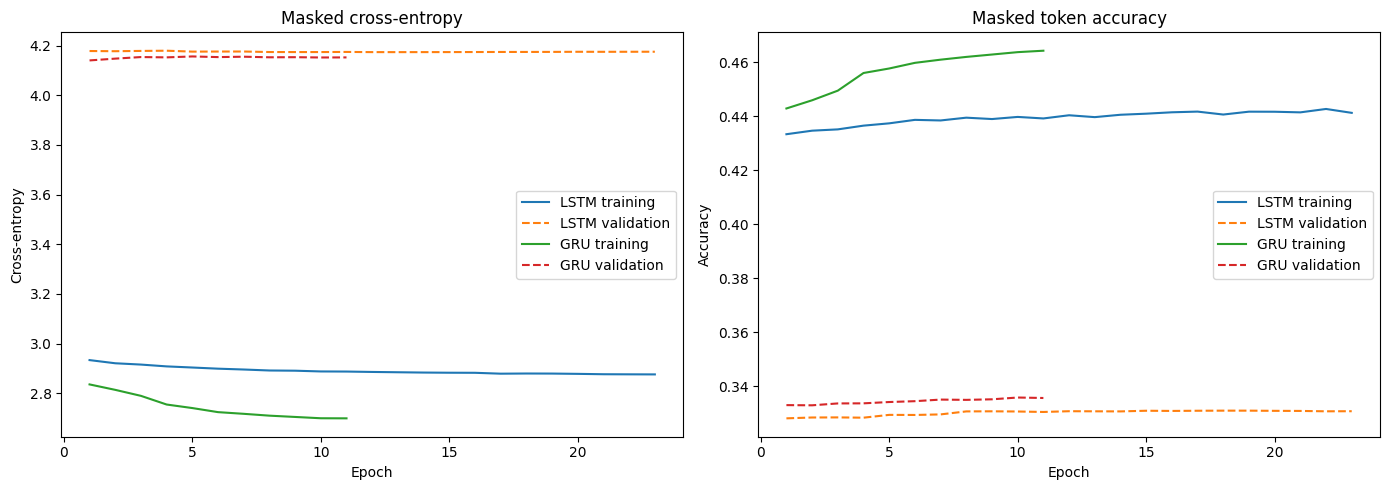

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model_name, history in baseline_histories.items():
    epochs = range(1, len(history.history["loss"]) + 1)

    axes[0].plot(
        epochs,
        history.history["masked_crossentropy"],
        label=f"{model_name} training",
    )
    axes[0].plot(
        epochs,
        history.history["val_masked_crossentropy"],
        linestyle="--",
        label=f"{model_name} validation",
    )

    axes[1].plot(
        epochs,
        history.history["masked_accuracy"],
        label=f"{model_name} training",
    )
    axes[1].plot(
        epochs,
        history.history["val_masked_accuracy"],
        linestyle="--",
        label=f"{model_name} validation",
    )

axes[0].set_title("Masked cross-entropy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")
axes[0].legend()

axes[1].set_title("Masked token accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### 6.7 Validation Comparison and Baseline Selection

The restored best weights are evaluated on the validation partition only. The primary selection criterion is the lowest masked cross-entropy, with perplexity providing the same ranking on a more interpretable scale. Masked accuracy, parameter count and training behaviour are supporting evidence. The test partition remains unused at this stage.

In [48]:
baseline_result_rows = []

for model_name, model in baseline_models.items():
    validation_metrics = model.evaluate(
        next_phrase_validation_dataset,
        return_dict=True,
        verbose=0,
    )
    history = baseline_histories[model_name].history
    best_epoch = int(
        np.argmin(history["val_masked_crossentropy"]) + 1
    )
    validation_crossentropy = float(
        validation_metrics["masked_crossentropy"]
    )

    baseline_result_rows.append(
        {
            "model": model_name,
            "best_epoch": best_epoch,
            "parameters": model.count_params(),
            "validation_masked_crossentropy": validation_crossentropy,
            "validation_perplexity": float(
                np.exp(min(validation_crossentropy, 50.0))
            ),
            "validation_masked_accuracy": float(
                validation_metrics["masked_accuracy"]
            ),
        }
    )

baseline_comparison = (
    pd.DataFrame(baseline_result_rows)
    .sort_values("validation_masked_crossentropy")
    .reset_index(drop=True)
)

selected_baseline_name = baseline_comparison.loc[0, "model"]
selected_baseline_model = baseline_models[selected_baseline_name]

display(baseline_comparison)

,model,best_epoch,parameters,validation_masked_crossentropy,validation_perplexity,validation_masked_accuracy
0,GRU,1,2121123,4.140072,62.807335,0.333021
1,LSTM,13,2316707,4.173422,64.937279,0.330728


### 6.8 Post-Training Generation Metrics

The completed LSTM and GRU checkpoints are evaluated without retraining. Reference-overlap measures such as BLEU, ROUGE-L and chrF are not used because they can penalise a new but valid poetic continuation and encourage imitation of the single reference. Instead, six measures focus on generation behaviour:

1. **Correct termination rate:** percentage of outputs that produce either `<PHRASE_END>` or `<STANZA_END>` within the permitted decoder length.
2. **Phrase-length distribution divergence:** Jensen–Shannon divergence between generated and real validation phrase-length distributions; lower is better. The percentages of 3-, 4- and 5-syllable outputs are also shown rather than enforcing four syllables.
3. **Rhyme consistency rate:** percentage of generated phrases containing a syllable whose preliminary orthographic rhyme key matches the input phrase ending. The matching position is flexible because Burmese poetry can use internal rhyme. This remains a proxy until a validated phonetic rhyme analyser is developed.
4. **Continuation MRR:** mean reciprocal rank of the genuine continuation among ten length-matched candidates.
5. **Continuation Recall@5:** percentage of prompts for which the genuine continuation appears among the five highest-scored candidates.
6. **Repetition-loop rate:** percentage of outputs containing an abnormal repeated pattern, such as one syllable repeated three times or a two-to-three-syllable sequence repeated immediately. Lower is better.

All six measures use validation data for baseline comparison. The test partition remains untouched.

In [49]:
# Reuse the architectures built above and reload the saved checkpoints.
# This makes evaluation independent of the training cell and does not retrain.
baseline_models = {"LSTM": lstm_baseline, "GRU": gru_baseline}

checkpoint_directory = Path("model_checkpoints")
checkpoint_paths = {
    "LSTM": checkpoint_directory / "lstm_best.weights.h5",
    "GRU": checkpoint_directory / "gru_best.weights.h5",
}

for model_name, checkpoint_path in checkpoint_paths.items():
    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Missing trained checkpoint: {checkpoint_path.resolve()}"
        )
    baseline_models[model_name].load_weights(checkpoint_path)


def greedy_generate_next_phrase(model, encoder_inputs, batch_size=256):
    maximum_length = prepared_task_data[BASELINE_TASK][
        "decoder_max_length"
    ]
    generated = np.full(
        (len(encoder_inputs), maximum_length), PAD_ID, dtype=np.int32
    )

    for batch_start in range(0, len(encoder_inputs), batch_size):
        batch_end = min(batch_start + batch_size, len(encoder_inputs))
        encoder_batch = encoder_inputs[batch_start:batch_end]
        batch_size_actual = len(encoder_batch)
        decoder_batch = np.full(
            (batch_size_actual, maximum_length), PAD_ID, dtype=np.int32
        )
        decoder_batch[:, 0] = START_ID
        batch_generated = np.full_like(decoder_batch, PAD_ID)
        finished = np.zeros(batch_size_actual, dtype=bool)

        for step in range(maximum_length):
            probabilities = model(
                {
                    "encoder_input": encoder_batch,
                    "decoder_input": decoder_batch,
                },
                training=False,
            )
            next_ids = tf.argmax(
                probabilities[:, step, :], axis=-1
            ).numpy().astype(np.int32)
            next_ids = np.where(finished, PAD_ID, next_ids)
            batch_generated[:, step] = next_ids

            newly_finished = np.isin(
                next_ids, [PAD_ID, PHRASE_END_ID, STANZA_END_ID]
            )
            finished = np.logical_or(finished, newly_finished)

            if step + 1 < maximum_length:
                decoder_batch[:, step + 1] = np.where(
                    finished, PAD_ID, next_ids
                )

            if finished.all():
                break

        generated[batch_start:batch_end] = batch_generated

    return generated


def content_ids(sequence):
    content = []
    for token_id in sequence:
        token_id = int(token_id)
        if token_id in {PAD_ID, PHRASE_END_ID, STANZA_END_ID}:
            break
        if token_id != START_ID:
            content.append(token_id)
    return content


def orthographic_rhyme_key(syllable):
    syllable = unicodedata.normalize("NFC", syllable)
    if not syllable:
        return None

    characters = list(syllable)
    if re.fullmatch(r"[က-အ]", characters[0]):
        characters = characters[1:]

    while characters and characters[0] in {"ျ", "ြ", "ွ", "ှ"}:
        characters.pop(0)

    # Tone marks are ignored for this preliminary broad rhyme class.
    rhyme = "".join(
        character for character in characters if character not in {"့", "း"}
    )
    return rhyme or "<INHERENT_VOWEL>"


def contains_repetition_loop(tokens):
    if any(
        tokens[index] == tokens[index + 1] == tokens[index + 2]
        for index in range(max(0, len(tokens) - 2))
    ):
        return True

    for width in (2, 3):
        for index in range(len(tokens) - 2 * width + 1):
            if (
                tokens[index:index + width]
                == tokens[index + width:index + 2 * width]
            ):
                return True
    return False


def jensen_shannon_divergence(reference_lengths, generated_lengths):
    maximum_length = max(max(reference_lengths), max(generated_lengths))
    reference_distribution = np.bincount(
        reference_lengths, minlength=maximum_length + 1
    ).astype("float64")
    generated_distribution = np.bincount(
        generated_lengths, minlength=maximum_length + 1
    ).astype("float64")
    reference_distribution /= reference_distribution.sum()
    generated_distribution /= generated_distribution.sum()
    midpoint = (reference_distribution + generated_distribution) / 2

    def kl_divergence(distribution, comparison):
        nonzero = distribution > 0
        return np.sum(
            distribution[nonzero]
            * np.log2(distribution[nonzero] / comparison[nonzero])
        )

    return 0.5 * (
        kl_divergence(reference_distribution, midpoint)
        + kl_divergence(generated_distribution, midpoint)
    )


validation_arrays = prepared_task_data[BASELINE_TASK]["validation"]
validation_encoder = validation_arrays["encoder_input"]
validation_targets = validation_arrays["decoder_target"]
reference_contents = [content_ids(row) for row in validation_targets]
reference_lengths = [len(tokens) for tokens in reference_contents]

baseline_validation_generations = {}
generation_metric_rows = []
phrase_length_rows = []

for model_name, model in baseline_models.items():
    generated_ids = greedy_generate_next_phrase(model, validation_encoder)
    baseline_validation_generations[model_name] = generated_ids
    generated_contents = [content_ids(row) for row in generated_ids]
    generated_lengths = [len(tokens) for tokens in generated_contents]

    correct_terminations = [
        (PHRASE_END_ID in row) or (STANZA_END_ID in row)
        for row in generated_ids
    ]
    length_divergence = jensen_shannon_divergence(
        reference_lengths, generated_lengths
    )

    rhyme_matches = []
    repetition_loops = []
    for encoder_row, generated_content in zip(
        validation_encoder, generated_contents
    ):
        input_content = content_ids(encoder_row)
        if not input_content or not generated_content:
            rhyme_matches.append(False)
        else:
            input_key = orthographic_rhyme_key(
                id_to_token[input_content[-1]]
            )
            generated_keys = {
                orthographic_rhyme_key(id_to_token[token_id])
                for token_id in generated_content
            }
            rhyme_matches.append(input_key in generated_keys)

        repetition_loops.append(
            contains_repetition_loop(generated_content)
        )

    generation_metric_rows.append(
        {
            "model": model_name,
            "correct_termination_percent": np.mean(correct_terminations) * 100,
            "phrase_length_js_divergence": length_divergence,
            "rhyme_consistency_percent": np.mean(rhyme_matches) * 100,
            "repetition_loop_percent": np.mean(repetition_loops) * 100,
        }
    )

    for syllable_length in [3, 4, 5]:
        phrase_length_rows.append(
            {
                "model": model_name,
                "syllable_length": syllable_length,
                "generated_percentage": (
                    np.mean(np.array(generated_lengths) == syllable_length) * 100
                ),
                "reference_percentage": (
                    np.mean(np.array(reference_lengths) == syllable_length) * 100
                ),
            }
        )

generation_metrics = pd.DataFrame(generation_metric_rows)
phrase_length_comparison = pd.DataFrame(phrase_length_rows)
display(generation_metrics)
display(phrase_length_comparison)

,model,correct_termination_percent,phrase_length_js_divergence,rhyme_consistency_percent,repetition_loop_percent
0,LSTM,100.0,0.007851,49.143154,3.583175
1,GRU,100.0,0.007850,52.155098,3.444694


,model,syllable_length,generated_percentage,reference_percentage
0,LSTM,3,7.200969,10.870694
1,LSTM,4,87.502164,83.018868
2,LSTM,5,3.790895,2.908084
3,GRU,3,8.603081,10.870694
4,GRU,4,84.888350,83.018868
5,GRU,5,5.106457,2.908084


In [50]:
RANKING_SAMPLE_SIZE = min(500, len(validation_encoder))
CANDIDATES_PER_PROMPT = 10
ranking_rng = np.random.default_rng(SEED)
ranking_query_indices = ranking_rng.choice(
    len(validation_encoder), size=RANKING_SAMPLE_SIZE, replace=False
)
validation_decoder_inputs = validation_arrays["decoder_input"]
target_keys = [tuple(row.tolist()) for row in validation_targets]
target_lengths = np.array(reference_lengths)

candidate_query_indices = []
candidate_target_indices = []

for query_index in ranking_query_indices:
    genuine_key = target_keys[query_index]
    length_distance = np.abs(target_lengths - target_lengths[query_index])
    candidate_pool = np.where(length_distance <= 1)[0]
    candidate_pool = np.array(
        [
            index
            for index in candidate_pool
            if index != query_index and target_keys[index] != genuine_key
        ],
        dtype=int,
    )

    if len(candidate_pool) < CANDIDATES_PER_PROMPT - 1:
        candidate_pool = np.array(
            [
                index
                for index in range(len(validation_targets))
                if index != query_index and target_keys[index] != genuine_key
            ],
            dtype=int,
        )

    distractors = ranking_rng.choice(
        candidate_pool,
        size=CANDIDATES_PER_PROMPT - 1,
        replace=False,
    )
    selected_targets = np.concatenate(([query_index], distractors))

    candidate_query_indices.extend(
        [query_index] * CANDIDATES_PER_PROMPT
    )
    candidate_target_indices.extend(selected_targets.tolist())

candidate_query_indices = np.array(candidate_query_indices)
candidate_target_indices = np.array(candidate_target_indices)
ranking_encoder = validation_encoder[candidate_query_indices]
ranking_decoder_input = validation_decoder_inputs[candidate_target_indices]
ranking_target = validation_targets[candidate_target_indices]


def length_normalised_candidate_scores(
    model, encoder_input, decoder_input, decoder_target, batch_size=128
):
    scores = []

    for batch_start in range(0, len(encoder_input), batch_size):
        batch_end = min(batch_start + batch_size, len(encoder_input))
        target_batch = decoder_target[batch_start:batch_end]
        probabilities = model(
            {
                "encoder_input": encoder_input[batch_start:batch_end],
                "decoder_input": decoder_input[batch_start:batch_end],
            },
            training=False,
        ).numpy()

        token_probabilities = np.take_along_axis(
            probabilities, target_batch[..., None], axis=-1
        ).squeeze(-1)
        mask = target_batch != PAD_ID
        log_probabilities = np.log(
            np.clip(token_probabilities, 1e-9, 1.0)
        )
        batch_scores = (log_probabilities * mask).sum(axis=1) / mask.sum(axis=1)
        scores.extend(batch_scores.tolist())

    return np.array(scores)


ranking_rows = []
for model_name, model in baseline_models.items():
    candidate_scores = length_normalised_candidate_scores(
        model, ranking_encoder, ranking_decoder_input, ranking_target
    ).reshape(RANKING_SAMPLE_SIZE, CANDIDATES_PER_PROMPT)

    # The genuine continuation is candidate zero for every prompt.
    genuine_ranks = 1 + np.sum(
        candidate_scores[:, 1:] > candidate_scores[:, [0]], axis=1
    )
    ranking_rows.append(
        {
            "model": model_name,
            "continuation_mrr": np.mean(1.0 / genuine_ranks),
            "continuation_recall_at_5": np.mean(genuine_ranks <= 5) * 100,
        }
    )

ranking_metrics = pd.DataFrame(ranking_rows)
post_training_comparison = generation_metrics.merge(
    ranking_metrics, on="model", how="left"
)
display(post_training_comparison)

,model,correct_termination_percent,phrase_length_js_divergence,rhyme_consistency_percent,repetition_loop_percent,continuation_mrr,continuation_recall_at_5
0,LSTM,100.0,0.007851,49.143154,3.583175,0.499206,72.4
1,GRU,100.0,0.007850,52.155098,3.444694,0.520876,74.2


### 6.9 Interactive Human Test and Optional Written Feedback

Human judgement is added because structural metrics cannot determine whether a continuation is meaningful, natural or poetically appropriate. The input–output window accepts either a manually entered Burmese phrase or, when left blank, a randomly selected validation prompt. It presents anonymous LSTM and GRU outputs as A and B in random order. For each model, the table shows one generated phrase, exactly three recursively generated phrases and continuation toward the predicted stanza end. The fixed three-phrase view continues to three phrases even when an earlier `<STANZA_END>` is predicted; the stanza-end view respects the first ending signal and otherwise uses a 20-phrase safety limit. These are repeated uses of the trained next-phrase model, not separately trained models.

Each output set is rated from 1 (very poor) to 5 (very good) for fluency, relevance, phrase structure, rhyme, classical style and overall quality. The kernel remains busy while the notebook waits for these `input()` responses. Written feedback is optional and can be skipped by pressing Enter. Model identities remain hidden until submission, after which the ratings are displayed immediately as a table. Responses are appended to `human_feedback_responses.csv`.

In [17]:
HUMAN_FEEDBACK_PATH = Path("human_feedback_responses.csv")

HUMAN_RATING_CRITERIA = [
    "fluency",
    "relevance",
    "structure",
    "rhyme",
    "classical_style",
    "overall",
]

human_feedback_rng = np.random.default_rng(SEED)


def render_content(sequence):
    return "".join(
        id_to_token[token_id]
        for token_id in content_ids(sequence)
    )


def generate_one_phrase_with_stanza_signal(model, encoder_row):
    """Generate one phrase; either boundary token terminates decoding."""

    decoder_row = np.full(
        (1, baseline_decoder_length),
        PAD_ID,
        dtype=np.int32,
    )
    decoder_row[:, 0] = START_ID

    generated_tokens = []
    stanza_has_ended = False

    for step in range(baseline_decoder_length):
        probabilities = model(
            {
                "encoder_input": encoder_row,
                "decoder_input": decoder_row,
            },
            training=False,
        )

        next_id = int(
            tf.argmax(probabilities[0, step]).numpy()
        )

        if next_id == STANZA_END_ID:
            stanza_has_ended = True
            break

        if next_id in {PHRASE_END_ID, PAD_ID}:
            break

        generated_tokens.append(next_id)

        if step + 1 < baseline_decoder_length:
            decoder_row[:, step + 1] = next_id

    return generated_tokens, stanza_has_ended


def generate_continuation_views(
    model,
    initial_encoder_row,
    maximum_phrases=20,
):
    current_encoder = initial_encoder_row.copy()
    generated_phrases = []
    first_stanza_end_position = None

    for _ in range(maximum_phrases):
        phrase_ids, phrase_ends_stanza = (
            generate_one_phrase_with_stanza_signal(
                model,
                current_encoder,
            )
        )

        if not phrase_ids:
            break

        phrase_text = "".join(
            id_to_token[token_id]
            for token_id in phrase_ids
        )
        generated_phrases.append(phrase_text)

        if (
            phrase_ends_stanza
            and first_stanza_end_position is None
        ):
            first_stanza_end_position = len(
                generated_phrases
            )

        next_encoder_ids = phrase_ids + [PHRASE_END_ID]

        current_encoder = pad_sequences(
            [next_encoder_ids],
            maxlen=baseline_encoder_length,
            padding="post",
            truncating="post",
            value=PAD_ID,
        ).astype("int32")

        # Always generate three phrases for the fixed
        # three-phrase view. The stanza-ending view still
        # respects the first predicted stanza-ending signal.
        if (
            first_stanza_end_position is not None
            and len(generated_phrases) >= 3
        ):
            break

    def format_phrases(phrases, ended=False):
        if not phrases:
            return "[no phrase generated]"

        punctuation = ["၊"] * len(phrases)

        if ended:
            punctuation[-1] = "။"

        return " ".join(
            phrase + mark
            for phrase, mark in zip(
                phrases,
                punctuation,
            )
        )

    next_phrase = format_phrases(
        generated_phrases[:1]
    )
    next_three = format_phrases(
        generated_phrases[:3]
    )

    reached_stanza_end = (
        first_stanza_end_position is not None
    )

    if reached_stanza_end:
        stanza_phrases = generated_phrases[
            :first_stanza_end_position
        ]
    else:
        stanza_phrases = generated_phrases

    to_stanza_end = format_phrases(
        stanza_phrases,
        reached_stanza_end,
    )

    if (
        not reached_stanza_end
        and len(generated_phrases) >= maximum_phrases
    ):
        to_stanza_end += (
            f" [stopped at "
            f"{maximum_phrases}-phrase safety limit]"
        )

    return {
        "next_phrase": next_phrase,
        "next_three_phrases": next_three,
        "to_stanza_end": to_stanza_end,
        "reached_stanza_end": reached_stanza_end,
        "generated_phrase_count": len(stanza_phrases),
    }


def request_rating_vector(output_label):
    while True:
        raw_value = input(
            f"Rate output {output_label} from 1-5 for "
            "fluency,relevance,structure,rhyme,"
            "classical_style,overall: "
        )

        try:
            ratings = [
                int(value.strip())
                for value in raw_value.split(",")
            ]
        except ValueError:
            ratings = []

        valid_ratings = (
            len(ratings)
            == len(HUMAN_RATING_CRITERIA)
            and all(
                1 <= rating <= 5
                for rating in ratings
            )
        )

        if valid_ratings:
            return dict(
                zip(
                    HUMAN_RATING_CRITERIA,
                    ratings,
                )
            )

        print(
            "Enter six comma-separated integers, "
            "for example: 4,4,3,3,4,4"
        )


def human_feedback_window():
    typed_phrase = input(
        "Enter one complete Burmese phrase, "
        "or press Enter for a validation prompt: "
    ).strip()

    if typed_phrase:
        cleaned_phrase = clean_poetry_phrase(
            typed_phrase
        )

        if cleaned_phrase is None:
            print(
                "The supplied phrase contains "
                "no usable Burmese text."
            )
            return None

        syllables = split_myanmar_syllables(
            cleaned_phrase
        )

        encoder_ids = encode_tokens(
            syllables + ["<PHRASE_END>"]
        )

        if len(encoder_ids) > baseline_encoder_length:
            print(
                f"Input has {len(encoder_ids)} tokens; "
                f"the model maximum is "
                f"{baseline_encoder_length}. "
                "The phrase was not truncated."
            )
            return None

        encoder_row = pad_sequences(
            [encoder_ids],
            maxlen=baseline_encoder_length,
            padding="post",
            value=PAD_ID,
        ).astype("int32")

        displayed_input = cleaned_phrase
        prompt_source = "manual"
        source_stanza_id = None
        input_phrase_position = None

    else:
        validation_index = int(
            human_feedback_rng.integers(
                0,
                len(validation_encoder),
            )
        )

        encoder_row = validation_encoder[
            validation_index:validation_index + 1
        ]

        displayed_input = render_content(
            encoder_row[0]
        )

        prompt_source = "validation"

        metadata_row = validation_arrays[
            "metadata"
        ].iloc[validation_index]

        source_stanza_id = int(
            metadata_row["source_stanza_id"]
        )
        input_phrase_position = int(
            metadata_row["input_phrase_position"]
        )

    model_outputs = {
        model_name: generate_continuation_views(
            model,
            encoder_row,
        )
        for model_name, model
        in baseline_models.items()
    }

    model_order = human_feedback_rng.permutation(
        ["LSTM", "GRU"]
    )
    model_a, model_b = model_order.tolist()

    display(
        Markdown(
            f"### Human Evaluation Window\n\n"
            f"**Input:** {displayed_input}\n\n"
            f"| Continuation view | Output A | Output B |\n"
            f"|---|---|---|\n"
            f"| Next phrase | "
            f"{model_outputs[model_a]['next_phrase']} | "
            f"{model_outputs[model_b]['next_phrase']} |\n"
            f"| Next three phrases | "
            f"{model_outputs[model_a]['next_three_phrases']} | "
            f"{model_outputs[model_b]['next_three_phrases']} |\n"
            f"| Toward stanza end | "
            f"{model_outputs[model_a]['to_stanza_end']} | "
            f"{model_outputs[model_b]['to_stanza_end']} |"
        )
    )

    ratings_a = request_rating_vector("A")
    ratings_b = request_rating_vector("B")

    while True:
        preference = input(
            "Preference (A/B/Tie/Neither): "
        ).strip().title()

        if preference in {
            "A",
            "B",
            "Tie",
            "Neither",
        }:
            break

        print(
            "Enter A, B, Tie or Neither."
        )

    written_feedback = input(
        "Optional written feedback "
        "(press Enter to skip): "
    ).strip()

    response = {
        "evaluation_id": (
            pd.Timestamp.utcnow().isoformat()
        ),
        "prompt_source": prompt_source,
        "source_stanza_id": source_stanza_id,
        "input_phrase_position": (
            input_phrase_position
        ),
        "input_phrase": displayed_input,
        "output_a_next_phrase": (
            model_outputs[model_a]["next_phrase"]
        ),
        "output_b_next_phrase": (
            model_outputs[model_b]["next_phrase"]
        ),
        "output_a_next_three": (
            model_outputs[model_a][
                "next_three_phrases"
            ]
        ),
        "output_b_next_three": (
            model_outputs[model_b][
                "next_three_phrases"
            ]
        ),
        "output_a_to_stanza_end": (
            model_outputs[model_a][
                "to_stanza_end"
            ]
        ),
        "output_b_to_stanza_end": (
            model_outputs[model_b][
                "to_stanza_end"
            ]
        ),
        "model_a": model_a,
        "model_b": model_b,
        "preference": preference,
        "written_feedback": written_feedback,
    }

    response.update(
        {
            f"a_{key}": value
            for key, value in ratings_a.items()
        }
    )
    response.update(
        {
            f"b_{key}": value
            for key, value in ratings_b.items()
        }
    )

    response_df = pd.DataFrame([response])

    if HUMAN_FEEDBACK_PATH.exists():
        previous_responses = pd.read_csv(
            HUMAN_FEEDBACK_PATH
        )

        response_df = pd.concat(
            [
                previous_responses,
                response_df,
            ],
            ignore_index=True,
        )

    response_df.to_csv(
        HUMAN_FEEDBACK_PATH,
        index=False,
        encoding="utf-8-sig",
    )

    submitted_summary = pd.DataFrame(
        [
            {
                "anonymous_output": "A",
                **ratings_a,
                "selected_preference": (
                    preference in {"A", "Tie"}
                ),
            },
            {
                "anonymous_output": "B",
                **ratings_b,
                "selected_preference": (
                    preference in {"B", "Tie"}
                ),
            },
        ]
    )

    display(submitted_summary)

    print(
        f"Feedback saved. "
        f"Hidden mapping: A={model_a}, B={model_b}. "
        f"Total responses: {len(response_df)}"
    )

    # Return None so Jupyter does not display
    # the complete response dictionary.
    return None


def summarise_human_feedback():
    if not HUMAN_FEEDBACK_PATH.exists():
        print(
            "No human-feedback responses "
            "have been saved yet."
        )
        return None

    responses = pd.read_csv(
        HUMAN_FEEDBACK_PATH
    )

    rating_rows = []
    preference_rows = []

    for response in responses.itertuples(
        index=False
    ):
        for label, model_name in [
            ("a", response.model_a),
            ("b", response.model_b),
        ]:
            row = {"model": model_name}

            for criterion in HUMAN_RATING_CRITERIA:
                row[criterion] = getattr(
                    response,
                    f"{label}_{criterion}",
                )

            rating_rows.append(row)

        if response.preference == "A":
            preference_rows.append(
                response.model_a
            )
        elif response.preference == "B":
            preference_rows.append(
                response.model_b
            )

    rating_summary = (
        pd.DataFrame(rating_rows)
        .groupby("model")[
            HUMAN_RATING_CRITERIA
        ]
        .mean()
    )

    preference_summary = (
        pd.Series(preference_rows)
        .value_counts()
        .rename("wins")
    )

    display(
        rating_summary.join(
            preference_summary,
            how="left",
        ).fillna(0)
    )

    display(
        responses[
            [
                "input_phrase",
                "preference",
                "written_feedback",
            ]
        ]
    )

    return None


print(
    "Run human_feedback_window() to generate "
    "and rate one anonymous A/B review."
)
print(
    "Run it repeatedly for more reviews, then "
    "run summarise_human_feedback()."
)

Run human_feedback_window() to generate and rate one anonymous A/B review.
Run it repeatedly for more reviews, then run summarise_human_feedback().


### 6.10 Generated-versus-Actual Validation Comparison

This diagnostic samples a validation position for which the genuine continuation to the sequence ending is available. The actual next phrase, next three phrases and remaining sequence are shown beside both model outputs. Model names can remain anonymous, and human ratings are optional. The reference is one historically observed continuation rather than the only acceptable poetic answer.

In [15]:
VALIDATION_COMPARISON_FEEDBACK_PATH = Path(
    "validation_comparison_feedback.csv"
)
validation_comparison_rng = np.random.default_rng(SEED + 1)


def format_reference_phrases(phrase_groups, reaches_stanza_end=False):
    if not phrase_groups:
        return "[no continuation available]"

    phrase_texts = ["".join(phrase) for phrase in phrase_groups]
    punctuation = ["၊"] * len(phrase_texts)
    if reaches_stanza_end:
        punctuation[-1] = "။"

    return " ".join(
        phrase + mark
        for phrase, mark in zip(phrase_texts, punctuation)
    )


def validation_comparison_window(
    anonymous=True,
    collect_feedback=False,
    validation_index=None,
):
    eligible_examples = task_datasets["to_sequence_end"].loc[
        (task_datasets["to_sequence_end"]["split"] == "validation")
        & (
            task_datasets["to_sequence_end"]["encoder_length"]
            <= baseline_encoder_length
        )
    ].reset_index(drop=True)

    if eligible_examples.empty:
        raise ValueError("No eligible validation continuations were found.")

    if validation_index is None:
        selected_index = int(
            validation_comparison_rng.integers(0, len(eligible_examples))
        )
    else:
        selected_index = int(validation_index)
        if not 0 <= selected_index < len(eligible_examples):
            raise IndexError(
                f"validation_index must be from 0 to "
                f"{len(eligible_examples) - 1}."
            )

    selected = eligible_examples.iloc[selected_index]
    stanza_id = int(selected["source_stanza_id"])
    input_position = int(selected["input_phrase_position"])

    stanza_matches = preprocessed_stanzas_df.loc[
        preprocessed_stanzas_df["source_stanza_id"] == stanza_id
    ]
    if len(stanza_matches) != 1:
        raise ValueError(
            f"Expected one reconstructed stanza for ID {stanza_id}; "
            f"found {len(stanza_matches)}."
        )

    phrase_groups = stanza_matches.iloc[0]["syllable_phrases"]
    input_phrase_tokens = phrase_groups[input_position - 1]
    remaining_phrase_groups = phrase_groups[input_position:]

    encoder_ids = encode_tokens(
        input_phrase_tokens + ["<PHRASE_END>"]
    )
    encoder_row = pad_sequences(
        [encoder_ids],
        maxlen=baseline_encoder_length,
        padding="post",
        value=PAD_ID,
    ).astype("int32")

    actual_views = {
        "next_phrase": format_reference_phrases(
            remaining_phrase_groups[:1],
            reaches_stanza_end=len(remaining_phrase_groups) <= 1,
        ),
        "next_three_phrases": format_reference_phrases(
            remaining_phrase_groups[:3],
            reaches_stanza_end=len(remaining_phrase_groups) <= 3,
        ),
        "to_stanza_end": format_reference_phrases(
            remaining_phrase_groups, reaches_stanza_end=True
        ),
    }

    generated_views = {
        model_name: generate_continuation_views(model, encoder_row)
        for model_name, model in baseline_models.items()
    }

    if anonymous:
        model_order = validation_comparison_rng.permutation(
            ["LSTM", "GRU"]
        ).tolist()
        left_model, right_model = model_order
        left_label, right_label = "Output A", "Output B"
    else:
        left_model, right_model = "LSTM", "GRU"
        left_label, right_label = "LSTM", "GRU"

    displayed_input = "".join(input_phrase_tokens)
    display(
        Markdown(
            f"### Validation Comparison\n\n"
            f"**Input:** {displayed_input}\n\n"
            f"| Continuation view | Actual validation text | "
            f"{left_label} | {right_label} |\n"
            f"|---|---|---|---|\n"
            f"| Next phrase | {actual_views['next_phrase']} | "
            f"{generated_views[left_model]['next_phrase']} | "
            f"{generated_views[right_model]['next_phrase']} |\n"
            f"| Next three phrases | "
            f"{actual_views['next_three_phrases']} | "
            f"{generated_views[left_model]['next_three_phrases']} | "
            f"{generated_views[right_model]['next_three_phrases']} |\n"
            f"| Toward stanza end | {actual_views['to_stanza_end']} | "
            f"{generated_views[left_model]['to_stanza_end']} | "
            f"{generated_views[right_model]['to_stanza_end']} |"
        )
    )

    if not collect_feedback:
        print(
            f"Validation example {selected_index}; stanza ID {stanza_id}, "
            f"input position {input_position}."
        )
        return None

    ratings_left = request_rating_vector(left_label)
    ratings_right = request_rating_vector(right_label)
    allowed_preferences = {left_label, right_label, "Tie", "Neither"}
    while True:
        preference = input(
            f"Preference ({left_label}/{right_label}/Tie/Neither): "
        ).strip()
        matched_preference = next(
            (
                option
                for option in allowed_preferences
                if preference.casefold() == option.casefold()
            ),
            None,
        )
        if matched_preference is not None:
            preference = matched_preference
            break
        print("Enter one of the displayed choices.")

    written_feedback = input(
        "Optional written feedback (press Enter to skip): "
    ).strip()
    feedback_row = {
        "evaluation_id": pd.Timestamp.utcnow().isoformat(),
        "validation_index": selected_index,
        "source_stanza_id": stanza_id,
        "input_phrase_position": input_position,
        "input_phrase": displayed_input,
        "actual_next_phrase": actual_views["next_phrase"],
        "actual_next_three": actual_views["next_three_phrases"],
        "actual_to_stanza_end": actual_views["to_stanza_end"],
        "left_label": left_label,
        "right_label": right_label,
        "left_model": left_model,
        "right_model": right_model,
        "preference": preference,
        "written_feedback": written_feedback,
    }
    feedback_row.update(
        {f"left_{key}": value for key, value in ratings_left.items()}
    )
    feedback_row.update(
        {f"right_{key}": value for key, value in ratings_right.items()}
    )

    feedback_df = pd.DataFrame([feedback_row])
    if VALIDATION_COMPARISON_FEEDBACK_PATH.exists():
        previous_feedback = pd.read_csv(
            VALIDATION_COMPARISON_FEEDBACK_PATH
        )
        feedback_df = pd.concat(
            [previous_feedback, feedback_df], ignore_index=True
        )
    feedback_df.to_csv(
        VALIDATION_COMPARISON_FEEDBACK_PATH,
        index=False,
        encoding="utf-8-sig",
    )

    submitted_summary = pd.DataFrame(
        [
            {"output": left_label, **ratings_left},
            {"output": right_label, **ratings_right},
        ]
    )
    display(submitted_summary)
    print(
        f"Feedback saved. Mapping: {left_label}={left_model}, "
        f"{right_label}={right_model}. Total responses: {len(feedback_df)}"
    )
    return None


print("Comparison only: validation_comparison_window()")
print("Named models: validation_comparison_window(anonymous=False)")
print(
    "Optional rating: "
    "validation_comparison_window(collect_feedback=True)"
)


Comparison only: validation_comparison_window()
Named models: validation_comparison_window(anonymous=False)
Optional rating: validation_comparison_window(collect_feedback=True)


## 7. GRU with Additive Attention and Four-Phrase Context

The GRU is selected for the next experiment because it achieved the stronger validation cross-entropy, perplexity, rhyme consistency, continuation MRR and Recall@5 while using fewer parameters than the LSTM. Human preference was less decisive, so the LSTM remains a useful baseline rather than being treated as conclusively inferior.

Simply adding more recurrent layers is not the first improvement because the existing training–validation gap suggests a generalisation problem rather than clear under-capacity. A more promising coherence improvement is to give the encoder the previous **one to four complete phrases** instead of only the immediately preceding phrase. Four phrases allow the encoder to observe a rhyme sequence that may resolve around the third phrase before predicting what follows. Additive attention can then learn which syllables and phrase positions in this context are most relevant to the next phrase.

The improved model remains a left-to-right GRU decoder. It predicts one next phrase ending in either `<PHRASE_END>` or `<STANZA_END>`. During generation, each predicted phrase is added to the rolling four-phrase context and generation repeats until `<STANZA_END>` is produced or a 20-phrase safety limit is reached. Evaluation still reports the generated **next phrase**, **next three phrases** and continuation **toward the end of the stanza**, while preserving flexible phrase and stanza lengths.

### 7.1 Construct Rolling Four-Phrase Context Pairs

Each example uses up to four consecutive phrases ending at the current phrase as encoder context. The decoder target is the genuine next phrase. The final target phrase ends directly with `<STANZA_END>`; all other targets end with `<PHRASE_END>`. Complete stanzas remain in their existing train, validation or test partition.

In [6]:
CONTEXT_PHRASE_COUNT = 4
context_records = []

for stanza in preprocessed_stanzas_df.itertuples(index=False):
    phrase_groups = stanza.syllable_phrases
    phrase_total = len(phrase_groups)

    for input_index in range(phrase_total - 1):
        context_start = max(0, input_index - CONTEXT_PHRASE_COUNT + 1)
        context_groups = phrase_groups[context_start:input_index + 1]
        encoder_tokens = []
        for phrase_syllables in context_groups:
            encoder_tokens.extend(phrase_syllables)
            encoder_tokens.append("<PHRASE_END>")

        next_phrase = phrase_groups[input_index + 1]
        reaches_stanza_end = input_index + 2 >= phrase_total
        boundary_token = (
            "<STANZA_END>" if reaches_stanza_end else "<PHRASE_END>"
        )
        target_tokens = next_phrase + [boundary_token]

        context_records.append(
            {
                "split": stanza.split,
                "source_stanza_id": stanza.source_stanza_id,
                "input_phrase_position": input_index + 1,
                "context_phrase_count": len(context_groups),
                "encoder_tokens": encoder_tokens,
                "decoder_input_tokens": ["<START>"] + target_tokens[:-1],
                "decoder_target_tokens": target_tokens,
                "encoder_length": len(encoder_tokens),
                "decoder_length": len(target_tokens),
            }
        )

context_examples_df = pd.DataFrame(context_records)
del context_records

# Limit domination by exact repeated target phrases in training only.
MAX_TRAINING_COPIES_PER_TARGET = 10
context_examples_df["target_key"] = context_examples_df[
    "decoder_target_tokens"
].map(tuple)
context_training_rows = context_examples_df.loc[
    context_examples_df["split"] == "train"
].sample(frac=1, random_state=SEED)
context_training_rows = context_training_rows.groupby(
    "target_key", sort=False, group_keys=False
).head(MAX_TRAINING_COPIES_PER_TARGET)
context_non_training_rows = context_examples_df.loc[
    context_examples_df["split"] != "train"
]
removed_repeated_context_targets = int(
    (context_examples_df["split"] == "train").sum()
    - len(context_training_rows)
)
context_examples_df = pd.concat(
    [context_training_rows, context_non_training_rows], ignore_index=True
)

assert context_examples_df["decoder_target_tokens"].map(
    lambda tokens: tokens[-1] in {"<PHRASE_END>", "<STANZA_END>"}
).all()
assert context_examples_df["context_phrase_count"].between(
    1, CONTEXT_PHRASE_COUNT
).all()
print("Repeated training targets capped:", removed_repeated_context_targets)

display(
    context_examples_df.groupby(["split", "context_phrase_count"])
    .size()
    .rename("examples")
    .to_frame()
)


Repeated training targets capped: 138


examples
split      context_phrase_count          
test       1                          161
           2                          153
           3                          136
           4                         5242
train      1                         1281
           2                         1207
           3                         1123
           4                        42983
validation 1                          160
           2                          153
           3                          145
           4                         5325

### 7.2 Encode, Pad and Batch the Context Data

The existing training-only vocabulary is reused. Encoder and decoder maximum lengths are learned from the context-training partition, and validation examples exceeding those limits are excluded rather than truncated.

In [7]:
context_train_rows = context_examples_df.loc[
    context_examples_df["split"] == "train"
]
CONTEXT_ENCODER_LENGTH = int(context_train_rows["encoder_length"].max())
CONTEXT_DECODER_LENGTH = int(context_train_rows["decoder_length"].max())

context_arrays = {}
for split_name in ["train", "validation", "test"]:
    split_rows = context_examples_df.loc[
        context_examples_df["split"] == split_name
    ].copy()
    length_mask = (
        (split_rows["encoder_length"] <= CONTEXT_ENCODER_LENGTH)
        & (split_rows["decoder_length"] <= CONTEXT_DECODER_LENGTH)
    )
    split_rows = split_rows.loc[length_mask].reset_index(drop=True)

    context_arrays[split_name] = {
        "encoder_input": pad_sequences(
            split_rows["encoder_tokens"].map(encode_tokens),
            maxlen=CONTEXT_ENCODER_LENGTH, padding="post", value=PAD_ID,
        ).astype("int32"),
        "decoder_input": pad_sequences(
            split_rows["decoder_input_tokens"].map(encode_tokens),
            maxlen=CONTEXT_DECODER_LENGTH, padding="post", value=PAD_ID,
        ).astype("int32"),
        "decoder_target": pad_sequences(
            split_rows["decoder_target_tokens"].map(encode_tokens),
            maxlen=CONTEXT_DECODER_LENGTH, padding="post", value=PAD_ID,
        ).astype("int32"),
        "metadata": split_rows[["source_stanza_id", "input_phrase_position"]],
    }

def make_context_dataset(split_name, shuffle=False):
    arrays = context_arrays[split_name]
    dataset = tf.data.Dataset.from_tensor_slices(
        (
            {
                "context_encoder_input": arrays["encoder_input"],
                "context_decoder_input": arrays["decoder_input"],
            },
            arrays["decoder_target"],
        )
    )
    if shuffle:
        dataset = dataset.shuffle(
            min(SHUFFLE_BUFFER_SIZE, len(arrays["encoder_input"])),
            seed=SEED, reshuffle_each_iteration=True,
        )
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

context_train_dataset = make_context_dataset("train", shuffle=True)
context_validation_dataset = make_context_dataset("validation")
print("Context training examples:", len(context_arrays["train"]["encoder_input"]))
print("Encoder length:", CONTEXT_ENCODER_LENGTH)
print("Decoder length:", CONTEXT_DECODER_LENGTH)


Context training examples: 46594
Encoder length: 40
Decoder length: 13


### 7.3 Build the GRU Encoder–Decoder with Additive Attention

The encoder returns a hidden state for every context syllable. The autoregressive GRU decoder attends over those states at each output step. Embedding size, recurrent width and dropout remain aligned with the baseline so the architectural change is controlled.

In [8]:
def build_context_attention_gru():
    encoder_input = tf.keras.Input(
        shape=(CONTEXT_ENCODER_LENGTH,), dtype="int32",
        name="context_encoder_input",
    )
    decoder_input = tf.keras.Input(
        shape=(CONTEXT_DECODER_LENGTH,), dtype="int32",
        name="context_decoder_input",
    )

    encoder_embedding_layer = tf.keras.layers.Embedding(
        VOCABULARY_SIZE, EMBEDDING_DIM, mask_zero=True,
        name="attention_encoder_embedding",
    )
    decoder_embedding_layer = tf.keras.layers.Embedding(
        VOCABULARY_SIZE, EMBEDDING_DIM, mask_zero=True,
        name="attention_decoder_embedding",
    )
    encoder_embedding = encoder_embedding_layer(encoder_input)
    decoder_embedding = decoder_embedding_layer(decoder_input)
    encoder_mask = encoder_embedding_layer.compute_mask(encoder_input)
    decoder_mask = decoder_embedding_layer.compute_mask(decoder_input)

    encoder_outputs, encoder_state = tf.keras.layers.GRU(
        RECURRENT_UNITS, return_sequences=True, return_state=True,
        dropout=DROPOUT_RATE, name="attention_gru_encoder",
    )(encoder_embedding)
    decoder_outputs = tf.keras.layers.GRU(
        RECURRENT_UNITS, return_sequences=True,
        dropout=DROPOUT_RATE, name="attention_gru_decoder",
    )(decoder_embedding, initial_state=encoder_state)

    attention_context = tf.keras.layers.AdditiveAttention(
        name="additive_attention"
    )(
        [decoder_outputs, encoder_outputs],
        mask=[decoder_mask, encoder_mask],
    )
    combined = tf.keras.layers.Concatenate(
        name="decoder_attention_context"
    )([decoder_outputs, attention_context])
    probabilities = tf.keras.layers.Dense(
        VOCABULARY_SIZE, activation="softmax",
        name="attention_token_probabilities",
    )(combined)

    model = tf.keras.Model(
        [encoder_input, decoder_input], probabilities,
        name="four_phrase_context_gru_attention",
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE, clipnorm=1.0
        ),
        loss=masked_sparse_categorical_crossentropy,
        metrics=[MaskedTokenAccuracy(), MaskedTokenCrossentropy()],
    )
    return model

context_attention_gru = build_context_attention_gru()
context_attention_gru.summary()


Model: "four_phrase_context_gru_attention"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 context_encoder_input (InputLa  [(None, 40)]        0           []                               
 yer)                                                                                             
                                                                                                  
 context_decoder_input (InputLa  [(None, 13)]        0           []                               
 yer)                                                                                             
                                                                                                  
 attention_encoder_embedding (E  (None, 40, 128)     381312      ['context_encoder_input[0][0]']  
 mbedding)                                                        

### 7.4 Train and Save the Best Attention Checkpoint

Training uses the same early-stopping criterion as the baseline. Run the model-construction cell immediately before this cell to guarantee a fresh optimiser and randomly initialised attention model.

In [101]:
CONTEXT_ATTENTION_CHECKPOINT = (
    CHECKPOINT_DIRECTORY / "context_gru_attention_best.weights.h5"
)
context_attention_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_masked_crossentropy", mode="min",
        patience=10, restore_best_weights=True, verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_masked_crossentropy", mode="min",
        factor=0.5, patience=2, min_lr=1e-5, verbose=1,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        str(CONTEXT_ATTENTION_CHECKPOINT),
        monitor="val_masked_crossentropy", mode="min",
        save_best_only=True, save_weights_only=True, verbose=1,
    ),
]
context_attention_history = context_attention_gru.fit(
    context_train_dataset,
    validation_data=context_validation_dataset,
    epochs=40, callbacks=context_attention_callbacks, verbose=1,
)
context_attention_gru.load_weights(CONTEXT_ATTENTION_CHECKPOINT)


Epoch 1/40
365/365 [==============================] - ETA: 0s - loss: 2.0834 - masked_accuracy: 0.2096 - masked_crossentropy: 5.4066
Epoch 1: val_masked_crossentropy improved from inf to 5.18645, saving model to model_checkpoints\context_gru_attention_best.weights.h5
365/365 [==============================] - 26s 52ms/step - loss: 2.0834 - masked_accuracy: 0.2096 - masked_crossentropy: 5.4066 - val_loss: 1.9888 - val_masked_accuracy: 0.2156 - val_masked_crossentropy: 5.1865 - lr: 0.0010
Epoch 2/40
364/365 [============================>.] - ETA: 0s - loss: 1.9334 - masked_accuracy: 0.2235 - masked_crossentropy: 5.0173
Epoch 2: val_masked_crossentropy improved from 5.18645 to 4.92491, saving model to model_checkpoints\context_gru_attention_best.weights.h5
365/365 [==============================] - 17s 45ms/step - loss: 1.9334 - masked_accuracy: 0.2235 - masked_crossentropy: 5.0174 - val_loss: 1.8886 - val_masked_accuracy: 0.2359 - val_masked_crossentropy: 4.9249 - lr: 0.0010
Epoch 3/40
3

### 7.5 Validation Result and Repetition-Aware Stanza Generation

Validation likelihood measures next-phrase prediction with richer context. For free generation, top-k sampling avoids always choosing the single safest token, while a phrase-level rejection rule prevents an exact phrase from repeating within the same generated stanza. The random seed keeps experiments reproducible. These decoding controls improve diversity but do not replace human review.

In [19]:
attention_validation = context_attention_gru.evaluate(
    context_validation_dataset, verbose=0, return_dict=True
)
attention_validation["perplexity"] = float(
    np.exp(attention_validation["masked_crossentropy"])
)
display(pd.DataFrame([attention_validation], index=["GRU + context + attention"]))

def encode_context_phrases(context_phrases):
    tokens = []
    for phrase in context_phrases[-CONTEXT_PHRASE_COUNT:]:
        cleaned = clean_poetry_phrase(phrase)
        if cleaned is None:
            continue
        tokens.extend(split_myanmar_syllables(cleaned))
        tokens.append("<PHRASE_END>")
    ids = encode_tokens(tokens)[-CONTEXT_ENCODER_LENGTH:]
    return pad_sequences(
        [ids], maxlen=CONTEXT_ENCODER_LENGTH, padding="post",
        value=PAD_ID,
    ).astype("int32")

def sample_context_next_phrase(
    model, encoder_row, top_k=8, temperature=0.8, rng=None
):
    rng = np.random.default_rng(SEED) if rng is None else rng
    decoder_row = np.full(
        (1, CONTEXT_DECODER_LENGTH), PAD_ID, dtype=np.int32
    )
    decoder_row[0, 0] = START_ID
    generated = []
    stanza_ended = False

    for step in range(CONTEXT_DECODER_LENGTH):
        probabilities = model(
            {"context_encoder_input": encoder_row,
             "context_decoder_input": decoder_row},
            training=False,
        )[0, step].numpy()
        logits = np.log(np.clip(probabilities, 1e-9, 1.0)) / temperature
        logits[[PAD_ID, START_ID, UNK_ID]] = -np.inf
        candidate_ids = np.argpartition(logits, -top_k)[-top_k:]
        candidate_logits = logits[candidate_ids]
        candidate_probabilities = np.exp(
            candidate_logits - candidate_logits.max()
        )
        candidate_probabilities /= candidate_probabilities.sum()
        next_id = int(rng.choice(candidate_ids, p=candidate_probabilities))

        if next_id == STANZA_END_ID:
            stanza_ended = True
            break
        if next_id in {PHRASE_END_ID, PAD_ID}:
            break
        generated.append(next_id)
        if step + 1 < CONTEXT_DECODER_LENGTH:
            decoder_row[0, step + 1] = next_id
    return generated, stanza_ended

def generate_attention_stanza(
    context_phrases, maximum_new_phrases=20, top_k=8,
    temperature=0.8, seed=SEED, maximum_retries=5,
):
    if isinstance(context_phrases, str):
        context_phrases = [context_phrases]
    rolling_context = list(context_phrases)[-CONTEXT_PHRASE_COUNT:]
    generated_phrases = []
    generated_keys = set()
    ended = False
    rng = np.random.default_rng(seed)

    for _ in range(maximum_new_phrases):
        encoder_row = encode_context_phrases(rolling_context)
        accepted_text = None
        for _ in range(maximum_retries):
            phrase_ids, phrase_ended = sample_context_next_phrase(
                context_attention_gru, encoder_row, top_k, temperature, rng
            )
            phrase_text = "".join(id_to_token[i] for i in phrase_ids)
            phrase_key = tuple(phrase_ids)
            if phrase_ids and phrase_key not in generated_keys:
                accepted_text = phrase_text
                ended = phrase_ended
                generated_keys.add(phrase_key)
                break
        if accepted_text is None:
            break
        generated_phrases.append(accepted_text)
        rolling_context = (
            rolling_context + [accepted_text]
        )[-CONTEXT_PHRASE_COUNT:]
        if ended:
            break

    punctuation = ["၊"] * len(generated_phrases)
    if ended and punctuation:
        punctuation[-1] = "။"
    generated_text = " ".join(
        phrase + mark for phrase, mark in zip(generated_phrases, punctuation)
    )
    if not ended and len(generated_phrases) >= maximum_new_phrases:
        generated_text += (
            f" [stopped at {maximum_new_phrases}-phrase safety limit]"
        )
    display(pd.DataFrame({"input_context": [" | ".join(context_phrases)],
                          "generated_continuation": [generated_text],
                          "stanza_end_predicted": [ended]}))
    return None

# Example after training:
# generate_attention_stanza(["ပထမစာပိုဒ်", "ဒုတိယစာပိုဒ်", "တတိယစာပိုဒ်"])


,loss,masked_accuracy,masked_crossentropy,perplexity
GRU + context + attention,1.594329,0.322241,4.157639,63.92043


### 7.6 Apply the Baseline Metrics to the Attention Model

The best four-context attention checkpoint is evaluated without additional training. The same post-training measures used for the recurrent baselines are retained: correct termination, phrase-length distribution divergence, rhyme consistency, repetition-loop rate, continuation MRR and Recall@5. This makes the architectural comparison consistent while avoiding reference-overlap metrics that penalise valid alternative poems. The checkpoint is loaded before evaluation, but `fit()` is never called in this section.

In [11]:
ATTENTION_METRIC_CHECKPOINT = (
   r"model_checkpoints\context_gru_attention_best.weights.h5"
)
context_attention_gru.load_weights(ATTENTION_METRIC_CHECKPOINT)
print("Loaded attention checkpoint; no retraining performed.")


def greedy_generate_context_attention(model, encoder_inputs, batch_size=256):
    generated = np.full(
        (len(encoder_inputs), CONTEXT_DECODER_LENGTH),
        PAD_ID, dtype=np.int32,
    )
    for start in range(0, len(encoder_inputs), batch_size):
        end = min(start + batch_size, len(encoder_inputs))
        encoder_batch = encoder_inputs[start:end]
        decoder_batch = np.full(
            (len(encoder_batch), CONTEXT_DECODER_LENGTH),
            PAD_ID, dtype=np.int32,
        )
        decoder_batch[:, 0] = START_ID
        batch_generated = np.full_like(decoder_batch, PAD_ID)
        finished = np.zeros(len(encoder_batch), dtype=bool)

        for step in range(CONTEXT_DECODER_LENGTH):
            probabilities = model(
                {
                    "context_encoder_input": encoder_batch,
                    "context_decoder_input": decoder_batch,
                },
                training=False,
            )
            next_ids = tf.argmax(
                probabilities[:, step], axis=-1
            ).numpy().astype(np.int32)
            next_ids = np.where(finished, PAD_ID, next_ids)
            batch_generated[:, step] = next_ids
            finished |= np.isin(
                next_ids, [PAD_ID, PHRASE_END_ID, STANZA_END_ID]
            )
            if step + 1 < CONTEXT_DECODER_LENGTH:
                decoder_batch[:, step + 1] = np.where(
                    finished, PAD_ID, next_ids
                )
            if finished.all():
                break
        generated[start:end] = batch_generated
    return generated


attention_validation_arrays = context_arrays["validation"]
attention_encoder = attention_validation_arrays["encoder_input"]
attention_decoder_input = attention_validation_arrays["decoder_input"]
attention_targets = attention_validation_arrays["decoder_target"]
attention_generated = greedy_generate_context_attention(
    context_attention_gru, attention_encoder
)
attention_reference_contents = [content_ids(row) for row in attention_targets]
attention_generated_contents = [content_ids(row) for row in attention_generated]
reference_lengths = [len(tokens) for tokens in attention_reference_contents]
generated_lengths = [len(tokens) for tokens in attention_generated_contents]

correct_termination = np.mean([
    (PHRASE_END_ID in row) or (STANZA_END_ID in row)
    for row in attention_generated
]) * 100
length_js = jensen_shannon_divergence(reference_lengths, generated_lengths)

rhyme_matches, repetition_loops = [], []
special_ids = {PAD_ID, START_ID, PHRASE_END_ID, STANZA_END_ID}
for encoder_row, generated_content in zip(
    attention_encoder, attention_generated_contents
):
    context_content = [
        int(token_id) for token_id in encoder_row
        if int(token_id) not in special_ids
    ]
    if context_content and generated_content:
        input_key = orthographic_rhyme_key(
            id_to_token[context_content[-1]]
        )
        output_keys = {
            orthographic_rhyme_key(id_to_token[token_id])
            for token_id in generated_content
        }
        rhyme_matches.append(input_key in output_keys)
    else:
        rhyme_matches.append(False)
    repetition_loops.append(contains_repetition_loop(generated_content))

attention_generation_metrics = {
    "model": "Context Attention GRU",
    "correct_termination_percent": correct_termination,
    "phrase_length_js_divergence": length_js,
    "rhyme_consistency_percent": np.mean(rhyme_matches) * 100,
    "repetition_loop_percent": np.mean(repetition_loops) * 100,
}

attention_phrase_length_rows = []
for length in [3, 4, 5]:
    attention_phrase_length_rows.append(
        {
            "syllable_length": length,
            "generated_percentage": np.mean(
                np.array(generated_lengths) == length
            ) * 100,
            "reference_percentage": np.mean(
                np.array(reference_lengths) == length
            ) * 100,
        }
    )

# Rank the true continuation against nine length-matched distractors.
ATTENTION_RANKING_SAMPLE_SIZE = min(500, len(attention_encoder))
ATTENTION_CANDIDATES = 10
ranking_rng = np.random.default_rng(SEED)
query_indices = ranking_rng.choice(
    len(attention_encoder), ATTENTION_RANKING_SAMPLE_SIZE, replace=False
)
target_keys = [tuple(row.tolist()) for row in attention_targets]
target_lengths = np.array(reference_lengths)
query_rows, target_rows = [], []
for query_index in query_indices:
    pool = np.where(np.abs(target_lengths - target_lengths[query_index]) <= 1)[0]
    pool = np.array([
        i for i in pool
        if i != query_index and target_keys[i] != target_keys[query_index]
    ])
    if len(pool) < ATTENTION_CANDIDATES - 1:
        pool = np.array([
            i for i in range(len(attention_targets))
            if i != query_index and target_keys[i] != target_keys[query_index]
        ])
    distractors = ranking_rng.choice(
        pool, ATTENTION_CANDIDATES - 1, replace=False
    )
    selected_targets = np.concatenate(([query_index], distractors))
    query_rows.extend([query_index] * ATTENTION_CANDIDATES)
    target_rows.extend(selected_targets.tolist())
query_rows, target_rows = np.array(query_rows), np.array(target_rows)

def score_attention_candidates(model, encoder, decoder, target, batch_size=128):
    scores = []
    for start in range(0, len(encoder), batch_size):
        end = min(start + batch_size, len(encoder))
        target_batch = target[start:end]
        probabilities = model(
            {
                "context_encoder_input": encoder[start:end],
                "context_decoder_input": decoder[start:end],
            },
            training=False,
        ).numpy()
        token_probabilities = np.take_along_axis(
            probabilities, target_batch[..., None], axis=-1
        ).squeeze(-1)
        mask = target_batch != PAD_ID
        log_probabilities = np.log(np.clip(token_probabilities, 1e-9, 1.0))
        scores.extend(
            ((log_probabilities * mask).sum(1) / mask.sum(1)).tolist()
        )
    return np.array(scores)

candidate_scores = score_attention_candidates(
    context_attention_gru,
    attention_encoder[query_rows],
    attention_decoder_input[target_rows],
    attention_targets[target_rows],
).reshape(ATTENTION_RANKING_SAMPLE_SIZE, ATTENTION_CANDIDATES)
true_ranks = 1 + np.sum(
    candidate_scores[:, 1:] > candidate_scores[:, [0]], axis=1
)
attention_generation_metrics["continuation_mrr"] = np.mean(1 / true_ranks)
attention_generation_metrics["continuation_recall_at_5"] = (
    np.mean(true_ranks <= 5) * 100
)

attention_post_training_metrics = pd.DataFrame(
    [attention_generation_metrics]
)
display(attention_post_training_metrics)
display(pd.DataFrame(attention_phrase_length_rows))

if "post_training_comparison" in globals():
    shared_columns = [
        column for column in post_training_comparison.columns
        if column in attention_post_training_metrics.columns
    ]
    display(pd.concat(
        [
            post_training_comparison[shared_columns],
            attention_post_training_metrics[shared_columns],
        ],
        ignore_index=True,
    ))


Loaded attention checkpoint; no retraining performed.


,model,correct_termination_percent,phrase_length_js_divergence,rhyme_consistency_percent,repetition_loop_percent,continuation_mrr,continuation_recall_at_5
0,Context Attention GRU,100.0,0.006827,41.87013,7.012987,0.471727,71.6


,syllable_length,generated_percentage,reference_percentage
0,3,8.294372,10.874459
1,4,86.735931,82.978355
2,5,3.913420,2.909091


#### Attention Metric Reflection

The four-context attention model achieved a 100% phrase-boundary termination rate and the lowest phrase-length distribution divergence (0.006827), indicating that its generated phrase lengths closely follow the validation distribution. However, it did not improve every quantitative measure. Compared with the baseline GRU, rhyme consistency decreased from 52.16% to 41.87%, the repetition-loop rate increased from 3.44% to 7.01%, continuation MRR decreased from 0.521 to 0.472, and Recall@5 decreased from 74.2% to 71.6%. The 100% termination result confirms that a valid phrase boundary was produced during next-phrase decoding; it does not prove that long autoregressive generation will always predict `<STANZA_END>`.

These results show that additional context and attention do not automatically improve reference-based next-phrase prediction. Nevertheless, the attention model can use four preceding phrases and its inspected outputs showed stronger variation and fewer exact phrase repetitions than greedy baseline generation in some examples. Its main remaining weaknesses are semantic drift, repeated structural patterns, weaker automatic rhyme matching and unreliable stanza completion during long generation.

### 7.7 Test the Baseline GRU Against the Context-Attention GRU

This repeats the earlier validation test after attention training. For this comparison, only validation positions with exactly four available context phrases are sampled. The baseline GRU receives the most recent phrase, while the attention GRU receives all four. The table still compares the next phrase, next three phrases and continuation toward the stanza end. Model labels can be anonymous, and human ratings are optional. Training retains one-to-four phrase contexts so the model can still operate near the beginning of a stanza.

In [13]:
ATTENTION_COMPARISON_PATH = Path("attention_comparison_feedback.csv")
attention_comparison_rng = np.random.default_rng(SEED + 2)


def attention_continuation_views(
    initial_context, maximum_phrases=20, top_k=8,
    temperature=0.8, seed=SEED,
):
    context = list(initial_context)[-CONTEXT_PHRASE_COUNT:]
    phrases, seen = [], set()
    first_end = None
    rng = np.random.default_rng(seed)

    for _ in range(maximum_phrases):
        encoder_row = encode_context_phrases(context)
        accepted = None
        for _ in range(5):
            ids, ended = sample_context_next_phrase(
                context_attention_gru, encoder_row,
                top_k=top_k, temperature=temperature, rng=rng,
            )
            key = tuple(ids)
            if ids and key not in seen:
                accepted = "".join(id_to_token[i] for i in ids)
                seen.add(key)
                break
        if accepted is None:
            break
        phrases.append(accepted)
        context = (context + [accepted])[-CONTEXT_PHRASE_COUNT:]
        if ended and first_end is None:
            first_end = len(phrases)
        if first_end is not None and len(phrases) >= 3:
            break

    def format_phrases(values, ended=False):
        if not values:
            return "[no phrase generated]"
        marks = ["၊"] * len(values)
        if ended:
            marks[-1] = "။"
        return " ".join(p + m for p, m in zip(values, marks))

    reached_end = first_end is not None
    ending_phrases = phrases[:first_end] if reached_end else phrases
    ending_text = format_phrases(ending_phrases, reached_end)
    if not reached_end and len(phrases) >= maximum_phrases:
        ending_text += f" [stopped at {maximum_phrases}-phrase safety limit]"
    return {
        "Next phrase": format_phrases(phrases[:1]),
        "Next three phrases": format_phrases(phrases[:3]),
        "Toward stanza end": ending_text,
    }


def test_attention_against_baseline(
    validation_index=None, anonymous=True, collect_feedback=False,
    top_k=8, temperature=0.8, seed=SEED,
):
    end_task = task_datasets["to_sequence_end"]
    eligible = end_task.loc[
        (end_task["split"] == "validation")
        & (end_task["input_phrase_position"] >= CONTEXT_PHRASE_COUNT)
    ].reset_index(drop=True)
    index = (
        int(attention_comparison_rng.integers(len(eligible)))
        if validation_index is None else int(validation_index)
    )
    if not 0 <= index < len(eligible):
        raise IndexError(f"validation_index must be 0 to {len(eligible)-1}.")

    selected = eligible.iloc[index]
    stanza_id = int(selected["source_stanza_id"])
    position = int(selected["input_phrase_position"])
    stanza = preprocessed_stanzas_df.loc[
        preprocessed_stanzas_df["source_stanza_id"] == stanza_id
    ].iloc[0]
    groups = stanza["syllable_phrases"]
    context_groups = groups[
        max(0, position - CONTEXT_PHRASE_COUNT):position
    ]
    context_text = ["".join(group) for group in context_groups]
    remaining = groups[position:]

    actual = {
        "Next phrase": format_reference_phrases(
            remaining[:1], len(remaining) <= 1
        ),
        "Next three phrases": format_reference_phrases(
            remaining[:3], len(remaining) <= 3
        ),
        "Toward stanza end": format_reference_phrases(remaining, True),
    }

    baseline_ids = encode_tokens(groups[position - 1] + ["<PHRASE_END>"])
    baseline_encoder = pad_sequences(
        [baseline_ids], maxlen=baseline_encoder_length,
        padding="post", value=PAD_ID,
    ).astype("int32")
    raw_baseline = generate_continuation_views(gru_baseline, baseline_encoder)
    baseline = {
        "Next phrase": raw_baseline["next_phrase"],
        "Next three phrases": raw_baseline["next_three_phrases"],
        "Toward stanza end": raw_baseline["to_stanza_end"],
    }
    attention = attention_continuation_views(
        context_text, top_k=top_k, temperature=temperature, seed=seed
    )

    model_outputs = {
        "Baseline GRU": baseline,
        "Context Attention GRU": attention,
    }
    model_order = (
        attention_comparison_rng.permutation(list(model_outputs)).tolist()
        if anonymous else list(model_outputs)
    )
    labels = ["Output A", "Output B"] if anonymous else model_order
    left_model, right_model = model_order
    left_label, right_label = labels

    comparison = pd.DataFrame(
        {
            "Actual validation text": actual,
            left_label: model_outputs[left_model],
            right_label: model_outputs[right_model],
        }
    )
    display(Markdown(
        f"### Baseline versus Attention Test\n\n"
        f"**Input context:** {' | '.join(context_text)}"
    ))
    display(
        comparison.style.set_properties(
            **{
                "white-space": "pre-wrap",
                "text-align": "left",
                "vertical-align": "top",
                "min-width": "220px",
            }
        ).set_table_styles(
            [
                {
                    "selector": "th",
                    "props": [
                        ("white-space", "normal"),
                        ("text-align", "left"),
                        ("vertical-align", "top"),
                    ],
                }
            ]
        )
    )

    if not collect_feedback:
        print(f"Validation example {index}; stanza ID {stanza_id}.")
        return None

    left_ratings = request_rating_vector(left_label)
    right_ratings = request_rating_vector(right_label)
    preference = input(
        f"Preference ({left_label}/{right_label}/Tie/Neither): "
    ).strip()
    feedback = {
        "evaluation_id": pd.Timestamp.utcnow().isoformat(),
        "validation_index": index, "source_stanza_id": stanza_id,
        "left_model": left_model, "right_model": right_model,
        "preference": preference,
        **{f"left_{k}": v for k, v in left_ratings.items()},
        **{f"right_{k}": v for k, v in right_ratings.items()},
    }
    feedback_df = pd.DataFrame([feedback])
    if ATTENTION_COMPARISON_PATH.exists():
        feedback_df = pd.concat(
            [pd.read_csv(ATTENTION_COMPARISON_PATH), feedback_df],
            ignore_index=True,
        )
    feedback_df.to_csv(
        ATTENTION_COMPARISON_PATH, index=False, encoding="utf-8-sig"
    )
    display(pd.DataFrame([
        {"output": left_label, **left_ratings},
        {"output": right_label, **right_ratings},
    ]))
    print(
        f"Saved. Mapping: {left_label}={left_model}; "
        f"{right_label}={right_model}. Responses: {len(feedback_df)}"
    )
    return None


print("Comparison: test_attention_against_baseline()")
print("Named models: test_attention_against_baseline(anonymous=False)")
print("Blind rating: test_attention_against_baseline(collect_feedback=True)")


Comparison: test_attention_against_baseline()
Named models: test_attention_against_baseline(anonymous=False)
Blind rating: test_attention_against_baseline(collect_feedback=True)


## 8. Prosody-Aware Context Attention GRU

Before hyperparameter tuning, the architecture is changed to address the observed modelling errors. The first phrase is retained as a weak global anchor, while the latest three phrases form the main local context. A learned gate decides how much anchor information to retain and is initially biased toward recent context. Rhythm history and the previous phrase-ending rhyme class are supplied as additional inputs. Auxiliary prediction heads for next-phrase rhythm, rhyme and stanza ending encourage the shared representation to learn these poetic properties without hard-coding a 4-3-2 rule or forcing an ending.

Long source rows may represent complete poems without reliable internal stanza boundaries. Their final-token examples are therefore excluded only from the auxiliary ending loss; they remain available for syllable, rhythm and rhyme learning. This experiment trains a new checkpoint and does not overwrite the existing baseline or context-attention GRU checkpoints.

### 8.1 Construct Prosody-Aware Training Examples

Each example predicts one next phrase at syllable level. The rhyme vocabulary is fitted on training data only, and all validation/test labels unseen during training map to an unknown rhyme class.

In [24]:
PROSODY_RECENT_PHRASES = 3
PROSODY_RHYTHM_HISTORY = 4
PROSODY_MAX_RHYTHM = 7
PROSODY_MAX_RHYME_CLASSES = 128
RELIABLE_END_MAX_PHRASES = 80

def phrase_rhythm_class(syllables):
    # Classes 1-6 represent 1, 2, 3, 4, 5 and 6+ syllables.
    return min(len(syllables), 6)

def phrase_rhyme_key(syllables):
    return syllables[-1] if syllables else "<UNK_RHYME>"

training_rhyme_frequency = Counter(
    phrase_rhyme_key(phrase)
    for stanza in train_stanzas_df["syllable_phrases"]
    for phrase in stanza
)
retained_rhymes = [
    rhyme for rhyme, _ in training_rhyme_frequency.most_common(
        PROSODY_MAX_RHYME_CLASSES - 1
    )
]
rhyme_to_class = {rhyme: index + 1 for index, rhyme in enumerate(retained_rhymes)}
RHYME_CLASS_COUNT = len(rhyme_to_class) + 1

def serialise_context(phrase_groups):
    tokens = []
    for phrase in phrase_groups:
        tokens.extend(phrase)
        tokens.append("<PHRASE_END>")
    return tokens

prosody_records = []
for stanza in preprocessed_stanzas_df.itertuples(index=False):
    groups = stanza.syllable_phrases
    for target_index in range(1, len(groups)):
        anchor = serialise_context(groups[:1])
        recent_groups = groups[max(0, target_index - PROSODY_RECENT_PHRASES):target_index]
        recent = serialise_context(recent_groups)
        rhythm_history = [phrase_rhythm_class(p) for p in groups[max(0, target_index - PROSODY_RHYTHM_HISTORY):target_index]]
        rhythm_history = ([0] * (PROSODY_RHYTHM_HISTORY - len(rhythm_history)) + rhythm_history)
        target_phrase = groups[target_index]
        reliable_end = len(groups) <= RELIABLE_END_MAX_PHRASES
        is_end = target_index == len(groups) - 1
        boundary = "<STANZA_END>" if reliable_end and is_end else "<PHRASE_END>"
        target = target_phrase + [boundary]
        prosody_records.append({
            "split": stanza.split,
            "source_stanza_id": stanza.source_stanza_id,
            "target_phrase_index": target_index,
            "anchor_tokens": anchor,
            "recent_tokens": recent,
            "rhythm_history": rhythm_history,
            "previous_rhyme": rhyme_to_class.get(phrase_rhyme_key(groups[target_index - 1]), 0),
            "decoder_input_tokens": ["<START>"] + target[:-1],
            "decoder_target_tokens": target,
            "rhythm_target": phrase_rhythm_class(target_phrase) - 1,
            "rhyme_target": rhyme_to_class.get(phrase_rhyme_key(target_phrase), 0),
            "end_target": float(is_end) if reliable_end else -1.0,
        })

prosody_examples_df = pd.DataFrame(prosody_records)
prosody_train = prosody_examples_df.query("split == 'train'")
PROSODY_ANCHOR_LENGTH = int(prosody_train.anchor_tokens.map(len).max())
PROSODY_CONTEXT_LENGTH = int(prosody_train.recent_tokens.map(len).max())
PROSODY_DECODER_LENGTH = int(prosody_train.decoder_target_tokens.map(len).max())

def prepare_prosody_split(split_name):
    rows = prosody_examples_df.query("split == @split_name").copy()
    fits = (rows.anchor_tokens.map(len) <= PROSODY_ANCHOR_LENGTH) & (rows.recent_tokens.map(len) <= PROSODY_CONTEXT_LENGTH) & (rows.decoder_target_tokens.map(len) <= PROSODY_DECODER_LENGTH)
    rows = rows.loc[fits].reset_index(drop=True)
    pad = lambda series, length: pad_sequences(series.map(encode_tokens), maxlen=length, padding="post", value=PAD_ID).astype("int32")
    inputs = {
        "anchor_input": pad(rows.anchor_tokens, PROSODY_ANCHOR_LENGTH),
        "recent_input": pad(rows.recent_tokens, PROSODY_CONTEXT_LENGTH),
        "rhythm_history_input": np.asarray(rows.rhythm_history.tolist(), dtype="int32"),
        "previous_rhyme_input": rows.previous_rhyme.to_numpy(dtype="int32")[:, None],
        "decoder_input": pad(rows.decoder_input_tokens, PROSODY_DECODER_LENGTH),
    }
    targets = {
        "token_output": pad(rows.decoder_target_tokens, PROSODY_DECODER_LENGTH),
        "rhythm_output": rows.rhythm_target.to_numpy(dtype="int32"),
        "rhyme_output": rows.rhyme_target.to_numpy(dtype="int32"),
        "end_output": rows.end_target.to_numpy(dtype="float32")[:, None],
    }
    return rows, inputs, targets

prosody_arrays = {}
for split_name in ["train", "validation", "test"]:
    rows, inputs, targets = prepare_prosody_split(split_name)
    prosody_arrays[split_name] = {"rows": rows, "inputs": inputs, "targets": targets}

display(pd.DataFrame({name: {"examples": len(item["rows"]), "reliable_end_labels": int((item["targets"]["end_output"] >= 0).sum())} for name, item in prosody_arrays.items()}).T)
print("Rhyme classes (including unknown):", RHYME_CLASS_COUNT)
print("Lengths — anchor/context/decoder:", PROSODY_ANCHOR_LENGTH, PROSODY_CONTEXT_LENGTH, PROSODY_DECODER_LENGTH)

,examples,reliable_end_labels
train,46732,38568
validation,5711,4638
test,5691,5127


Rhyme classes (including unknown): 128
Lengths — anchor/context/decoder: 11 30 13


### 8.2 Build the Multi-Task Model

The token decoder remains an ordinary left-to-right GRU. Additive attention operates over the recent context, while the anchor is combined through a learned recency gate. Auxiliary losses are deliberately lighter than the main syllable-generation loss.

In [25]:
PROSODY_EMBEDDING_DIM = 128
PROSODY_RECURRENT_UNITS = 256
PROSODY_DROPOUT_RATE = 0.20
PROSODY_LEARNING_RATE = 1e-3
PROSODY_BATCH_SIZE = 128
PROSODY_VOCABULARY_SIZE = len(id_to_token)

def prosody_masked_token_loss(y_true, y_pred):
    losses = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    mask = tf.cast(tf.not_equal(y_true, PAD_ID), losses.dtype)
    return tf.math.divide_no_nan(tf.reduce_sum(losses * mask), tf.reduce_sum(mask))

class ProsodyMaskedTokenAccuracy(tf.keras.metrics.Metric):
    def __init__(self, name="masked_accuracy", **kwargs):
        super().__init__(name=name, **kwargs)
        self.correct = self.add_weight(name="correct", initializer="zeros")
        self.total = self.add_weight(name="total", initializer="zeros")
    def update_state(self, y_true, y_pred, sample_weight=None):
        predicted = tf.argmax(y_pred, axis=-1, output_type=y_true.dtype)
        valid = tf.cast(tf.not_equal(y_true, PAD_ID), tf.float32)
        self.correct.assign_add(tf.reduce_sum(tf.cast(tf.equal(y_true, predicted), tf.float32) * valid))
        self.total.assign_add(tf.reduce_sum(valid))
    def result(self): return tf.math.divide_no_nan(self.correct, self.total)
    def reset_state(self): self.correct.assign(0.0); self.total.assign(0.0)

def masked_end_binary_crossentropy(y_true, y_pred):
    valid = tf.cast(y_true >= 0.0, tf.float32)
    labels = tf.maximum(y_true, 0.0)
    loss = tf.keras.backend.binary_crossentropy(labels, y_pred)
    class_weight = 1.0 + 2.0 * labels
    return tf.math.divide_no_nan(tf.reduce_sum(loss * valid * class_weight), tf.reduce_sum(valid))

class MaskedEndAccuracy(tf.keras.metrics.Metric):
    def __init__(self, name="masked_end_accuracy", **kwargs):
        super().__init__(name=name, **kwargs)
        self.correct = self.add_weight(name="correct", initializer="zeros")
        self.total = self.add_weight(name="total", initializer="zeros")
    def update_state(self, y_true, y_pred, sample_weight=None):
        valid = tf.cast(y_true >= 0.0, tf.float32)
        predicted = tf.cast(y_pred >= 0.5, tf.float32)
        labels = tf.maximum(y_true, 0.0)
        self.correct.assign_add(tf.reduce_sum(tf.cast(tf.equal(predicted, labels), tf.float32) * valid))
        self.total.assign_add(tf.reduce_sum(valid))
    def result(self):
        return tf.math.divide_no_nan(self.correct, self.total)
    def reset_state(self):
        self.correct.assign(0.0); self.total.assign(0.0)

def build_prosody_attention_gru():
    anchor_input = tf.keras.Input((PROSODY_ANCHOR_LENGTH,), dtype="int32", name="anchor_input")
    recent_input = tf.keras.Input((PROSODY_CONTEXT_LENGTH,), dtype="int32", name="recent_input")
    rhythm_input = tf.keras.Input((PROSODY_RHYTHM_HISTORY,), dtype="int32", name="rhythm_history_input")
    rhyme_input = tf.keras.Input((1,), dtype="int32", name="previous_rhyme_input")
    decoder_input = tf.keras.Input((PROSODY_DECODER_LENGTH,), dtype="int32", name="decoder_input")

    encoder_embedding = tf.keras.layers.Embedding(PROSODY_VOCABULARY_SIZE, PROSODY_EMBEDDING_DIM, mask_zero=True, name="prosody_encoder_embedding")
    decoder_embedding = tf.keras.layers.Embedding(PROSODY_VOCABULARY_SIZE, PROSODY_EMBEDDING_DIM, mask_zero=True, name="prosody_decoder_embedding")
    anchor_emb = encoder_embedding(anchor_input)
    recent_emb = encoder_embedding(recent_input)
    decoder_emb = decoder_embedding(decoder_input)
    anchor_state = tf.keras.layers.GRU(PROSODY_RECURRENT_UNITS, name="anchor_gru")(anchor_emb)
    recent_outputs, recent_state = tf.keras.layers.GRU(PROSODY_RECURRENT_UNITS, return_sequences=True, return_state=True, name="recent_gru")(recent_emb)

    gate = tf.keras.layers.Dense(PROSODY_RECURRENT_UNITS, activation="sigmoid", bias_initializer=tf.keras.initializers.Constant(1.0), name="recency_gate")(tf.keras.layers.Concatenate()([recent_state, anchor_state]))
    gated_context = tf.keras.layers.Add()([tf.keras.layers.Multiply()([gate, recent_state]), tf.keras.layers.Multiply()([1.0 - gate, anchor_state])])
    rhythm_features = tf.keras.layers.Flatten()(tf.keras.layers.Embedding(PROSODY_MAX_RHYTHM + 1, 8, name="rhythm_embedding")(rhythm_input))
    rhyme_features = tf.keras.layers.Flatten()(tf.keras.layers.Embedding(RHYME_CLASS_COUNT, 16, name="rhyme_embedding")(rhyme_input))
    shared_context = tf.keras.layers.Concatenate(name="shared_poetic_context")([gated_context, rhythm_features, rhyme_features])
    decoder_state = tf.keras.layers.Dense(PROSODY_RECURRENT_UNITS, activation="tanh", name="decoder_initial_state")(shared_context)
    decoder_outputs = tf.keras.layers.GRU(PROSODY_RECURRENT_UNITS, return_sequences=True, name="prosody_decoder_gru")(decoder_emb, initial_state=decoder_state)
    attended = tf.keras.layers.AdditiveAttention(name="recent_additive_attention")([decoder_outputs, recent_outputs], mask=[decoder_embedding.compute_mask(decoder_input), encoder_embedding.compute_mask(recent_input)])
    token_features = tf.keras.layers.Concatenate()([decoder_outputs, attended])
    token_features = tf.keras.layers.Dropout(PROSODY_DROPOUT_RATE)(token_features)
    token_output = tf.keras.layers.Dense(PROSODY_VOCABULARY_SIZE, activation="softmax", name="token_output")(token_features)
    rhythm_output = tf.keras.layers.Dense(6, activation="softmax", name="rhythm_output")(shared_context)
    rhyme_output = tf.keras.layers.Dense(RHYME_CLASS_COUNT, activation="softmax", name="rhyme_output")(shared_context)
    end_output = tf.keras.layers.Dense(1, activation="sigmoid", name="end_output")(shared_context)

    model = tf.keras.Model([anchor_input, recent_input, rhythm_input, rhyme_input, decoder_input], [token_output, rhythm_output, rhyme_output, end_output], name="prosody_context_attention_gru")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=PROSODY_LEARNING_RATE, clipnorm=1.0),
        loss={"token_output": prosody_masked_token_loss, "rhythm_output": "sparse_categorical_crossentropy", "rhyme_output": "sparse_categorical_crossentropy", "end_output": masked_end_binary_crossentropy},
        loss_weights={"token_output": 1.0, "rhythm_output": 0.20, "rhyme_output": 0.30, "end_output": 0.20},
        metrics={"token_output": [ProsodyMaskedTokenAccuracy()], "rhythm_output": ["sparse_categorical_accuracy"], "rhyme_output": ["sparse_categorical_accuracy"], "end_output": [MaskedEndAccuracy()]},
    )
    return model

prosody_attention_gru = build_prosody_attention_gru()
prosody_attention_gru.summary()

Model: "prosody_context_attention_gru"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 recent_input (InputLayer)      [(None, 30)]         0           []                               
                                                                                                  
 anchor_input (InputLayer)      [(None, 11)]         0           []                               
                                                                                                  
 prosody_encoder_embedding (Emb  multiple            381312      ['anchor_input[0][0]',           
 edding)                                                          'recent_input[0][0]']           
                                                                                                  
 recent_gru (GRU)               [(None, 30, 256),    296448      ['pro

### 8.3 Train the Structural Improvement

This is a controlled architecture experiment before Optuna. It uses the existing embedding size, recurrent width, dropout and learning rate, so any difference is attributable mainly to context weighting and prosody supervision.

In [24]:
def make_prosody_dataset(split_name, shuffle=False):
    item = prosody_arrays[split_name]
    dataset = tf.data.Dataset.from_tensor_slices((item["inputs"], item["targets"]))
    if shuffle:
        dataset = dataset.shuffle(min(len(item["rows"]), 20000), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(PROSODY_BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

prosody_train_dataset = make_prosody_dataset("train", shuffle=True)
prosody_validation_dataset = make_prosody_dataset("validation")
PROSODY_CHECKPOINT_DIRECTORY = Path("model_checkpoints")
PROSODY_CHECKPOINT_DIRECTORY.mkdir(exist_ok=True)
PROSODY_CHECKPOINT = PROSODY_CHECKPOINT_DIRECTORY / "prosody_gru_attention_best.weights.h5"
prosody_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_token_output_loss", mode="min", patience=8, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_token_output_loss", mode="min", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(str(PROSODY_CHECKPOINT), monitor="val_token_output_loss", mode="min", save_best_only=True, save_weights_only=True, verbose=1),
]
prosody_history = prosody_attention_gru.fit(prosody_train_dataset, validation_data=prosody_validation_dataset, epochs=40, callbacks=prosody_callbacks, verbose=1)
prosody_attention_gru.load_weights(PROSODY_CHECKPOINT)

Epoch 1/40
366/366 [==============================] - ETA: 0s - loss: 3.2831 - token_output_loss: 2.0904 - rhythm_output_loss: 0.7005 - rhyme_output_loss: 3.3327 - end_output_loss: 0.2642 - token_output_masked_accuracy: 0.2082 - rhythm_output_sparse_categorical_accuracy: 0.8059 - rhyme_output_sparse_categorical_accuracy: 0.3948 - end_output_masked_end_accuracy: 0.9683
Epoch 1: val_token_output_loss improved from inf to 1.99508, saving model to model_checkpoints\prosody_gru_attention_best.weights.h5
366/366 [==============================] - 51s 85ms/step - loss: 3.2831 - token_output_loss: 2.0904 - rhythm_output_loss: 0.7005 - rhyme_output_loss: 3.3327 - end_output_loss: 0.2642 - token_output_masked_accuracy: 0.2082 - rhythm_output_sparse_categorical_accuracy: 0.8059 - rhyme_output_sparse_categorical_accuracy: 0.3948 - end_output_masked_end_accuracy: 0.9683 - val_loss: 3.1145 - val_token_output_loss: 1.9951 - val_rhythm_output_loss: 0.5772 - val_rhyme_output_loss: 3.2121 - val_end_outp

### 8.4 Validate Stopping and Inspect Generations

The stanza-ending threshold is selected on reliable validation labels rather than fixed at 0.5. Free generation permits a phrase to repeat twice, because poetic repetition can be valid, but rejects a third identical phrase and an `AB AB AB` cycle. The three display views are generated separately: the first two deliberately show exactly one and three phrases, while only the stanza view obeys the learned ending decision.

In [32]:
prosody_validation_metrics = prosody_attention_gru.evaluate(prosody_validation_dataset, verbose=0, return_dict=True)
display(pd.DataFrame([prosody_validation_metrics], index=["Prosody-aware attention GRU"]).T.rename(columns={"Prosody-aware attention GRU": "value"}))

validation_predictions = prosody_attention_gru.predict(prosody_arrays["validation"]["inputs"], batch_size=PROSODY_BATCH_SIZE, verbose=0)
# Keras 2.10 returns outputs in model.output_names order.
prediction_map = dict(zip(prosody_attention_gru.output_names, validation_predictions))
end_truth = prosody_arrays["validation"]["targets"]["end_output"].ravel()
end_probability = prediction_map["end_output"].ravel()
valid_end = end_truth >= 0
threshold_rows = []
for threshold in np.arange(0.30, 0.81, 0.05):
    predicted = end_probability[valid_end] >= threshold
    actual = end_truth[valid_end] == 1
    tp = np.sum(predicted & actual); fp = np.sum(predicted & ~actual); fn = np.sum(~predicted & actual)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    threshold_rows.append({"threshold": threshold, "precision": precision, "recall": recall, "f1": f1})
ending_thresholds_df = pd.DataFrame(threshold_rows)
PROSODY_END_THRESHOLD = float(ending_thresholds_df.loc[ending_thresholds_df.f1.idxmax(), "threshold"])
display(ending_thresholds_df.style.format("{:.3f}"))
print("Selected validation ending threshold:", PROSODY_END_THRESHOLD)

def prepare_prosody_inference(anchor_phrase, context_phrases, decoder_ids=None):
    context_groups = [split_myanmar_syllables(clean_poetry_phrase(p)) for p in context_phrases if clean_poetry_phrase(p)]
    anchor_group = split_myanmar_syllables(clean_poetry_phrase(anchor_phrase))
    recent_groups = context_groups[-PROSODY_RECENT_PHRASES:]
    rhythm = [phrase_rhythm_class(p) for p in context_groups[-PROSODY_RHYTHM_HISTORY:]]
    rhythm = [0] * (PROSODY_RHYTHM_HISTORY - len(rhythm)) + rhythm
    previous_rhyme = rhyme_to_class.get(phrase_rhyme_key(context_groups[-1]), 0) if context_groups else 0
    decoder_ids = decoder_ids or [START_ID]
    pad_ids = lambda ids, length: pad_sequences([ids], maxlen=length, padding="post", truncating="post", value=PAD_ID).astype("int32")
    return {
        "anchor_input": pad_ids(encode_tokens(serialise_context([anchor_group])), PROSODY_ANCHOR_LENGTH),
        "recent_input": pad_ids(encode_tokens(serialise_context(recent_groups)), PROSODY_CONTEXT_LENGTH),
        "rhythm_history_input": np.asarray([rhythm], dtype="int32"),
        "previous_rhyme_input": np.asarray([[previous_rhyme]], dtype="int32"),
        "decoder_input": pad_ids(decoder_ids, PROSODY_DECODER_LENGTH),
    }

def sample_prosody_phrase(anchor_phrase, context_phrases, top_k=8, temperature=0.8, rng=None):
    rng = rng or np.random.default_rng()
    generated = [START_ID]
    end_probability = 0.0
    for step in range(PROSODY_DECODER_LENGTH):
        inputs = prepare_prosody_inference(anchor_phrase, context_phrases, generated)
        outputs = prosody_attention_gru(inputs, training=False)
        token_probs = outputs[0][0, step].numpy().astype(float)
        end_probability = float(outputs[3][0, 0])
        token_probs[[PAD_ID, START_ID]] = 0.0
        candidates = np.argpartition(token_probs, -top_k)[-top_k:]
        logits = np.log(np.maximum(token_probs[candidates], 1e-12)) / temperature
        choices = np.exp(logits - logits.max()); choices /= choices.sum()
        next_id = int(rng.choice(candidates, p=choices))
        if next_id in {PHRASE_END_ID, STANZA_END_ID}: break
        generated.append(next_id)
    return generated[1:], end_probability

def persistent_loop(candidate, previous):
    # Two repetitions are permitted; reject the third identical phrase.
    if len(previous) >= 2 and candidate == previous[-1] == previous[-2]:
        return True
    # Reject completion of the cycle A, B, A, B, A, B.
    return (
        len(previous) >= 5
        and previous[-5] == previous[-3] == previous[-1]
        and previous[-4] == previous[-2] == candidate
    )

def generate_prosody_continuation(context_phrases, maximum_phrases=20, obey_end=True, seed=SEED, top_k=8, temperature=0.8):
    context = list(context_phrases); anchor = context[0]; generated = []; rng = np.random.default_rng(seed); stopped = False
    for _ in range(maximum_phrases):
        accepted = None
        for _ in range(6):
            ids, end_prob = sample_prosody_phrase(anchor, context, top_k, temperature, rng)
            phrase = "".join(id_to_token[i] for i in ids)
            if phrase and not persistent_loop(phrase, generated): accepted = phrase; break
        if accepted is None: break
        generated.append(accepted); context.append(accepted)
        if obey_end and end_prob >= PROSODY_END_THRESHOLD: stopped = True; break
    text = " ".join(p + ("။" if stopped and i == len(generated) - 1 else "၊") for i, p in enumerate(generated))
    if obey_end and not stopped and len(generated) == maximum_phrases: text += " [stopped at safety limit]"
    return text

def test_prosody_model(context_phrases, seed=SEED):
    views = {
        "Next phrase": generate_prosody_continuation(context_phrases, 1, False, seed),
        "Next three phrases": generate_prosody_continuation(context_phrases, 3, False, seed),
        "Toward stanza end": generate_prosody_continuation(context_phrases, 20, True, seed),
    }
    print("Input context:", " | ".join(context_phrases))
    display(pd.DataFrame.from_dict(views, orient="index", columns=["Prosody-aware GRU"]).style.set_properties(**{"white-space": "pre-wrap", "text-align": "left"}))

def compare_prosody_with_validation(validation_index=None, seed=SEED):
    rows = prosody_arrays["validation"]["rows"]
    if validation_index is None:
        validation_index = int(np.random.default_rng(seed).integers(len(rows)))
    row = rows.iloc[validation_index]
    stanza = preprocessed_stanzas_df.loc[
        preprocessed_stanzas_df["source_stanza_id"] == row["source_stanza_id"]
    ].iloc[0]
    groups = stanza["syllable_phrases"]
    if "target_phrase_index" in row.index:
        target_index = int(row["target_phrase_index"])
    else:
        # Backward compatibility for arrays created before this column existed.
        recent_groups = []; current_group = []
        for token in row["recent_tokens"]:
            if token == "<PHRASE_END>":
                if current_group: recent_groups.append(current_group)
                current_group = []
            else:
                current_group.append(token)
        target_group = [token for token in row["decoder_target_tokens"] if token not in {"<PHRASE_END>", "<STANZA_END>"}]
        candidates = [
            index for index in range(1, len(groups))
            if groups[max(0, index - PROSODY_RECENT_PHRASES):index] == recent_groups
            and groups[index] == target_group
        ]
        if not candidates:
            raise ValueError("Could not infer the validation target position. Rerun Section 8.1, then rerun this cell; model retraining is not required.")
        target_index = candidates[0]
    anchor_text = "".join(groups[0])
    recent_text = ["".join(group) for group in groups[max(0, target_index - PROSODY_RECENT_PHRASES):target_index]]
    context = recent_text if recent_text and recent_text[0] == anchor_text else [anchor_text] + recent_text
    remaining = ["".join(group) for group in groups[target_index:]]

    def actual_text(number=None):
        selected = remaining if number is None else remaining[:number]
        reaches_end = len(selected) == len(remaining)
        return " ".join(phrase + ("။" if reaches_end and i == len(selected) - 1 else "၊") for i, phrase in enumerate(selected))

    generated = {
        "Next phrase": generate_prosody_continuation(context, 1, False, seed),
        "Next three phrases": generate_prosody_continuation(context, 3, False, seed),
        "Toward stanza end": generate_prosody_continuation(context, 20, True, seed),
    }
    actual = {"Next phrase": actual_text(1), "Next three phrases": actual_text(3), "Toward stanza end": actual_text()}
    comparison = pd.DataFrame({"Actual validation text": actual, "Prosody-aware GRU": generated})
    print("Validation index:", validation_index)
    print("Input context:", " | ".join(context))
    with pd.option_context("display.max_colwidth", None):
        display(comparison.style.set_properties(**{"white-space": "pre-wrap", "text-align": "left", "max-width": "650px"}))

# Manual generation from your own context:
# test_prosody_model(["phrase 1", "phrase 2", "phrase 3", "phrase 4"])

# Generated-versus-actual validation example (no feedback prompt):
# compare_prosody_with_validation()

,value
loss,2.766135
token_output_loss,1.627025
rhythm_output_loss,0.591183
rhyme_output_loss,3.238114
end_output_loss,0.247194
token_output_masked_accuracy,0.302228
rhythm_output_sparse_categorical_accuracy,0.838557
rhyme_output_sparse_categorical_accuracy,0.390650
end_output_masked_end_accuracy,0.963777


,threshold,precision,recall,f1
0,0.300,0.351,0.527,0.422
1,0.350,0.369,0.514,0.429
2,0.400,0.399,0.507,0.446
3,0.450,0.421,0.507,0.460
4,0.500,0.440,0.493,0.465
5,0.550,0.468,0.493,0.480
6,0.600,0.486,0.480,0.483
7,0.650,0.522,0.473,0.496
8,0.700,0.513,0.412,0.457
9,0.750,0.528,0.385,0.445


Selected validation ending threshold: 0.6499999999999999


### 8.5 Apply the Shared Post-Training Metrics

The following cell applies the earlier validation measures to this model: phrase-length distribution, rhyme consistency, persistent token looping, continuation MRR and Recall@5. It also reports ending F1 using the calibrated threshold. These measures are computed after training and do not require retraining either earlier model.

In [28]:
def prosody_content_ids(sequence):
    content = []
    for token_id in sequence:
        token_id = int(token_id)
        if token_id in {PAD_ID, PHRASE_END_ID, STANZA_END_ID}: break
        if token_id != START_ID: content.append(token_id)
    return content

def prosody_rhyme_key(syllable):
    characters = list(unicodedata.normalize("NFC", syllable))
    if not characters: return None
    if re.fullmatch(r"[က-အ]", characters[0]): characters = characters[1:]
    while characters and characters[0] in {"ျ", "ြ", "ွ", "ှ"}: characters.pop(0)
    rhyme = "".join(c for c in characters if c not in {"့", "း"})
    return rhyme or "<INHERENT_VOWEL>"

def prosody_token_loop(tokens):
    if any(tokens[i] == tokens[i + 1] == tokens[i + 2] for i in range(max(0, len(tokens) - 2))): return True
    return any(tokens[i:i + width] == tokens[i + width:i + 2 * width] for width in (2, 3) for i in range(len(tokens) - 2 * width + 1))

def prosody_js_divergence(reference_lengths, generated_lengths):
    maximum = max(max(reference_lengths), max(generated_lengths))
    reference = np.bincount(reference_lengths, minlength=maximum + 1).astype(float); generated = np.bincount(generated_lengths, minlength=maximum + 1).astype(float)
    reference /= reference.sum(); generated /= generated.sum(); midpoint = (reference + generated) / 2
    def kl(distribution):
        nonzero = distribution > 0
        return np.sum(distribution[nonzero] * np.log2(distribution[nonzero] / midpoint[nonzero]))
    return 0.5 * (kl(reference) + kl(generated))

def greedy_generate_prosody(model, inputs, batch_size=256):
    total = len(inputs["anchor_input"]); generated = np.full((total, PROSODY_DECODER_LENGTH), PAD_ID, dtype=np.int32)
    for start in range(0, total, batch_size):
        end = min(start + batch_size, total)
        batch = {name: values[start:end].copy() for name, values in inputs.items()}
        decoder = np.full((end - start, PROSODY_DECODER_LENGTH), PAD_ID, dtype=np.int32); decoder[:, 0] = START_ID
        finished = np.zeros(end - start, dtype=bool)
        for step in range(PROSODY_DECODER_LENGTH):
            batch["decoder_input"] = decoder
            token_probabilities = model(batch, training=False)[0]
            next_ids = tf.argmax(token_probabilities[:, step], axis=-1).numpy().astype(np.int32)
            next_ids = np.where(finished, PAD_ID, next_ids); generated[start:end, step] = next_ids
            finished |= np.isin(next_ids, [PAD_ID, PHRASE_END_ID, STANZA_END_ID])
            if step + 1 < PROSODY_DECODER_LENGTH: decoder[:, step + 1] = np.where(finished, PAD_ID, next_ids)
            if finished.all(): break
    return generated

prosody_validation_inputs = prosody_arrays["validation"]["inputs"]
prosody_validation_targets = prosody_arrays["validation"]["targets"]["token_output"]
prosody_generated = greedy_generate_prosody(prosody_attention_gru, prosody_validation_inputs)
prosody_reference_content = [prosody_content_ids(row) for row in prosody_validation_targets]
prosody_generated_content = [prosody_content_ids(row) for row in prosody_generated]
reference_lengths = [len(row) for row in prosody_reference_content]; generated_lengths = [len(row) for row in prosody_generated_content]

special_ids = {PAD_ID, START_ID, PHRASE_END_ID, STANZA_END_ID}
rhyme_matches = []; loop_flags = []
for context_row, output_row in zip(prosody_validation_inputs["recent_input"], prosody_generated_content):
    context_content = [int(i) for i in context_row if int(i) not in special_ids]
    if context_content and output_row:
        input_key = prosody_rhyme_key(id_to_token[context_content[-1]])
        output_keys = {prosody_rhyme_key(id_to_token[i]) for i in output_row}
        rhyme_matches.append(input_key in output_keys)
    else: rhyme_matches.append(False)
    loop_flags.append(prosody_token_loop(output_row))

end_predicted = end_probability[valid_end] >= PROSODY_END_THRESHOLD; end_actual = end_truth[valid_end] == 1
tp = np.sum(end_predicted & end_actual); fp = np.sum(end_predicted & ~end_actual); fn = np.sum(~end_predicted & end_actual)
end_precision = tp / (tp + fp) if tp + fp else 0.0; end_recall = tp / (tp + fn) if tp + fn else 0.0
end_f1 = 2 * end_precision * end_recall / (end_precision + end_recall) if end_precision + end_recall else 0.0

# Rank the true continuation against nine length-matched distractors.
sample_size = min(500, len(prosody_validation_targets)); candidate_count = 10; rng = np.random.default_rng(SEED)
query_indices = rng.choice(len(prosody_validation_targets), sample_size, replace=False)
target_keys = [tuple(row.tolist()) for row in prosody_validation_targets]; target_lengths = np.asarray(reference_lengths)
query_rows = []; target_rows = []
for query_index in query_indices:
    pool = np.where(np.abs(target_lengths - target_lengths[query_index]) <= 1)[0]
    pool = np.asarray([i for i in pool if i != query_index and target_keys[i] != target_keys[query_index]])
    if len(pool) < candidate_count - 1: pool = np.asarray([i for i in range(len(target_keys)) if i != query_index and target_keys[i] != target_keys[query_index]])
    distractors = rng.choice(pool, candidate_count - 1, replace=False)
    query_rows.extend([query_index] * candidate_count); target_rows.extend(np.concatenate(([query_index], distractors)).tolist())
query_rows = np.asarray(query_rows); target_rows = np.asarray(target_rows)

def score_prosody_candidates(model, inputs, decoder_inputs, targets, batch_size=128):
    scores = []
    for start in range(0, len(targets), batch_size):
        end = min(start + batch_size, len(targets)); batch = {name: values[start:end] for name, values in inputs.items()}
        batch["decoder_input"] = decoder_inputs[start:end]
        probabilities = model(batch, training=False)[0].numpy(); target_batch = targets[start:end]
        selected = np.take_along_axis(probabilities, target_batch[..., None], axis=-1).squeeze(-1)
        mask = target_batch != PAD_ID; logp = np.log(np.clip(selected, 1e-9, 1.0))
        scores.extend(((logp * mask).sum(1) / np.maximum(mask.sum(1), 1)).tolist())
    return np.asarray(scores)

candidate_inputs = {name: values[query_rows] for name, values in prosody_validation_inputs.items() if name != "decoder_input"}
candidate_scores = score_prosody_candidates(prosody_attention_gru, candidate_inputs, prosody_validation_inputs["decoder_input"][target_rows], prosody_validation_targets[target_rows]).reshape(sample_size, candidate_count)
true_ranks = 1 + np.sum(candidate_scores[:, 1:] > candidate_scores[:, [0]], axis=1)
prosody_post_training_metrics = pd.DataFrame([{
    "model": "Prosody-aware Context Attention GRU",
    "phrase_length_js_divergence": prosody_js_divergence(reference_lengths, generated_lengths),
    "rhyme_consistency_percent": np.mean(rhyme_matches) * 100,
    "repetition_loop_percent": np.mean(loop_flags) * 100,
    "ending_precision": end_precision, "ending_recall": end_recall, "ending_f1": end_f1,
    "continuation_mrr": np.mean(1 / true_ranks), "continuation_recall_at_5": np.mean(true_ranks <= 5) * 100,
}])
comparison_frames = [prosody_post_training_metrics]
if "attention_post_training_metrics" in globals(): comparison_frames.insert(0, attention_post_training_metrics)
display(pd.concat(comparison_frames, ignore_index=True))
display(pd.DataFrame({"syllable_length": [3, 4, 5], "generated_percentage": [np.mean(np.asarray(generated_lengths) == n) * 100 for n in [3, 4, 5]], "reference_percentage": [np.mean(np.asarray(reference_lengths) == n) * 100 for n in [3, 4, 5]]}))

,model,phrase_length_js_divergence,rhyme_consistency_percent,repetition_loop_percent,ending_precision,ending_recall,ending_f1,continuation_mrr,continuation_recall_at_5
0,Prosody-aware Context Attention GRU,0.014604,34.687445,17.84276,0.522388,0.472973,0.496454,0.420964,68.6


,syllable_length,generated_percentage,reference_percentage
0,3,5.200490,10.891262
1,4,89.563999,83.067764
2,5,4.307477,2.889161


In [33]:
compare_prosody_with_validation()

Validation index: 509
Input context: မင်္ဂလာဆောင်ပြီး | ကျေပွန်လျောက်ပတ် | အိမ်ရှေ့မတ်လည်း | ရှိညွတ်ထိပ်ပြင်


,Actual validation text,Prosody-aware GRU
Next phrase,သံတော်တင်၊,အကြောင်းတော်ကို၊
Next three phrases,သံတော်တင်၊ အလျင်ထွက်ပြီး၊ မိမိသခင်၊,အကြောင်းတော်ကို၊ သာရွှင်ပျော်ရာ၊ မဟာသမ္ပတ္တိ၊
Toward stanza end,သံတော်တင်၊ အလျင်ထွက်ပြီး၊ မိမိသခင်၊ အိမ်ရှေ့ရှင်အား၊ လျှောက်ကြားလေ၊ ထွတ်ထားပွင့်လျာ၊ ဥပရာကား၊ မေတ္တာချမ်းမြ၊ သုစိတ္တအား၊ သိင်္ဂရောင်ချော၊ ရွှေဝေါလျှံတောက်၊ အထောက်ကြံဆစ်၊ ဖြူစစ်ညီးညီး၊ ထီးလည်းနှစ်ဆူ၊ သလူမိုးရွက်၊ ကျိုင်းလေးချက်နှင့်၊ ဝင်ထွက်သွားတိုင်း၊ တင့်နှိုင်းလှတောင်း၊ ထီးဆောင်းစိမ့်မည်၊ စည်ခုနှစ်လုံး၊ ဘိုးကျုံးများစွာ၊ ရွှေပါဝတ်စား၊ ပေးသနားသည်၊ ဆပွါးမြတ်လေးကြည်စွာတည်း။,အကြောင်းတော်ကို၊ သာရွှင်ပျော်ရာ၊ မဟာသမ္ပတ္တိ၊ မယွန်းမပျက်၊ မနောခံက၊ မငြီးမကွေ၊ အစဉ်ဆက်၍့၊ အနောက်အချာ၊ မဟာသမ္ပတ္တိ၊ အရာအကြီး၊ အစဉ်စီသို့၊ အရာမကျန်၊ သံခံခံသည်၊ အနန္တာတည့်လေတည်း။


In [36]:
compare_prosody_with_validation(validation_index=10)

Validation index: 10
Input context: နစ်ပေါ်လှာ | စောင်းညှင်းပြွေနှဲ | ရေလုံးသဲမျှ | အပွဲပွဲအောင်


,Actual validation text,Prosody-aware GRU
Next phrase,ရာမင်းနောင်လျှင်၊,အခေါင်အခေါင်၊
Next three phrases,ရာမင်းနောင်လျှင်၊ ဖောင်သက္ကဒါန်၊ သမ္ဗန်ကူရွပ်၊,အခေါင်အခေါင်၊ အစဉ်စိုးရှင့်၊ မင်းခေါင်ရန်သူ၊
Toward stanza end,ရာမင်းနောင်လျှင်၊ ဖောင်သက္ကဒါန်၊ သမ္ဗန်ကူရွပ်၊ ပျဉ်စပ်မထင်၊ လက်သင်လှော်ကား၊ အခြားခြားတည့်၊ မင်းသားမင်းညီ၊ တက်ပြိုင်ချီ၊ အောင်ပြီဝှဲဝှဲ၊ စံရေပွဲကို၊ ကြုံခဲတောင်းပင်၊ ကြည့်ပါချင်၊ မိခင်ဖဝတ်၊ ခွင့်မလွှတ်ခဲ့၊ မိုးနတ်ပျော်ရာ၊ ဆကာမာသည်၊ ခြောက်ရွာထင်ရပေလိမ့်မည်။,အခေါင်အခေါင်၊ အစဉ်စိုးရှင့်၊ မင်းခေါင်ရန်သူ၊ ရှင်ချစ်ချစ်ကို၊ မနော်ရထား၊ အများလှကို၊ အခြားမရှည်၊ ရွှေပြည်တည်လျက်၊ အခေါင်မင်းဖျား၊ ဘုရားရှင်ဘိုး၊ အရှင်ဘိုးတော်၊ အထူးထူးလည်၊ ရွှေပြည်ရွှေပြည်၊ မင်းတို့တည်ကား၊ မမြင်ရအောင်၊ တသွန်မြန်ခွင်၊ အကြောင်းလျား၊ မြတ်ဖျားဘုန်းလူ၊ ဘေးတော်ရင်းကို၊ မမြော်မသွေ၊ [stopped at safety limit]


In [37]:
compare_prosody_with_validation(validation_index=100)

Validation index: 100
Input context: ပွဲခါညောင်ရည် | မိုးမပါဘဲ | သံဝါဖြောက်ဖြောက် | ဆီးနှင်းပေါက်လည်း


,Actual validation text,Prosody-aware GRU
Next phrase,မိုးလောက်ပြင်းထန်၊,ဝင်းဝင်းတောက်ပ၊
Next three phrases,မိုးလောက်ပြင်းထန်၊ သွန်းချပြန်သော်၊ ယုဂန်ထင်ရှား၊,ဝင်းဝင်းတောက်ပ၊ ပျော်ကြရာသည်၊ အရာမခြား၊
Toward stanza end,မိုးလောက်ပြင်းထန်၊ သွန်းချပြန်သော်၊ ယုဂန်ထင်ရှား၊ တောင်တော်ဖျားက၊ ရထားယာဉ်သာ၊ နေစကြာလည်း၊ ရောင်ဝါမထွန်း၊ ချမ်းရှာလွန်း၊ တည့်မွန်းချိန်နေ၊ ရောက်လွယ်စေဟု၊ စေ့ရေလှည့်လည်၊ တလျက်မြည်သည်၊ နေခြည်ဖြာမှ၊ နွေးသောကြောင့်။,ဝင်းဝင်းတောက်ပ၊ ပျော်ကြရာသည်၊ အရာမခြား၊ မင်းသားသည်ကား၊ မမြင်ရတနာ၊ မတတ်ဘူးဟု၊ မမြင်ရတနာ၊ မရှိပါနှင့်၊ အာကာမြမြ၊ ကျွန်တော်များကို၊ သနားဘွယ်ရာ၊ မသိသာဘူး၊ မရှိရဘူး၊ မသိဘူးဘူး၊ အထူးထွေထွေ၊ မရှိစေသည်၊ မသွေလိပ်ခင်ပွန်း။


In [38]:
compare_prosody_with_validation(validation_index=190)

Validation index: 190
Input context: အာနန္တရိကံပဉ္စိမရှိတအင်္ဂါ


,Actual validation text,Prosody-aware GRU
Next phrase,နိယတဒိဋ္ဌိကိလေသိမရှိတအင်္ဂါ၊,ဤအခါဝယ်၊
Next three phrases,နိယတဒိဋ္ဌိကိလေသိမရှိတအင်္ဂါ၊ သဒ္ဓါတရားပြည့်စုံငြားမှတ်သားတအင်္ဂါ၊ ရိုသေလေးစားနာယူငြားမှတ်သားတအင်္ဂါ၊,ဤအခါဝယ်၊ သမ္ဘာကြည်ဖြူ၊ မဟာသမ္မတ၊
Toward stanza end,နိယတဒိဋ္ဌိကိလေသိမရှိတအင်္ဂါ၊ သဒ္ဓါတရားပြည့်စုံငြားမှတ်သားတအင်္ဂါ၊ ရိုသေလေးစားနာယူငြားမှတ်သားတအင်္ဂါ၊ ဤသည့်လေးပါး၊ ပြည့်စုံငြာ၊ းနာကြားဘေးကင်းစွာ။,ဤအခါဝယ်၊ သမ္ဘာကြည်ဖြူ၊ မဟာသမ္မတ၊ စကြာသဟက်၊ စသည်ဝဇီ၊ အစရိယာ၊ အရာအများ၊ များပြားလှစွာ၊ မဟာဓမ္မရာဇာ၊ မဟာဓမ္မရာဇာ၊ သာစွာအညီ၊ စကြာတောင်ကို၊ အတူမယှိ၊ မယှိဝံ့ရက်၊ မရှိမကြွင်း၊ တရားမင်း၊ သမီးမင်းဖျား၊ ဘုရားသားဟု၊ မဟာမဟာ၊ ဝိသိဋ္ဌဖြင့်၊ [stopped at safety limit]


In [41]:
compare_prosody_with_validation(validation_index=211)

Validation index: 211
Input context: သည်မေထင်စားပါလို့ | မူတဟန်ခြား | ပြုတော်မူအားရန်တော့ | မျက်ထားတော်သုန်


,Actual validation text,Prosody-aware GRU
Next phrase,မချစ်ပြင်ပြင်၊,အဆောင်တော်ကို၊
Next three phrases,မချစ်ပြင်ပြင်၊ မကြင်ကိုယ်တော်စိမ်းတယ်လေး၊ ပိန်းပိတ်လို့မှုန်။,အဆောင်တော်ကို၊ မရွှင်မဟာ၊ မဟာဗိန္နဲ၊
Toward stanza end,မချစ်ပြင်ပြင်၊ မကြင်ကိုယ်တော်စိမ်းတယ်လေး၊ ပိန်းပိတ်လို့မှုန်။,အဆောင်တော်ကို၊ မရွှင်မဟာ၊ မဟာဗိန္နဲ၊ တကွမယွင်း၊ မတတ်ဘူးသည်၊ အရာအထူး၊ အမှုမခြား၊ အပါးအများ၊ များပြားလှစွာ၊ များစွာအထူး၊ သုံးပါးတပါး၊ ဝတ်စားသားနှင့်၊ စားတော်မူထား၊ စားတော်မူကား၊ တပင်တယောက်၊ မသိသာပြီ၊ စကားဝသရေကန်၊ အရေးတော်မြတ်လေး၊ အရေးရေးရာမထင်စေဟု၊ တထွေထွေပြား၊ [stopped at safety limit]


#### Prosody-Aware Experiment Decision

The prosody-aware model trained successfully and restored epoch 10, where validation token loss reached **1.6270** and masked token accuracy reached **30.22%**. However, its targeted generation measures did not improve over the original context-attention GRU. Phrase-length Jensen–Shannon divergence increased from **0.0068** to **0.0146**, rhyme consistency decreased from **41.87%** to **34.69%**, and the detected repetition-loop rate increased from **7.01%** to **17.84%**. Continuation MRR decreased from **0.4717** to **0.4210**, while Recall@5 decreased from **71.6%** to **68.6%**.

The rhythm-head accuracy of **83.86%** is not sufficient evidence of rhythm learning because approximately 83% of reference phrases contain four syllables; the model can obtain a similar score by favouring the majority class. This behaviour is visible in generation: **89.56%** of generated phrases contain four syllables, while three-syllable phrases are under-generated (**5.20%** generated versus **10.89%** reference). Future rhythm evaluation should therefore include a confusion matrix and macro-F1 rather than accuracy alone.

Ending accuracy (**96.38%**) is also inflated by the large number of non-ending examples. The calibrated threshold of **0.65** gives a more informative ending F1 of **0.496**, with precision **0.522** and recall **0.473**. Some examples stop naturally, but three of the five inspected continuations reach the 20-phrase safety limit, including one whose actual continuation ends after only three phrases. The ending component has therefore learned a signal, but not a reliable stopping policy.

Qualitatively, the generated phrases usually have plausible Burmese classical surface forms and often maintain a royal, religious or formal vocabulary. The opening one to three phrases are generally more related than the later phrases. Nevertheless, longer continuations drift into generic formulae, repeat high-frequency constructions such as `မဟာသမ္ပတ္တိ`, `မဟာဓမ္မရာဇာ`, `မမြင်ရတနာ` and `အရာ...`, and sometimes produce malformed repetition such as `မသိဘူးဘူး`. The Pali-style example also loses the specific enumerative subject and changes into generic royal-religious language. These are coherence and mode-collapse problems, not merely failures to reproduce the validation reference.

The structural experiment is therefore **not yet a better replacement** for the original context-attention GRU. Broad Optuna tuning should be postponed until the auxiliary targets and selection criterion are corrected.

## 9. Auxiliary-Task Ablation Before Optuna

The combined prosody-aware model may suffer from negative transfer: rhythm, rhyme and ending losses can pull the shared representation in competing directions. A controlled ablation therefore keeps the same anchor/recent-context encoder, syllable decoder, data split and fixed hyperparameters while changing only the auxiliary objective. Four variants are compared: token-only control, rhythm-only, rhyme-only and ending-only. The earlier all-head model remains available as an additional reference.

Optuna is postponed until this experiment identifies whether any auxiliary task provides a repeatable benefit.

### 9.1 Diagnose Auxiliary-Target Imbalance

Accuracy alone is unsuitable for the rhythm and ending heads because four-syllable and non-ending examples dominate. Macro-F1 gives each class equal importance, while the confusion matrices show which minority classes are being ignored. Rhyme is summarised separately because a 128-class confusion matrix would not be readable.

,target,accuracy,macro_f1,majority_baseline
0,rhythm,0.839,0.265,0.831
1,rhyme,0.391,0.028,0.405
2,ending,0.969,0.740,0.968


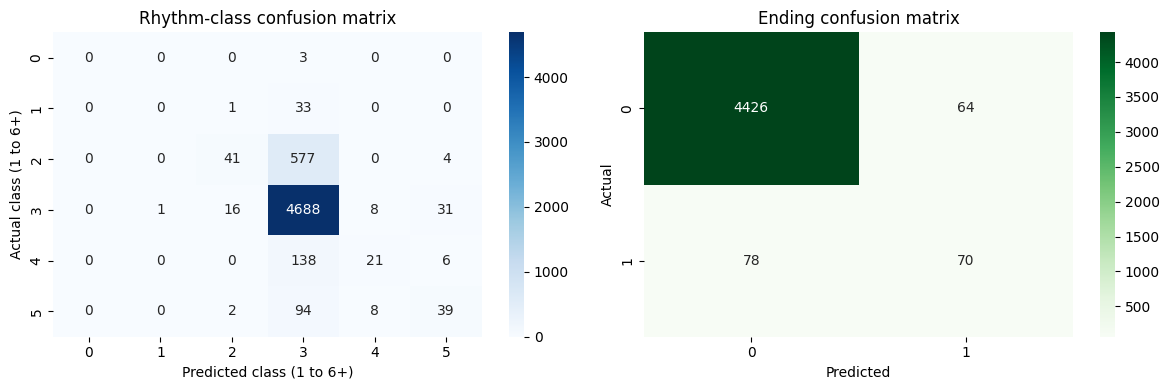

,rhyme_class,validation_count,rhyme_label
0,0,2311,<UNKNOWN>
1,1,218,သည်
2,2,191,ကို
3,3,180,နှင့်
4,5,107,လည်း
5,4,101,က
6,7,84,သို့
7,9,83,သား
8,8,83,ဟု
9,10,81,လျက်


In [42]:
from sklearn.metrics import confusion_matrix, f1_score

rhythm_true = prosody_arrays["validation"]["targets"]["rhythm_output"]
rhythm_predicted = np.argmax(prediction_map["rhythm_output"], axis=1)
rhyme_true = prosody_arrays["validation"]["targets"]["rhyme_output"]
rhyme_predicted = np.argmax(prediction_map["rhyme_output"], axis=1)
ending_true = prosody_arrays["validation"]["targets"]["end_output"].ravel()
ending_valid = ending_true >= 0
ending_predicted = (prediction_map["end_output"].ravel()[ending_valid] >= PROSODY_END_THRESHOLD).astype(int)

imbalance_metrics = pd.DataFrame([
    {"target": "rhythm", "accuracy": np.mean(rhythm_true == rhythm_predicted), "macro_f1": f1_score(rhythm_true, rhythm_predicted, average="macro", zero_division=0), "majority_baseline": pd.Series(rhythm_true).value_counts(normalize=True).max()},
    {"target": "rhyme", "accuracy": np.mean(rhyme_true == rhyme_predicted), "macro_f1": f1_score(rhyme_true, rhyme_predicted, average="macro", zero_division=0), "majority_baseline": pd.Series(rhyme_true).value_counts(normalize=True).max()},
    {"target": "ending", "accuracy": np.mean(ending_true[ending_valid] == ending_predicted), "macro_f1": f1_score(ending_true[ending_valid].astype(int), ending_predicted, average="macro", zero_division=0), "majority_baseline": pd.Series(ending_true[ending_valid]).value_counts(normalize=True).max()},
])
display(imbalance_metrics.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "majority_baseline": "{:.3f}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(rhythm_true, rhythm_predicted, labels=range(6)), annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set(title="Rhythm-class confusion matrix", xlabel="Predicted class (1 to 6+)", ylabel="Actual class (1 to 6+)")
sns.heatmap(confusion_matrix(ending_true[ending_valid].astype(int), ending_predicted, labels=[0, 1]), annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set(title="Ending confusion matrix", xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); plt.show()

inverse_rhyme_class = {value: key for key, value in rhyme_to_class.items()}
rhyme_distribution = pd.Series(rhyme_true).value_counts().rename_axis("rhyme_class").reset_index(name="validation_count")
rhyme_distribution["rhyme_label"] = rhyme_distribution["rhyme_class"].map(lambda value: "<UNKNOWN>" if value == 0 else inverse_rhyme_class.get(value, "<UNKNOWN>"))
display(rhyme_distribution.head(15))

### 9.2 Build Matched Ablation Variants

The token-only control is essential: it separates any benefit of the anchor/recency architecture from the effect of an auxiliary loss. Every variant still receives the same rhythm-history and previous-rhyme inputs, so the comparison isolates supervision rather than changing both inputs and objectives simultaneously.

In [26]:
ABLATION_TASKS = {
    "token_only": None,
    "rhythm_only": "rhythm_output",
    "rhyme_only": "rhyme_output",
    "ending_only": "end_output",
}
ABLATION_AUXILIARY_WEIGHTS = {"rhythm_output": 0.20, "rhyme_output": 0.30, "end_output": 0.20}

def build_prosody_ablation(auxiliary_output=None):
    if auxiliary_output not in {None, "rhythm_output", "rhyme_output", "end_output"}:
        raise ValueError("Unknown auxiliary output.")
    anchor_input = tf.keras.Input((PROSODY_ANCHOR_LENGTH,), dtype="int32", name="anchor_input")
    recent_input = tf.keras.Input((PROSODY_CONTEXT_LENGTH,), dtype="int32", name="recent_input")
    rhythm_input = tf.keras.Input((PROSODY_RHYTHM_HISTORY,), dtype="int32", name="rhythm_history_input")
    rhyme_input = tf.keras.Input((1,), dtype="int32", name="previous_rhyme_input")
    decoder_input = tf.keras.Input((PROSODY_DECODER_LENGTH,), dtype="int32", name="decoder_input")

    encoder_embedding = tf.keras.layers.Embedding(PROSODY_VOCABULARY_SIZE, PROSODY_EMBEDDING_DIM, mask_zero=True, name="encoder_embedding")
    decoder_embedding = tf.keras.layers.Embedding(PROSODY_VOCABULARY_SIZE, PROSODY_EMBEDDING_DIM, mask_zero=True, name="decoder_embedding")
    anchor_emb = encoder_embedding(anchor_input); recent_emb = encoder_embedding(recent_input); decoder_emb = decoder_embedding(decoder_input)
    anchor_state = tf.keras.layers.GRU(PROSODY_RECURRENT_UNITS, name="anchor_gru")(anchor_emb)
    recent_outputs, recent_state = tf.keras.layers.GRU(PROSODY_RECURRENT_UNITS, return_sequences=True, return_state=True, name="recent_gru")(recent_emb)
    gate_input = tf.keras.layers.Concatenate()([recent_state, anchor_state])
    gate = tf.keras.layers.Dense(PROSODY_RECURRENT_UNITS, activation="sigmoid", bias_initializer=tf.keras.initializers.Constant(1.0), name="recency_gate")(gate_input)
    context = tf.keras.layers.Add()([tf.keras.layers.Multiply()([gate, recent_state]), tf.keras.layers.Multiply()([1.0 - gate, anchor_state])])
    rhythm_features = tf.keras.layers.Flatten()(tf.keras.layers.Embedding(PROSODY_MAX_RHYTHM + 1, 8, name="rhythm_embedding")(rhythm_input))
    rhyme_features = tf.keras.layers.Flatten()(tf.keras.layers.Embedding(RHYME_CLASS_COUNT, 16, name="rhyme_embedding")(rhyme_input))
    shared = tf.keras.layers.Concatenate(name="shared_poetic_context")([context, rhythm_features, rhyme_features])
    initial_state = tf.keras.layers.Dense(PROSODY_RECURRENT_UNITS, activation="tanh", name="decoder_initial_state")(shared)
    decoder_outputs = tf.keras.layers.GRU(PROSODY_RECURRENT_UNITS, return_sequences=True, name="decoder_gru")(decoder_emb, initial_state=initial_state)
    attended = tf.keras.layers.AdditiveAttention(name="recent_attention")([decoder_outputs, recent_outputs], mask=[decoder_embedding.compute_mask(decoder_input), encoder_embedding.compute_mask(recent_input)])
    token_features = tf.keras.layers.Dropout(PROSODY_DROPOUT_RATE)(tf.keras.layers.Concatenate()([decoder_outputs, attended]))
    token_output = tf.keras.layers.Dense(PROSODY_VOCABULARY_SIZE, activation="softmax", name="token_output")(token_features)

    outputs = [token_output]; losses = {"token_output": prosody_masked_token_loss}; loss_weights = {"token_output": 1.0}
    metrics = {"token_output": [ProsodyMaskedTokenAccuracy()]}
    if auxiliary_output == "rhythm_output":
        outputs.append(tf.keras.layers.Dense(6, activation="softmax", name="rhythm_output")(shared))
        losses["rhythm_output"] = "sparse_categorical_crossentropy"; metrics["rhythm_output"] = ["sparse_categorical_accuracy"]
    elif auxiliary_output == "rhyme_output":
        outputs.append(tf.keras.layers.Dense(RHYME_CLASS_COUNT, activation="softmax", name="rhyme_output")(shared))
        losses["rhyme_output"] = "sparse_categorical_crossentropy"; metrics["rhyme_output"] = ["sparse_categorical_accuracy"]
    elif auxiliary_output == "end_output":
        outputs.append(tf.keras.layers.Dense(1, activation="sigmoid", name="end_output")(shared))
        losses["end_output"] = masked_end_binary_crossentropy; metrics["end_output"] = [MaskedEndAccuracy()]
    if auxiliary_output is not None: loss_weights[auxiliary_output] = ABLATION_AUXILIARY_WEIGHTS[auxiliary_output]

    model = tf.keras.Model([anchor_input, recent_input, rhythm_input, rhyme_input, decoder_input], outputs, name=f"prosody_ablation_{auxiliary_output or 'token_only'}")
    model.compile(optimizer=tf.keras.optimizers.Adam(PROSODY_LEARNING_RATE, clipnorm=1.0), loss=losses, loss_weights=loss_weights, metrics=metrics)
    return model

# Architecture check only; training occurs in the next cell.
ablation_shape_check = build_prosody_ablation(None)
print("Token-only control outputs:", ablation_shape_check.output_names)
del ablation_shape_check

Token-only control outputs: ['token_output']


### 9.3 Train the Four Ablations

Each variant uses a separate checkpoint. Early stopping now monitors total validation loss, so an enabled auxiliary task contributes to checkpoint selection instead of being ignored. The search remains fixed and reproducible; this is not hyperparameter optimisation.

In [44]:
ABLATION_MAX_EPOCHS = 18
ABLATION_PATIENCE = 5
from sklearn.metrics import f1_score

ABLATION_CHECKPOINT_DIRECTORY = Path("model_checkpoints/ablations")
ABLATION_CHECKPOINT_DIRECTORY.mkdir(parents=True, exist_ok=True)

def make_ablation_dataset(split_name, auxiliary_output=None, shuffle=False):
    item = prosody_arrays[split_name]
    target_names = ["token_output"] + ([auxiliary_output] if auxiliary_output else [])
    targets = {name: item["targets"][name] for name in target_names}
    dataset = tf.data.Dataset.from_tensor_slices((item["inputs"], targets))
    if shuffle:
        dataset = dataset.shuffle(min(len(item["rows"]), 20000), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(PROSODY_BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

ablation_histories = {}; ablation_checkpoint_paths = {}; ablation_training_summary = []
for variant_name, auxiliary_output in ABLATION_TASKS.items():
    print(f"\n===== Training {variant_name} =====")
    tf.keras.backend.clear_session()
    model = build_prosody_ablation(auxiliary_output)
    train_data = make_ablation_dataset("train", auxiliary_output, shuffle=True)
    validation_data = make_ablation_dataset("validation", auxiliary_output)
    checkpoint = ABLATION_CHECKPOINT_DIRECTORY / f"{variant_name}_best.weights.h5"
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=ABLATION_PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", mode="min", save_best_only=True, save_weights_only=True, verbose=1),
    ]
    history = model.fit(train_data, validation_data=validation_data, epochs=ABLATION_MAX_EPOCHS, callbacks=callbacks, verbose=1)
    model.load_weights(checkpoint)
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
    best_metrics = model.evaluate(validation_data, verbose=0, return_dict=True)
    ablation_histories[variant_name] = history.history; ablation_checkpoint_paths[variant_name] = checkpoint
    ablation_training_summary.append({"variant": variant_name, "auxiliary_output": auxiliary_output or "none", "best_epoch": best_epoch, **best_metrics})
    del model, train_data, validation_data

ablation_training_summary_df = pd.DataFrame(ablation_training_summary)
display(ablation_training_summary_df)


===== Training token_only =====
Epoch 1/18
365/366 [============================>.] - ETA: 0s - loss: 2.0920 - masked_accuracy: 0.2083
Epoch 1: val_loss improved from inf to 1.99272, saving model to model_checkpoints\ablations\token_only_best.weights.h5
366/366 [==============================] - 38s 72ms/step - loss: 2.0920 - masked_accuracy: 0.2083 - val_loss: 1.9927 - val_masked_accuracy: 0.2164 - lr: 0.0010
Epoch 2/18
365/366 [============================>.] - ETA: 0s - loss: 1.9389 - masked_accuracy: 0.2229
Epoch 2: val_loss improved from 1.99272 to 1.89109, saving model to model_checkpoints\ablations\token_only_best.weights.h5
366/366 [==============================] - 22s 61ms/step - loss: 1.9389 - masked_accuracy: 0.2229 - val_loss: 1.8911 - val_masked_accuracy: 0.2345 - lr: 0.0010
Epoch 3/18
365/366 [============================>.] - ETA: 0s - loss: 1.8228 - masked_accuracy: 0.2469
Epoch 3: val_loss improved from 1.89109 to 1.79709, saving model to model_checkpoints\ablations\

,variant,auxiliary_output,best_epoch,loss,masked_accuracy,token_output_loss,rhythm_output_loss,token_output_masked_accuracy,rhythm_output_sparse_categorical_accuracy,rhyme_output_loss,rhyme_output_sparse_categorical_accuracy,end_output_loss,end_output_masked_end_accuracy
0,token_only,none,10,1.583130,0.323035,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,rhythm_only,rhythm_output,9,1.718560,NaN,1.595486,0.615372,0.314284,0.821923,NaN,NaN,NaN,NaN
2,rhyme_only,rhyme_output,8,2.585671,NaN,1.628346,NaN,0.302123,NaN,3.191085,0.388899,NaN,NaN
3,ending_only,end_output,10,1.658266,NaN,1.602319,NaN,0.311050,NaN,NaN,NaN,0.279737,0.962915


### 9.3.1 Reload Saved Ablations Without Retraining

Run this recovery cell instead of Section 9.3 after a kernel restart. It restores checkpoint paths and the validation helpers required by Section 9.4; it does not call `fit()` or modify any saved model.

In [27]:
from sklearn.metrics import f1_score

ABLATION_CHECKPOINT_DIRECTORY = Path("model_checkpoints/ablations")
ablation_checkpoint_paths = {
    variant_name: ABLATION_CHECKPOINT_DIRECTORY / f"{variant_name}_best.weights.h5"
    for variant_name in ABLATION_TASKS
}
missing_checkpoints = [str(path) for path in ablation_checkpoint_paths.values() if not path.exists()]
if missing_checkpoints:
    raise FileNotFoundError("Missing ablation checkpoints: " + ", ".join(missing_checkpoints))

def make_ablation_dataset(split_name, auxiliary_output=None, shuffle=False):
    item = prosody_arrays[split_name]
    target_names = ["token_output"] + ([auxiliary_output] if auxiliary_output else [])
    targets = {name: item["targets"][name] for name in target_names}
    dataset = tf.data.Dataset.from_tensor_slices((item["inputs"], targets))
    if shuffle:
        dataset = dataset.shuffle(min(len(item["rows"]), 20000), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(PROSODY_BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def prosody_content_ids(sequence):
    content = []
    for token_id in sequence:
        token_id = int(token_id)
        if token_id in {PAD_ID, PHRASE_END_ID, STANZA_END_ID}: break
        if token_id != START_ID: content.append(token_id)
    return content

def prosody_rhyme_key(syllable):
    characters = list(unicodedata.normalize("NFC", syllable))
    if not characters: return None
    if re.fullmatch(r"[က-အ]", characters[0]): characters = characters[1:]
    while characters and characters[0] in {"ျ", "ြ", "ွ", "ှ"}: characters.pop(0)
    rhyme = "".join(character for character in characters if character not in {"့", "း"})
    return rhyme or "<INHERENT_VOWEL>"

def prosody_token_loop(tokens):
    if any(tokens[index] == tokens[index + 1] == tokens[index + 2] for index in range(max(0, len(tokens) - 2))): return True
    return any(tokens[index:index + width] == tokens[index + width:index + 2 * width] for width in (2, 3) for index in range(len(tokens) - 2 * width + 1))

def prosody_js_divergence(reference_lengths, generated_lengths):
    maximum = max(max(reference_lengths), max(generated_lengths))
    reference = np.bincount(reference_lengths, minlength=maximum + 1).astype(float); generated = np.bincount(generated_lengths, minlength=maximum + 1).astype(float)
    reference /= reference.sum(); generated /= generated.sum(); midpoint = (reference + generated) / 2
    def kl(distribution):
        nonzero = distribution > 0
        return np.sum(distribution[nonzero] * np.log2(distribution[nonzero] / midpoint[nonzero]))
    return 0.5 * (kl(reference) + kl(generated))

prosody_validation_inputs = prosody_arrays["validation"]["inputs"]
prosody_validation_targets = prosody_arrays["validation"]["targets"]["token_output"]
reference_lengths = [len(prosody_content_ids(row)) for row in prosody_validation_targets]
special_ids = {PAD_ID, START_ID, PHRASE_END_ID, STANZA_END_ID}
end_truth = prosody_arrays["validation"]["targets"]["end_output"].ravel()
valid_end = end_truth >= 0
print("Recovered evaluation state. Checkpoints:")
for variant_name, checkpoint in ablation_checkpoint_paths.items(): print(f"  {variant_name}: {checkpoint}")

Recovered evaluation state. Checkpoints:
  token_only: model_checkpoints\ablations\token_only_best.weights.h5
  rhythm_only: model_checkpoints\ablations\rhythm_only_best.weights.h5
  rhyme_only: model_checkpoints\ablations\rhyme_only_best.weights.h5
  ending_only: model_checkpoints\ablations\ending_only_best.weights.h5


### 9.4 Evaluate and Rank the Ablations

All variants are evaluated with identical greedy next-phrase generation and the same 300-query continuation-ranking sample. The rank sum is a transparent screening aid, not proof that a model is good: token loss, phrase-length divergence and loop rate are minimised, while rhyme consistency, MRR and Recall@5 are maximised. The best ablation must still beat the original context-attention reference on the important measures before it is selected for Optuna.

In [28]:
def ablation_output_map(model, outputs):
    if isinstance(outputs, dict): return outputs
    if not isinstance(outputs, (list, tuple)): outputs = [outputs]
    return dict(zip(model.output_names, outputs))

def greedy_generate_ablation(model, inputs, batch_size=256):
    total = len(inputs["anchor_input"]); generated = np.full((total, PROSODY_DECODER_LENGTH), PAD_ID, dtype=np.int32)
    for start in range(0, total, batch_size):
        end = min(start + batch_size, total); batch = {name: values[start:end].copy() for name, values in inputs.items()}
        decoder = np.full((end - start, PROSODY_DECODER_LENGTH), PAD_ID, dtype=np.int32); decoder[:, 0] = START_ID
        finished = np.zeros(end - start, dtype=bool)
        for step in range(PROSODY_DECODER_LENGTH):
            batch["decoder_input"] = decoder
            token_probabilities = ablation_output_map(model, model(batch, training=False))["token_output"]
            next_ids = tf.argmax(token_probabilities[:, step], axis=-1).numpy().astype(np.int32)
            next_ids = np.where(finished, PAD_ID, next_ids); generated[start:end, step] = next_ids
            finished |= np.isin(next_ids, [PAD_ID, PHRASE_END_ID, STANZA_END_ID])
            if step + 1 < PROSODY_DECODER_LENGTH: decoder[:, step + 1] = np.where(finished, PAD_ID, next_ids)
            if finished.all(): break
    return generated

ABLATION_RANKING_SAMPLE_SIZE = min(300, len(prosody_validation_targets)); ABLATION_CANDIDATE_COUNT = 10
ablation_rng = np.random.default_rng(SEED); ablation_queries = ablation_rng.choice(len(prosody_validation_targets), ABLATION_RANKING_SAMPLE_SIZE, replace=False)
ablation_target_keys = [tuple(row.tolist()) for row in prosody_validation_targets]
ablation_target_lengths = np.asarray([len(prosody_content_ids(row)) for row in prosody_validation_targets])
ablation_query_rows = []; ablation_target_rows = []
for query_index in ablation_queries:
    pool = np.where(np.abs(ablation_target_lengths - ablation_target_lengths[query_index]) <= 1)[0]
    pool = np.asarray([i for i in pool if i != query_index and ablation_target_keys[i] != ablation_target_keys[query_index]])
    if len(pool) < ABLATION_CANDIDATE_COUNT - 1: pool = np.asarray([i for i in range(len(ablation_target_keys)) if i != query_index and ablation_target_keys[i] != ablation_target_keys[query_index]])
    distractors = ablation_rng.choice(pool, ABLATION_CANDIDATE_COUNT - 1, replace=False)
    ablation_query_rows.extend([query_index] * ABLATION_CANDIDATE_COUNT); ablation_target_rows.extend(np.concatenate(([query_index], distractors)).tolist())
ablation_query_rows = np.asarray(ablation_query_rows); ablation_target_rows = np.asarray(ablation_target_rows)

def score_ablation_candidates(model, query_inputs, decoder_inputs, targets, batch_size=128):
    scores = []
    for start in range(0, len(targets), batch_size):
        end = min(start + batch_size, len(targets)); batch = {name: values[start:end] for name, values in query_inputs.items()}
        batch["decoder_input"] = decoder_inputs[start:end]
        probabilities = ablation_output_map(model, model(batch, training=False))["token_output"].numpy(); target_batch = targets[start:end]
        selected = np.take_along_axis(probabilities, target_batch[..., None], axis=-1).squeeze(-1); mask = target_batch != PAD_ID
        scores.extend(((np.log(np.clip(selected, 1e-9, 1.0)) * mask).sum(1) / np.maximum(mask.sum(1), 1)).tolist())
    return np.asarray(scores)

ablation_metric_rows = []; ablation_end_thresholds = {}
for variant_name, auxiliary_output in ABLATION_TASKS.items():
    print("Evaluating", variant_name)
    tf.keras.backend.clear_session(); model = build_prosody_ablation(auxiliary_output); model.load_weights(ablation_checkpoint_paths[variant_name])
    validation_data = make_ablation_dataset("validation", auxiliary_output); teacher_metrics = model.evaluate(validation_data, verbose=0, return_dict=True)
    generated = greedy_generate_ablation(model, prosody_validation_inputs); generated_content = [prosody_content_ids(row) for row in generated]
    generated_lengths = [len(row) for row in generated_content]; rhyme_matches = []; loops = []
    for context_row, output_row in zip(prosody_validation_inputs["recent_input"], generated_content):
        context_content = [int(i) for i in context_row if int(i) not in special_ids]
        if context_content and output_row:
            input_key = prosody_rhyme_key(id_to_token[context_content[-1]]); output_keys = {prosody_rhyme_key(id_to_token[i]) for i in output_row}
            rhyme_matches.append(input_key in output_keys)
        else: rhyme_matches.append(False)
        loops.append(prosody_token_loop(output_row))

    query_inputs = {name: values[ablation_query_rows] for name, values in prosody_validation_inputs.items() if name != "decoder_input"}
    scores = score_ablation_candidates(model, query_inputs, prosody_validation_inputs["decoder_input"][ablation_target_rows], prosody_validation_targets[ablation_target_rows]).reshape(ABLATION_RANKING_SAMPLE_SIZE, ABLATION_CANDIDATE_COUNT)
    ranks = 1 + np.sum(scores[:, 1:] > scores[:, [0]], axis=1)
    ending_f1 = np.nan
    if "end_output" in model.output_names:
        predictions = ablation_output_map(model, model.predict(prosody_validation_inputs, batch_size=PROSODY_BATCH_SIZE, verbose=0)); probability = predictions["end_output"].ravel()
        best_threshold = 0.5; best_f1 = -1.0
        for threshold in np.arange(0.30, 0.81, 0.05):
            value = f1_score(end_truth[valid_end].astype(int), (probability[valid_end] >= threshold).astype(int), zero_division=0)
            if value > best_f1: best_threshold, best_f1 = float(threshold), float(value)
        ablation_end_thresholds[variant_name] = best_threshold; ending_f1 = best_f1
    ablation_metric_rows.append({
        "variant": variant_name, "token_loss": teacher_metrics.get("token_output_loss", teacher_metrics["loss"]),
        "masked_token_accuracy": next((value for key, value in teacher_metrics.items() if "masked_accuracy" in key), np.nan),
        "phrase_length_js_divergence": prosody_js_divergence(reference_lengths, generated_lengths),
        "rhyme_consistency_percent": np.mean(rhyme_matches) * 100, "repetition_loop_percent": np.mean(loops) * 100,
        "ending_f1": ending_f1, "continuation_mrr": np.mean(1 / ranks), "continuation_recall_at_5": np.mean(ranks <= 5) * 100,
    })
    del model, validation_data

ablation_metrics_df = pd.DataFrame(ablation_metric_rows)
rank_rules = {"token_loss": True, "phrase_length_js_divergence": True, "rhyme_consistency_percent": False, "repetition_loop_percent": True, "continuation_mrr": False, "continuation_recall_at_5": False}
for column, ascending in rank_rules.items(): ablation_metrics_df[column + "_rank"] = ablation_metrics_df[column].rank(method="average", ascending=ascending)
ablation_metrics_df["selection_rank_sum"] = ablation_metrics_df[[column + "_rank" for column in rank_rules]].sum(axis=1)
BEST_ABLATION_NAME = ablation_metrics_df.sort_values("selection_rank_sum").iloc[0]["variant"]
display(ablation_metrics_df.sort_values("selection_rank_sum"))
print("Best ablation by screening rank (not automatically the final model):", BEST_ABLATION_NAME)
print("Ending thresholds:", ablation_end_thresholds)

Evaluating token_only
Evaluating rhythm_only
Evaluating rhyme_only
Evaluating ending_only


,variant,token_loss,masked_token_accuracy,phrase_length_js_divergence,rhyme_consistency_percent,repetition_loop_percent,ending_f1,continuation_mrr,continuation_recall_at_5,token_loss_rank,phrase_length_js_divergence_rank,rhyme_consistency_percent_rank,repetition_loop_percent_rank,continuation_mrr_rank,continuation_recall_at_5_rank,selection_rank_sum
0,token_only,1.583130,0.323035,0.010621,45.893889,10.786202,NaN,0.463714,72.333333,1.0,1.0,1.0,2.0,2.0,1.5,8.5
1,rhythm_only,1.595486,0.314284,0.010829,44.037822,12.852390,NaN,0.479275,72.333333,2.0,2.0,2.0,4.0,1.0,1.5,12.5
3,ending_only,1.602319,0.311050,0.011168,39.800385,10.943793,0.452229,0.450933,69.000000,3.0,3.0,3.0,3.0,3.0,3.0,18.0
2,rhyme_only,1.628346,0.302123,0.011366,36.000700,9.402907,NaN,0.420179,62.333333,4.0,4.0,4.0,1.0,4.0,4.0,21.0


Best ablation by screening rank (not automatically the final model): token_only
Ending thresholds: {'ending_only': 0.49999999999999994}


### 9.5 Ablation Decision

The **token-only control** is the strongest ablation, with the lowest token loss (**1.5831**), highest masked token accuracy (**32.30%**), best rhyme consistency (**45.89%**) and best phrase-length divergence (**0.0106**) among the four variants. It also achieves **72.33% Recall@5**. The rhythm-only model obtains the highest MRR (**0.4793**) but worsens token accuracy, phrase-length divergence and persistent looping. Rhyme-only ranks last despite explicitly receiving rhyme supervision, while ending-only reaches only **0.452 ending F1**.

The result indicates negative transfer from the auxiliary objectives: the shared anchor/recency architecture learns best when optimised only for syllable generation. The diagnostics explain part of this failure. Rhythm accuracy (**0.839**) is only slightly above its **0.831** majority baseline and has macro-F1 **0.265**. Rhyme accuracy (**0.391**) is below its **0.405** majority baseline, macro-F1 is only **0.028**, and 2,311 validation examples map to the unknown rhyme class. Ending accuracy is essentially equal to its majority baseline even though its macro-F1 is more informative.

Token-only is therefore the ablation candidate, but it does not unconditionally replace the original Context Attention GRU. Relative to the original model, it improves rhyme consistency (**45.89% versus 41.87%**) and Recall@5 (**72.33% versus 71.60%**), while worsening phrase-length divergence (**0.0106 versus 0.0068**), persistent-loop rate (**10.79% versus 7.01%**) and MRR (**0.4637 versus 0.4717**). Because rhythm is the main project priority, qualitative generation comparison is required before choosing between them.

## 10. Model Selection and Tuning Decision

The original **four-phrase Context Attention GRU** remains the reference model, while the new **token-only anchor/recency GRU** becomes the only ablation candidate worth further inspection. None of the rhythm, rhyme or ending auxiliary heads is selected. Their high headline accuracies largely reflect class imbalance, and their separate ablation results do not justify their additional complexity.

Token-only presents a genuine trade-off: it improves the approximate rhyme measure and Recall@5, but the original model preserves the validation phrase-length distribution more closely, produces fewer detected loops and has slightly stronger MRR. Since rhythm is the most important unresolved issue, the automatic rank sum alone is not sufficient to select token-only.

### 10.1 Next Steps

First compare several validation and manual generations from the original Context Attention GRU and token-only candidate, using the same prompts and decoding settings. Inspect local relevance, longer-range drift, phrase rhythm, valid poetic repetition and stanza stopping. If token-only is not qualitatively better, retain and tune the original model. If it is clearly better, apply a small Optuna search to token-only only. Keep every checkpoint unchanged, select decoding settings on validation data, and evaluate the final frozen model once on the untouched test partition.

Possible future improvements include repetition-aware or n-gram-blocked decoding, rhyme-based candidate reranking, greater training weight for `<STANZA_END>`, an auxiliary stanza-ending predictor, and more accurate manual stanza-boundary annotation. A hierarchical encoder that first represents syllables within each phrase and then models relationships between phrases may also preserve long-range poetic structure more effectively.

### 10.2 Controlled Validation Test Cases

The final qualitative comparison uses 12 reproducible validation cases rather than manually selecting favourable examples. Cases are stratified by the target's relative position in the source sequence and by the number of phrases remaining. This covers opening, middle and late contexts together with short, medium, long and very long continuations. The test partition remains untouched.

For each case, both candidate models must use the same source sequence, sampling seed, top-k, temperature and generation limit. The original model receives its trained representation of the latest four phrases; the token-only model receives its trained representation of the global anchor plus the latest three phrases.

In [25]:
CONTROLLED_CASE_COUNT = 12
case_rng = np.random.default_rng(SEED + 100)
validation_case_rows = prosody_arrays["validation"]["rows"].reset_index(drop=True)
stanza_lookup = preprocessed_stanzas_df.set_index("source_stanza_id")
case_records = []

for validation_index, row in validation_case_rows.iterrows():
    stanza = stanza_lookup.loc[row["source_stanza_id"]]
    groups = stanza["syllable_phrases"]
    target_index = int(row["target_phrase_index"])
    total_phrases = len(groups); remaining_phrases = total_phrases - target_index
    latest_four = groups[max(0, target_index - 4):target_index]
    recent_three = groups[max(0, target_index - 3):target_index]
    position_fraction = target_index / max(total_phrases - 1, 1)
    position_group = "early" if position_fraction <= 1/3 else ("middle" if position_fraction <= 2/3 else "late")
    remaining_group = "1-3" if remaining_phrases <= 3 else ("4-10" if remaining_phrases <= 10 else ("11-20" if remaining_phrases <= 20 else "21+"))
    actual_remaining = ["".join(group) for group in groups[target_index:]]
    case_records.append({
        "validation_index": validation_index, "source_stanza_id": row["source_stanza_id"],
        "target_phrase_index": target_index, "total_phrases": total_phrases, "remaining_phrases": remaining_phrases,
        "position_group": position_group, "remaining_group": remaining_group,
        "global_anchor": "".join(groups[0]),
        "latest_four_context": ["".join(group) for group in latest_four],
        "recent_three_context": ["".join(group) for group in recent_three],
        "context_rhythm": "-".join(str(len(group)) for group in latest_four),
        "actual_next_phrase": actual_remaining[0],
        "actual_next_three": actual_remaining[:3],
    })

validation_case_pool = pd.DataFrame(case_records)
selected_indices = []
for _, group in validation_case_pool.groupby(["position_group", "remaining_group"], sort=True):
    selected_indices.append(int(case_rng.choice(group.index.to_numpy())))
selected_indices = list(dict.fromkeys(selected_indices))
if len(selected_indices) < CONTROLLED_CASE_COUNT:
    remaining_pool = validation_case_pool.index.difference(selected_indices).to_numpy()
    selected_indices.extend(case_rng.choice(remaining_pool, CONTROLLED_CASE_COUNT - len(selected_indices), replace=False).tolist())
elif len(selected_indices) > CONTROLLED_CASE_COUNT:
    selected_indices = case_rng.choice(np.asarray(selected_indices), CONTROLLED_CASE_COUNT, replace=False).tolist()

controlled_validation_cases = validation_case_pool.loc[selected_indices].copy().reset_index(drop=True)
controlled_validation_cases.insert(0, "case_id", [f"T{index:02d}" for index in range(1, len(controlled_validation_cases) + 1)])
display_columns = ["case_id", "validation_index", "position_group", "remaining_group", "target_phrase_index", "total_phrases", "context_rhythm", "global_anchor", "latest_four_context", "actual_next_phrase"]
with pd.option_context("display.max_colwidth", None):
    display(controlled_validation_cases[display_columns].style.set_properties(**{"white-space": "pre-wrap", "text-align": "left"}))

assert len(controlled_validation_cases) == CONTROLLED_CASE_COUNT
assert set(controlled_validation_cases["validation_index"]).issubset(set(validation_case_rows.index))
print("Controlled validation cases ready:", len(controlled_validation_cases))

,case_id,validation_index,position_group,remaining_group,target_phrase_index,total_phrases,context_rhythm,global_anchor,latest_four_context,actual_next_phrase
0,T01,27,early,1-3,1,4,8,နွေဂိမာန်မိဿာစန်းဟာမို့,['နွေဂိမာန်မိဿာစန်းဟာမို့'],ဝေထိန်လျှံစိတြဆန်းပြန်တော့
1,T02,9,early,11-20,5,23,4-4-4-4,နစ်ပေါ်လှာ,"['စည်တော်သာနှင့်', 'ခရာဒုံမင်း', 'စောင်းညှင်းပြွေနှဲ', 'ရေလုံးသဲမျှ']",အပွဲပွဲအောင်
2,T03,3030,early,21+,8,36,4-4-4-4,သပြေသခင်,"['ယုဂန်အဦး', 'ကြယ်စိုင်ရှူးလျှင်', 'မြူးလစ်တရံ', 'ရေပေါ်ပျံသို့']",ရောင်လျှံဖွေးဖွေး
3,T04,41,early,4-10,1,7,3,သိုးကလေ,['သိုးကလေ'],စကားပွင့်နှင့်
4,T05,2744,late,1-3,36,39,4-4-4-4,ဟောရဂန္ထ,"['အသားအရိုး', 'စုံပြည့်ဖြိုးလျက်', 'ကျော်ဟိုးမြင်သိ', 'ပညာရှိဟု']",ကိတ္တိထင်ရှား
5,T06,3820,late,11-20,38,55,4-4-4-4,စည်ထွန်းကမ္ဘာ,"['အဆန်းဆန်းနှင့်', 'ရွှေနန်းပွင့်ဘူး', 'မြတ်ကျေးဇူးကို', 'လေးဦးမကျေ']",ကပ်လုံးနေသို့
6,T07,2392,late,21+,86,108,4-4-4-4,ကွမ်းသီးရှားစေး,"['ခြင်းသည်မိန်းမ', 'ယုယလှမ်းစေ', 'ချင်းရေဆန်တက်', 'စားတော်ချက်မှာ']",နံနက်မည်ရွေ့
7,T08,5470,late,4-10,79,87,4-4-4-4,ခရာရွှေလိပ်,"['ဘွင့်တော်မူမှ', 'ရှင်လူအများ', 'ထင်ရှားသူငါ', 'သိရပါအံ့']",နောင်လာယခု
8,T09,44,middle,1-3,4,7,3-4-4-4,သိုးကလေ,"['သိုးကလေ', 'စကားပွင့်နှင့်', 'နှိုင်းတင့်နိုးသည်', 'ရဲမျိုးသမီး']",မောင်ကြီးနှမ
9,T10,4215,middle,11-20,11,30,4-4-3-4,ဘဒ္ဒကမ္ဘာ,"['မျိုးရိုးစဉ်ဆက်', 'မပျက်စဉ်လာ', 'ဥက္ကာကရာဇ်', 'ဖြစ်တုံတသွန်']",လွန်လေမကြွင်း


Controlled validation cases ready: 12


In [31]:
# Historical 12-case run from the superseded token-only comparison.
# The active comparison is now Section 11.6: compare_all_hybrid_cases().

Case: T01
Global anchor: နွေဂိမာန်မိဿာစန်းဟာမို့
Original latest-four context: နွေဂိမာန်မိဿာစန်းဟာမို့
Token-only recent-three context: နွေဂိမာန်မိဿာစန်းဟာမို့


,Actual validation text,Original Attention GRU,Token-Only Anchor/Recency GRU
Next phrase,ဝေထိန်လျှံစိတြဆန်းပြန်တော့၊,အာရုံစက်နှင့်၊,ပိပိပိတောက်၊
Next three phrases,ဝေထိန်လျှံစိတြဆန်းပြန်တော့၊ နန်းမေရုဗွေအာကာ၊ တာရာကရောင်စုံမြူ့း။,အာရုံစက်နှင့်၊ ရွှေတောင်နန်းဘုံ၊ မိုးရိပ်ခိုတွင်၊,ပိပိပိတောက်၊ စိန်ပုထိုးနှင့်၊ အချိန်တန်က၊
Toward stanza end,ဝေထိန်လျှံစိတြဆန်းပြန်တော့၊ နန်းမေရုဗွေအာကာ၊ တာရာကရောင်စုံမြူ့း။,အာရုံစက်နှင့်၊ ရွှေတောင်နန်းဘုံ၊ မိုးရိပ်ခိုတွင်၊ တကယ်တစ်ခါ၊ မာသရာနှင့်၊ အသာကိရိယာ၊ ရတနာသန်လျင်၊ အတူအပြား၊ အသားများလှ၊ တရားတရား။,ပိပိပိတောက်၊ စိန်ပုထိုးနှင့်၊ အချိန်တန်က၊ ဇွတ်တွန်းသ၊ ရောင်လျှံတောက်ညိ၊ ရွှေဥပသည်၊ မိလ္လာမြမြနီ၊ အင်္ကျီနှင့်နှင့်၊ ရွှေပုခက်နှင့်၊ တိမ်ပန်းပုခက်၊ ပန်းလည်းပန်းနှယ်၊ ပန်းနှယ်ပန်းသွင်၊ မြပွင့်ပွင့်သို့၊ သဇင်ပန်းသွင်၊ သဇင်ပန်းနှင့်၊ နန်းသစ်ပွင့်ငုံ၊ ပန်းနှယ်ထုံသည်၊ ပုထုပန်းပွင့်၊ ပန်းပွင့်ပွင့်သို့၊ ရွှေခဲပွင့်လျာ၊ [stopped at safety limit]


Case: T02
Global anchor: နစ်ပေါ်လှာ
Original latest-four context: စည်တော်သာနှင့် | ခရာဒုံမင်း | စောင်းညှင်းပြွေနှဲ | ရေလုံးသဲမျှ
Token-only recent-three context: ခရာဒုံမင်း | စောင်းညှင်းပြွေနှဲ | ရေလုံးသဲမျှ


,Actual validation text,Original Attention GRU,Token-Only Anchor/Recency GRU
Next phrase,အပွဲပွဲအောင်၊,မိုးယံမောက်မော်၊,တပ်လည်းရံဝန်း၊
Next three phrases,အပွဲပွဲအောင်၊ ရာမင်းနောင်လျှင်၊ ဖောင်သက္ကဒါန်၊,မိုးယံမောက်မော်၊ ရတနာနှင့်၊ အရာမကျန်၊,တပ်လည်းရံဝန်း၊ ရေလုံးပြောင်လျက်၊ တောင်လည်းတောင်ငူ၊
Toward stanza end,အပွဲပွဲအောင်၊ ရာမင်းနောင်လျှင်၊ ဖောင်သက္ကဒါန်၊ သမ္ဗန်ကူရွပ်၊ ပျဉ်စပ်မထင်၊ လက်သင်လှော်ကား၊ အခြားခြားတည့်၊ မင်းသားမင်းညီ၊ တက်ပြိုင်ချီ၊ အောင်ပြီဝှဲဝှဲ၊ စံရေပွဲကို၊ ကြုံခဲတောင်းပင်၊ ကြည့်ပါချင်၊ မိခင်ဖဝတ်၊ ခွင့်မလွှတ်ခဲ့၊ မိုးနတ်ပျော်ရာ၊ ဆကာမာသည်၊ ခြောက်ရွာထင်ရပေလိမ့်မည်။,မိုးယံမောက်မော်၊ ရတနာနှင့်၊ အရာမကျန်၊ တယောက်မကျန်၊ မကျန်စေတနာ၊ ပေးစရာကို၊ ဘွေရှာအလျောက်၊ လျှောက်ပြီးနောက်သော်၊ ဘုန်းတောက်သည့်ရှင်၊ ဘုရားတင်ရာ၊ မယ့်ကိုသာလျှင်၊ မကြာမထင်၊ မြင်မြင်မြင်၊ မရှင်မခွ၊ အကျဉ်းပြု၊ သွားရတော့မည်၊ မရှိသည်ကို၊ ထိပ်ပေါ်ထိပ်ချာ၊ မယ့်ထိပ်ချာသည်၊ မကြာမရွှင်ဝမ်းသာတည်း။,တပ်လည်းရံဝန်း၊ ရေလုံးပြောင်လျက်၊ တောင်လည်းတောင်ငူ၊ လက်ရုံးလည်း၊ ပတ်ကုံးဝန်းကျင်၊ မြေပြင်ပြင်ထက်၊ သဘင်သာယာ၊ ရွှေနီလာထက်၊ မဟာမဟာ၊ မြတ်ရာဇာနှင့်၊ စကြာတော်မြတ်၊ ရွှေနန်းတွင်းဝယ်၊ နန်းခင်းပွင့်လျာ၊ ဥပရာနှင့်၊ မဟာသမ္မတ၊ သုဓမ္မရာ၊ စတေဇယ၊ အနိစ္စနှင့်၊ မသိရနိုင်၊ မနောဖြစ်သည်၊ [stopped at safety limit]


Case: T03
Global anchor: သပြေသခင်
Original latest-four context: ယုဂန်အဦး | ကြယ်စိုင်ရှူးလျှင် | မြူးလစ်တရံ | ရေပေါ်ပျံသို့
Token-only recent-three context: ကြယ်စိုင်ရှူးလျှင် | မြူးလစ်တရံ | ရေပေါ်ပျံသို့


,Actual validation text,Original Attention GRU,Token-Only Anchor/Recency GRU
Next phrase,ရောင်လျှံဖွေးဖွေး၊,ရွှေညောင်ရွက်နှင့်၊,ရောင်ဝှန်ရောင်ဘိတ်၊
Next three phrases,ရောင်လျှံဖွေးဖွေး၊ သလင်းပြေးသား၊ နားရေးလှပ်လှပ်၊,ရွှေညောင်ရွက်နှင့်၊ ရွှေညောင်ရွက်လျက်၊ ရွှေတောင်ရွှေခြူ၊,ရောင်ဝှန်ရောင်ဘိတ်၊ ရွှေဘုံရွှေထက်၊ ရွှေဘုံနန်းလယ်၊
Toward stanza end,ရောင်လျှံဖွေးဖွေး၊ သလင်းပြေးသား၊ နားရေးလှပ်လှပ်၊ ကြောင်ဝပ်စကား၊ ပဲ့ဖျားပြောင်ပြောင်၊ ပြည်ထောင်ရှေးနှောင်း၊ မစီးတောင်းသား၊ ရွှေလောင်းယာဉ်မွန်၊ ရွှေဗိမာန်ထက်၊ ဝမ်းချွန်ချက်ချက်၊ ရွှေဆောင်ပျက်၊ သရက်ကင်းမုံ၊ ပွင့်ဖူးငုံလျက်၊ ပြောက်စုံစိန်ပန်း၊ ထီးရန်းမလွတ်၊ ကဝတ်လက်ရုံး၊ ပွတ်လုံးမြာတိုင်၊ ရွှေတိနိုင်သား၊ ဝမ်းလှိုင်ကွန်းစင်၊ အလယ်တွင်၊ နတ်ရှင်ဆွေမှီး၊ တူကွစီးလျက်၊ သားကြီးမင်းလျာ၊ ဥပရာနှင့်၊ စကြာပွင့်နန်း၊ တည်လတ်ထွန်းသည်၊ ဆိပ်ခန်းစလင်း၊ ပြင်သာတည်း။,ရွှေညောင်ရွက်နှင့်၊ ရွှေညောင်ရွက်လျက်၊ ရွှေတောင်ရွှေခြူ၊ နန်းမယူသည်၊ နန်းခင်းတည့်ပျံ့မွှေး၊ နတ်မင်း။,ရောင်ဝှန်ရောင်ဘိတ်၊ ရွှေဘုံရွှေထက်၊ ရွှေဘုံနန်းလယ်၊ သုံးဆဲ့ကိုးမှ၊ ရွှေနန်းရွှေထီး၊ စံပယ်လှစ်၊ မင်းကြီးမှန်ကင်း၊ မင်းသမီးကို၊ ဘုန်းကြီးလျှံညီး၊ ဘေးတော်ကြီးလျှင်၊ အကြီးနီးလစ်၊ မင်းစစ်ငယ်နှင့်၊ သုံးသွယ်ရောင်ညီး၊ ရွှေထီးစီး၊ ကြီးကြီးမငြီး၊ သားတော်ကြီးနှင့်၊ ရွှေထီးရွှေထီး၊ မယွင်းကြီးနှင့်၊ ရွှေထီးစကြာ၊ မင်းဝံချာထက်၊ [stopped at safety limit]


... (14 outputs left out)

Case: T11
Global anchor: အိမ်ရှေ့မင်းမှာ
Original latest-four context: မီးမှုတ်ထင်းရာ | လုံခြုံစွာအောင် | စိုက်ချွန်ထောင်လော | ဖြင်ပေါက်တည်အိုး
Token-only recent-three context: လုံခြုံစွာအောင် | စိုက်ချွန်ထောင်လော | ဖြင်ပေါက်တည်အိုး


,Actual validation text,Original Attention GRU,Token-Only Anchor/Recency GRU
Next phrase,ပြည့်ဖြိုးအကြား၊,တစီးစက်နှင့်၊,တအိုးအိုးနှင့်၊
Next three phrases,ပြည့်ဖြိုးအကြား၊ လှေကားဆင့်ဆင့်၊ အသင့်ရှိစေ၊,တစီးစက်နှင့်၊ အခေါင်ထွဋ်တင်၊ ဆင်သည်တသီး၊,တအိုးအိုးနှင့်၊ အစဉ်မကျန်၊ မကျန်မနိုင်၊
Toward stanza end,ပြည့်ဖြိုးအကြား၊ လှေကားဆင့်ဆင့်၊ အသင့်ရှိစေ၊ သံခြေသံအိန့်၊ ဆိုမိန့်ရမည်၊ လေးတည်မျက်နှာ၊ ဝင်းတော်မှာကား၊ များစွာရေသော်၊ ကိုယ်ရံတော်တို့၊ ရွှင်ပျော်စုံမှတ်၊ ဝါကျွတ်ပွဲးဆင်၊ မရောက်လျှင်မူ၊ အလျင်ရောက်ဦး၊ ရွှင်မြူးသဘင်၊ ရွှေစင်ဝင်းစေ၊ သံခြေမိန့်နောက်၊ ဝင်ရောက်ပြလှာ၊ ငြိမ်သက်စွာလျှင်၊ ရွှေဆင်လုပ်သည်၊ သယ်သူမည်ဟု၊ နှုတ်ကြည်သာလေး၊ မေးပြီးတထပ်၊ ဆင်ရပ်မည်မျှ၊ တိုင်းရသည်ဟူ၊ မေးမြူတတည်၊ ရွှေ့မည်မဆိုင်း၊ မိန့်ပေသိပြီး၊ မှုတ်တီးကစေ၊ သံခြေမိန့်ဟ၊ သည့်ပတထွေ၊ ရန်စေတော့ဟူပျံ့ကြူထွေငေါ်၊ ဝင်းတော်လေးရပ်၊ များထပ်လောက်ငံ၊ ကိုယ်ရံတို့အား၊ ချိန်များကြေးခွက်၊ လက်ဘက်ပေးစေ၊ သံခြေပျံ့ကြည်၊ မိန့်ရမည်သည်၊ မြဲးတည်မမေ့မမှားတည်း။,တစီးစက်နှင့်၊ အခေါင်ထွဋ်တင်၊ ဆင်သည်တသီး၊ နတ်ရှင်မြေးကို၊ ခုနစ်ဆယ်ရာ၊ မဟာဓမ္မရာဇာ၊ မည်သာပျံ့ပျူး၊ မပျက်တောင်းတည့်၊ ရွှေဘုံနန်းတည်၊ ရွှေနန်းတည်က၊ အထွတ်နတ်ရှင်၊ သမီးမင်း၊ သကြားတော်မြတ်၊ နတ်မင်းမင်းက၊ ထန်ပြင်းတေဇာ၊ ပြည်ကြီးစွာနှင့်၊ မင်္ဂလာအသက်၊ အခေါင်ထိညာ၊ မင်္ဂလာနှင့်၊ ရတနာစု၊ [stopped at safety limit],တအိုးအိုးနှင့်၊ အစဉ်မကျန်၊ မကျန်မနိုင်၊ အကြောင်းရှိသည်၊ အချိအခဲး၊ အလွန်တည်းကြပ်၊ မထောင်းနိုင်ဘဲ၊ ဖြင်ပည်းမဘောက်၊ အထူးထပ်ကာ၊ သေနာရာသို့၊ ဘွေရှာရှာကြည့်၊ အလွမ်းကို၊ ထိပ်ထက်မိုးထက်၊ ထိပ်ပန်းထိပ်ချာ၊ မယ့်ထိပ်ချာသည်၊ မကြာမရက်၊ စိုးမည့်သူကို၊ လူလှလူရှင်၊ မထင်ဘူးဟု၊ ဖြူဖြူဖြူရွ၊ [stopped at safety limit]


Case: T12
Global anchor: အသမ္ဘိန
Original latest-four context: မဇ္ဈိမတိုက် | ကျောက်စိုက်ငါးမည် | စံခဲ့တည် | မြန်ပြည်တလှစ်
Token-only recent-three context: ကျောက်စိုက်ငါးမည် | စံခဲ့တည် | မြန်ပြည်တလှစ်


,Actual validation text,Original Attention GRU,Token-Only Anchor/Recency GRU
Next phrase,သရေခစ်နှင့်၊,မင်းရဲအောင်နှင့်၊,မင်းစစ်မင်းတို့၊
Next three phrases,သရေခစ်နှင့်၊ ရေမြစ်ကမ်းယံ၊ ပုဂံသာနှိုင်း၊,မင်းရဲအောင်နှင့်၊ အထူးဆန်းကြယ်၊ စံပယ်ချုံကို၊,မင်းစစ်မင်းတို့၊ အခင်းမကျန်၊ မရှိစေဟု၊
Toward stanza end,သရေခစ်နှင့်၊ ရေမြစ်ကမ်းယံ၊ ပုဂံသာနှိုင်း၊ မြင်စိုင်းပင်းယ၊ စကိုင်းကမူ၊ အဝသာခေါင်၊ ရန်ကြီးအောင်သည်၊ ကုန်းဘောင်အာဒိရှေးတည့်လေ၊ ကုန်းဘောင်အာဒိရှေးတည့်လေး။,မင်းရဲအောင်နှင့်၊ အထူးဆန်းကြယ်၊ စံပယ်ချုံကို၊ ရွှေဘုံသနင်း၊ သတင်းတော်မူ၊ ပြိုင်တူလွတ်ကွာ၊ နန်းလျာမှာသည်၊ နရိန္ဒာဒေဝီ၊ နန်းမကြီးကို၊ မနီးမသွေ၊ ရိုသေဆက်၊ မနေမသာ၊ ရိုသေရာဟု၊ မဟာဒိဗ္ဗ၊ သတ္တဝါနှင့်၊ ရတနာမြတ်စွာ၊ မင်းတကာတို့၊ တရာ့ခြောက်ပါး၊ အပါးပါးကို၊ မှတ်သားမနေ၊ [stopped at safety limit],မင်းစစ်မင်းတို့၊ အခင်းမကျန်၊ မရှိစေဟု၊ သပြေမဟာ၊ မိန့်တော်မှာသည်၊ အသာဝတနာ၊ မြတ်သင်္ဃာတို့၊ ရတနာပူရ၊ မဟာသန္ဓေ၊ ဧကပတိ၊ အစရှိသည်၊ မဟာဓမ္မရာဇာ၊ မည်သာသာသို့၊ စကြာတမွတ်၊ မင်းတရားလျှင်၊ သနားတော်မူ၊ ဇမ္ဗူကျော်ခေါင်၊ နန်းဆောင်ဆောင်ဆောင်၊ ဒွတ္တပေါင်နှင့်၊ အခေါင်သခင်၊ [stopped at safety limit]


#### Test-case review rubric

For each case, inspect the generated next phrase, next three phrases and continuation toward the stanza end. Record whether the output preserves the recent subject, remains compatible with the global anchor, follows a plausible 3-5-syllable rhythm distribution, uses rhyme naturally, distinguishes valid poetic repetition from a persistent loop, and stops appropriately. Exact agreement with the validation continuation is not required.

## 11. Rhyme- and Ending-Aware Hybrid Generator

The ablations show that adding several auxiliary losses directly to the language generator causes negative transfer. The original four-phrase Context Attention GRU is therefore frozen and reused only to propose candidate phrases. Two smaller phrase-level controllers are trained separately: a rhyme planner and a stanza-ending classifier. A transparent reranker then combines language-model probability, planned rhyme, soft rhythm, and repetition penalties. This isolates each poetic objective without retraining or overwriting the original GRU.

### 11.1 Build Structured Burmese Rhyme Targets

The earlier signature removed the onset and displayed the remaining dependent signs by themselves. This produced dotted-circle fragments and also discarded tone information. The corrected representation keeps three related properties: a readable orthographic rhyme core, a broad coda class, and a tone/register class. The carrier `အ` is added only for readable display; it is not treated as an extra spoken onset. `ွ` is retained because it can affect the vowel nucleus. These labels remain an orthographic approximation, but they are substantially safer than treating isolated combining marks as complete rhymes.


In [26]:
from collections import Counter
from sklearn.metrics import f1_score

HYBRID_RHYME_MIN_FREQUENCY = 3
HYBRID_RHYME_OTHER_CORE = "<OTHER_RHYME_CORE>"
HYBRID_RHYME_ONSET_MEDIALS = {"ျ", "ြ", "ှ"}  # ွ is retained in the rhyme
HYBRID_RHYME_TONE_MARKS = {"့", "း"}
HYBRID_RHYME_NASAL_FINALS = {"င", "ည", "ဉ", "ဏ", "န", "မ"}
HYBRID_RHYME_OPEN_FINALS = {"ယ", "ရ", "လ", "ဝ"}
HYBRID_CODA_TO_ID = {"OPEN": 0, "NASAL": 1, "CHECKED": 2, "OTHER": 3}
HYBRID_TONE_TO_ID = {"UNMARKED": 0, "HIGH": 1, "CREAKY": 2, "CHECKED": 3}
HYBRID_ID_TO_CODA = {value: key for key, value in HYBRID_CODA_TO_ID.items()}
HYBRID_ID_TO_TONE = {value: key for key, value in HYBRID_TONE_TO_ID.items()}

def _is_myanmar_letter(character):
    return unicodedata.name(character, "").startswith("MYANMAR LETTER")

def hybrid_rhyme_components(syllable):
    """Return a readable rhyme core plus broad coda and tone classes."""
    text = unicodedata.normalize("NFC", str(syllable)).strip().rstrip("၊။")
    if not text:
        return {
            "display": HYBRID_RHYME_OTHER_CORE,
            "core": HYBRID_RHYME_OTHER_CORE,
            "coda": "OTHER",
            "tone": "UNMARKED",
        }

    characters = list(text)

    # Remove one initial/onset letter and onset-only medials.  Dependent vowel,
    # coda and tone signs remain together; wahswe (ွ) stays in the rhyme.
    onset_index = next(
        (index for index, character in enumerate(characters)
         if _is_myanmar_letter(character)),
        None,
    )
    remainder = characters.copy()
    if onset_index is not None:
        remainder.pop(onset_index)
        while (
            onset_index < len(remainder)
            and remainder[onset_index] in HYBRID_RHYME_ONSET_MEDIALS
        ):
            remainder.pop(onset_index)

    has_anusvara = "ံ" in characters
    asat_finals = []
    for index, character in enumerate(characters):
        if character != "်":
            continue
        # Aukmyit and asat occur in both orders in real text.  Scan backward
        # over intervening combining marks to recover the actual final letter.
        final_result = next(
            (
                (characters[previous_index], previous_index)
                for previous_index in range(index - 1, -1, -1)
                if _is_myanmar_letter(characters[previous_index])
            ),
            None,
        )
        # An asat on the onset itself can be part of a vowel spelling (e.g.
        # ော် in တော်); only a separate later letter is treated as a coda.
        if final_result is not None and final_result[1] != onset_index:
            asat_finals.append(final_result[0])
    final_letter = asat_finals[-1] if asat_finals else None

    if has_anusvara or final_letter in HYBRID_RHYME_NASAL_FINALS:
        coda = "NASAL"
    elif final_letter in HYBRID_RHYME_OPEN_FINALS:
        coda = "OPEN"
    elif final_letter is not None:
        coda = "CHECKED"
    else:
        coda = "OPEN"

    if coda == "CHECKED":
        tone = "CHECKED"
    elif "း" in characters:
        tone = "HIGH"
    elif "့" in characters:
        tone = "CREAKY"
    else:
        tone = "UNMARKED"

    core_characters = [
        character for character in remainder
        if character not in HYBRID_RHYME_TONE_MARKS
    ]
    core_body = "".join(core_characters)
    readable_core = "အ" + core_body if core_body else "အ"

    return {
        "display": f"{readable_core} | {coda} | {tone}",
        "core": readable_core,
        "coda": coda,
        "tone": tone,
    }

def hybrid_rhyme_signature(syllable):
    """Backward-compatible readable name used by diagnostic displays."""
    return hybrid_rhyme_components(syllable)["display"]

def target_phrase_tokens(row):
    return [
        token for token in row["decoder_target_tokens"]
        if token not in {"<PHRASE_END>", "<STANZA_END>"}
    ]

training_rhyme_components = []
for _, row in prosody_arrays["train"]["rows"].iterrows():
    phrase_tokens = target_phrase_tokens(row)
    training_rhyme_components.append(
        hybrid_rhyme_components(phrase_tokens[-1])
        if phrase_tokens else hybrid_rhyme_components("")
    )

hybrid_rhyme_core_frequency = Counter(
    item["core"] for item in training_rhyme_components
)
retained_hybrid_rhyme_cores = sorted(
    core for core, frequency in hybrid_rhyme_core_frequency.items()
    if frequency >= HYBRID_RHYME_MIN_FREQUENCY
    and core != HYBRID_RHYME_OTHER_CORE
)
hybrid_rhyme_core_to_id = {
    HYBRID_RHYME_OTHER_CORE: 0,
    **{core: index + 1 for index, core in enumerate(retained_hybrid_rhyme_cores)},
}
hybrid_id_to_rhyme_core = {
    value: key for key, value in hybrid_rhyme_core_to_id.items()
}
HYBRID_RHYME_CORE_CLASS_COUNT = len(hybrid_rhyme_core_to_id)

def prepare_hybrid_rhyme_split(split_name):
    rows = prosody_arrays[split_name]["rows"].reset_index(drop=True)
    core_labels, coda_labels, tone_labels = [], [], []
    diagnostic_rows = []

    for _, row in rows.iterrows():
        phrase_tokens = target_phrase_tokens(row)
        ending_syllable = phrase_tokens[-1] if phrase_tokens else ""
        components = hybrid_rhyme_components(ending_syllable)
        core_labels.append(
            hybrid_rhyme_core_to_id.get(components["core"], 0)
        )
        coda_labels.append(HYBRID_CODA_TO_ID[components["coda"]])
        tone_labels.append(HYBRID_TONE_TO_ID[components["tone"]])
        diagnostic_rows.append({
            "ending_syllable": ending_syllable,
            "readable_rhyme": components["display"],
            "rhyme_core": components["core"],
            "coda": components["coda"],
            "tone": components["tone"],
        })

    inputs = {
        "rhyme_anchor_input": prosody_arrays[split_name]["inputs"]["anchor_input"],
        "rhyme_recent_input": prosody_arrays[split_name]["inputs"]["recent_input"],
    }
    labels = {
        "rhyme_core": np.asarray(core_labels, dtype="int32"),
        "rhyme_coda": np.asarray(coda_labels, dtype="int32"),
        "rhyme_tone": np.asarray(tone_labels, dtype="int32"),
    }
    return rows, inputs, labels, pd.DataFrame(diagnostic_rows)

hybrid_rhyme_arrays = {}
for split_name in ["train", "validation", "test"]:
    rows, inputs, labels, diagnostics = prepare_hybrid_rhyme_split(split_name)
    hybrid_rhyme_arrays[split_name] = {
        "rows": rows,
        "inputs": inputs,
        "labels": labels,
        "diagnostics": diagnostics,
    }

def balanced_component_weights(labels, class_count):
    counts = np.bincount(labels, minlength=class_count)
    weights = np.sqrt(counts.sum() / np.maximum(counts, 1))
    weights /= np.median(weights[counts > 0])
    return np.clip(weights, 0.5, 5.0).astype("float32")

hybrid_rhyme_class_weights = {
    "rhyme_core": balanced_component_weights(
        hybrid_rhyme_arrays["train"]["labels"]["rhyme_core"],
        HYBRID_RHYME_CORE_CLASS_COUNT,
    ),
    "rhyme_coda": balanced_component_weights(
        hybrid_rhyme_arrays["train"]["labels"]["rhyme_coda"],
        len(HYBRID_CODA_TO_ID),
    ),
    "rhyme_tone": balanced_component_weights(
        hybrid_rhyme_arrays["train"]["labels"]["rhyme_tone"],
        len(HYBRID_TONE_TO_ID),
    ),
}

coverage_rows = []
for split_name, item in hybrid_rhyme_arrays.items():
    labels = item["labels"]["rhyme_core"]
    coverage_rows.append({
        "split": split_name,
        "examples": len(labels),
        "other_core_percent": np.mean(labels == 0) * 100,
    })

display(pd.DataFrame(coverage_rows))
display(
    hybrid_rhyme_arrays["train"]["diagnostics"]
    .value_counts(["readable_rhyme", "rhyme_core", "coda", "tone"])
    .rename("frequency")
    .reset_index()
    .head(25)
)
print("Rhyme-core classes:", HYBRID_RHYME_CORE_CLASS_COUNT)


,split,examples,other_core_percent
0,train,46732,0.430112
1,validation,5711,0.717913
2,test,5691,0.544720


,readable_rhyme,rhyme_core,coda,tone,frequency
0,အ | OPEN | UNMARKED,အ,OPEN,UNMARKED,3881
1,အည် | NASAL | UNMARKED,အည်,NASAL,UNMARKED,2929
2,အာ | OPEN | UNMARKED,အာ,OPEN,UNMARKED,2853
3,အာ | OPEN | HIGH,အာ,OPEN,HIGH,2444
4,အင် | NASAL | UNMARKED,အင်,NASAL,UNMARKED,2300
5,အို | OPEN | UNMARKED,အို,OPEN,UNMARKED,2243
6,အင် | NASAL | CREAKY,အင်,NASAL,CREAKY,2108
7,အက် | CHECKED | CHECKED,အက်,CHECKED,CHECKED,1525
8,အည် | NASAL | HIGH,အည်,NASAL,HIGH,1395
9,အော် | OPEN | UNMARKED,အော်,OPEN,UNMARKED,1363


Rhyme-core classes: 158


### 11.2 Train or Reload the Structured Rhyme Planner

The planner predicts rhyme core, coda type, and tone/register as related outputs. Core compatibility receives the greatest weight during generation, while coda and tone provide supporting evidence. A new checkpoint name prevents the earlier incomplete signature model from being loaded accidentally. If the corrected checkpoint already exists, this cell reloads it instead of training it again.


In [27]:
HYBRID_CONTROLLER_EMBEDDING = 96
HYBRID_CONTROLLER_UNITS = 128
HYBRID_CONTROLLER_BATCH = 128
HYBRID_CONTROLLER_EPOCHS = 20
RETRAIN_HYBRID_RHYME = False
HYBRID_CHECKPOINT_DIRECTORY = Path("model_checkpoints/hybrid")
HYBRID_CHECKPOINT_DIRECTORY.mkdir(parents=True, exist_ok=True)
HYBRID_RHYME_CHECKPOINT = (
    HYBRID_CHECKPOINT_DIRECTORY
    / "rhyme_planner_components_best.weights.h5"
)

def build_hybrid_rhyme_planner():
    anchor_input = tf.keras.Input(
        (PROSODY_ANCHOR_LENGTH,), dtype="int32", name="rhyme_anchor_input"
    )
    recent_input = tf.keras.Input(
        (PROSODY_CONTEXT_LENGTH,), dtype="int32", name="rhyme_recent_input"
    )
    embedding = tf.keras.layers.Embedding(
        len(id_to_token), HYBRID_CONTROLLER_EMBEDDING,
        mask_zero=True, name="rhyme_context_embedding"
    )
    anchor_state = tf.keras.layers.GRU(
        HYBRID_CONTROLLER_UNITS, name="rhyme_anchor_gru"
    )(embedding(anchor_input))
    recent_state = tf.keras.layers.GRU(
        HYBRID_CONTROLLER_UNITS, name="rhyme_recent_gru"
    )(embedding(recent_input))
    features = tf.keras.layers.Concatenate()([anchor_state, recent_state])
    features = tf.keras.layers.Dense(128, activation="tanh")(features)
    features = tf.keras.layers.Dropout(0.25)(features)

    outputs = {
        "rhyme_core": tf.keras.layers.Dense(
            HYBRID_RHYME_CORE_CLASS_COUNT,
            activation="softmax",
            name="rhyme_core",
        )(features),
        "rhyme_coda": tf.keras.layers.Dense(
            len(HYBRID_CODA_TO_ID),
            activation="softmax",
            name="rhyme_coda",
        )(features),
        "rhyme_tone": tf.keras.layers.Dense(
            len(HYBRID_TONE_TO_ID),
            activation="softmax",
            name="rhyme_tone",
        )(features),
    }
    model = tf.keras.Model(
        [anchor_input, recent_input], outputs,
        name="hybrid_structured_rhyme_planner",
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(5e-4, clipnorm=1.0),
        loss={name: "sparse_categorical_crossentropy" for name in outputs},
        loss_weights={"rhyme_core": 0.60, "rhyme_coda": 0.25, "rhyme_tone": 0.15},
        metrics={
            "rhyme_core": ["sparse_categorical_accuracy"],
            "rhyme_coda": ["sparse_categorical_accuracy"],
            "rhyme_tone": ["sparse_categorical_accuracy"],
        },
    )
    return model

def make_hybrid_rhyme_dataset(split_name, training=False):
    item = hybrid_rhyme_arrays[split_name]
    targets = item["labels"]
    if training:
        sample_weights = {
            name: hybrid_rhyme_class_weights[name][labels]
            for name, labels in targets.items()
        }
        dataset = tf.data.Dataset.from_tensor_slices(
            (item["inputs"], targets, sample_weights)
        )
        dataset = dataset.shuffle(
            min(len(targets["rhyme_core"]), 20000),
            seed=SEED,
            reshuffle_each_iteration=True,
        )
    else:
        dataset = tf.data.Dataset.from_tensor_slices((item["inputs"], targets))
    return dataset.batch(HYBRID_CONTROLLER_BATCH).prefetch(tf.data.AUTOTUNE)

hybrid_rhyme_planner = build_hybrid_rhyme_planner()

if HYBRID_RHYME_CHECKPOINT.exists() and not RETRAIN_HYBRID_RHYME:
    hybrid_rhyme_planner.load_weights(HYBRID_RHYME_CHECKPOINT)
    print("Reloaded corrected rhyme planner; no training performed.")
else:
    rhyme_callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5, mode="min",
            restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2,
            min_lr=1e-5, verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            str(HYBRID_RHYME_CHECKPOINT), monitor="val_loss", mode="min",
            save_best_only=True, save_weights_only=True, verbose=1
        ),
    ]
    hybrid_rhyme_history = hybrid_rhyme_planner.fit(
        make_hybrid_rhyme_dataset("train", True),
        validation_data=make_hybrid_rhyme_dataset("validation"),
        epochs=HYBRID_CONTROLLER_EPOCHS,
        callbacks=rhyme_callbacks,
        verbose=1,
    )
    hybrid_rhyme_planner.load_weights(HYBRID_RHYME_CHECKPOINT)

rhyme_validation_probabilities = hybrid_rhyme_planner.predict(
    hybrid_rhyme_arrays["validation"]["inputs"],
    batch_size=HYBRID_CONTROLLER_BATCH,
    verbose=0,
)

rhyme_result_rows = []
for output_name in ["rhyme_core", "rhyme_coda", "rhyme_tone"]:
    truth = hybrid_rhyme_arrays["validation"]["labels"][output_name]
    probabilities = rhyme_validation_probabilities[output_name]
    prediction = np.argmax(probabilities, axis=1)
    top_k = min(3, probabilities.shape[1])
    top_indices = np.argpartition(probabilities, -top_k, axis=1)[:, -top_k:]
    rhyme_result_rows.append({
        "component": output_name,
        "accuracy": np.mean(truth == prediction),
        "macro_f1": f1_score(
            truth, prediction, average="macro", zero_division=0
        ),
        "top3_accuracy": np.mean([
            actual in candidates
            for actual, candidates in zip(truth, top_indices)
        ]),
        "majority_baseline": np.bincount(truth).max() / len(truth),
    })

rhyme_planner_results = pd.DataFrame(rhyme_result_rows).set_index("component")
display(rhyme_planner_results.style.format("{:.3f}"))


Epoch 1/20
365/366 [============================>.] - ETA: 0s - loss: 1.5049 - rhyme_coda_loss: 1.0539 - rhyme_core_loss: 1.8177 - rhyme_tone_loss: 1.0054 - rhyme_coda_sparse_categorical_accuracy: 0.4924 - rhyme_core_sparse_categorical_accuracy: 0.1077 - rhyme_tone_sparse_categorical_accuracy: 0.4988
Epoch 1: val_loss improved from inf to 2.43150, saving model to model_checkpoints\hybrid\rhyme_planner_components_best.weights.h5
366/366 [==============================] - 29s 36ms/step - loss: 1.5050 - rhyme_coda_loss: 1.0541 - rhyme_core_loss: 1.8177 - rhyme_tone_loss: 1.0054 - rhyme_coda_sparse_categorical_accuracy: 0.4924 - rhyme_core_sparse_categorical_accuracy: 0.1077 - rhyme_tone_sparse_categorical_accuracy: 0.4988 - val_loss: 2.4315 - val_rhyme_coda_loss: 0.9505 - val_rhyme_core_loss: 3.3594 - val_rhyme_tone_loss: 1.1881 - val_rhyme_coda_sparse_categorical_accuracy: 0.5528 - val_rhyme_core_sparse_categorical_accuracy: 0.1159 - val_rhyme_tone_sparse_categorical_accuracy: 0.5491 - l

,accuracy,macro_f1,top3_accuracy,majority_baseline
component,,,,
rhyme_core,0.139,0.008,0.348,0.116
rhyme_coda,0.541,0.286,1.000,0.553
rhyme_tone,0.553,0.231,0.920,0.549


### 11.3 Train a Separate Stanza-Ending Controller

The ending controller sees the anchor, recent context, and completed candidate phrase. Examples from long poem-like rows with uncertain boundaries remain excluded. Positive ending examples receive balanced training weight. The validation threshold is chosen by F1; no fixed phrase count is used to force an ending.

In [28]:
HYBRID_END_CHECKPOINT = HYBRID_CHECKPOINT_DIRECTORY / "ending_controller_best.weights.h5"
RETRAIN_HYBRID_ENDING = False
RETRAIN_HYBRID_ENDING = False
RETRAIN_HYBRID_ENDING = False

def prepare_hybrid_ending_split(split_name):
    item = prosody_arrays[split_name]; rows = item["rows"].reset_index(drop=True)
    labels = item["targets"]["end_output"].ravel(); reliable = labels >= 0
    candidate_sequences = []
    for _, row in rows.loc[reliable].iterrows(): candidate_sequences.append(encode_tokens(target_phrase_tokens(row)))
    candidate_input = pad_sequences(candidate_sequences, maxlen=PROSODY_DECODER_LENGTH, padding="post", truncating="post", value=PAD_ID).astype("int32")
    reliable_rows = rows.loc[reliable].reset_index(drop=True)
    progress = np.minimum(reliable_rows["target_phrase_index"].to_numpy(dtype="float32"), RELIABLE_END_MAX_PHRASES)[:, None] / RELIABLE_END_MAX_PHRASES
    inputs = {"end_anchor_input": item["inputs"]["anchor_input"][reliable], "end_recent_input": item["inputs"]["recent_input"][reliable], "end_candidate_input": candidate_input, "end_progress_input": progress.astype("float32")}
    return reliable_rows, inputs, labels[reliable].astype("float32")[:, None]

hybrid_ending_arrays = {}
for split_name in ["train", "validation", "test"]:
    rows, inputs, labels = prepare_hybrid_ending_split(split_name)
    hybrid_ending_arrays[split_name] = {"rows": rows, "inputs": inputs, "labels": labels}

def build_hybrid_ending_controller():
    anchor_input = tf.keras.Input((PROSODY_ANCHOR_LENGTH,), dtype="int32", name="end_anchor_input")
    recent_input = tf.keras.Input((PROSODY_CONTEXT_LENGTH,), dtype="int32", name="end_recent_input")
    candidate_input = tf.keras.Input((PROSODY_DECODER_LENGTH,), dtype="int32", name="end_candidate_input")
    progress_input = tf.keras.Input((1,), dtype="float32", name="end_progress_input")
    embedding = tf.keras.layers.Embedding(len(id_to_token), HYBRID_CONTROLLER_EMBEDDING, mask_zero=True, name="ending_shared_embedding")
    anchor_state = tf.keras.layers.GRU(HYBRID_CONTROLLER_UNITS, name="ending_anchor_gru")(embedding(anchor_input))
    recent_state = tf.keras.layers.GRU(HYBRID_CONTROLLER_UNITS, name="ending_recent_gru")(embedding(recent_input))
    candidate_state = tf.keras.layers.GRU(HYBRID_CONTROLLER_UNITS, name="ending_candidate_gru")(embedding(candidate_input))
    features = tf.keras.layers.Concatenate()([anchor_state, recent_state, candidate_state, progress_input])
    features = tf.keras.layers.Dense(128, activation="tanh")(features); features = tf.keras.layers.Dropout(0.25)(features)
    output = tf.keras.layers.Dense(1, activation="sigmoid", name="ending_probability")(features)
    model = tf.keras.Model([anchor_input, recent_input, candidate_input, progress_input], output, name="hybrid_ending_controller")
    model.compile(optimizer=tf.keras.optimizers.Adam(5e-4, clipnorm=1.0), loss="binary_crossentropy", metrics=[tf.keras.metrics.AUC(curve="PR", name="pr_auc"), "accuracy"])
    return model

def make_hybrid_ending_dataset(split_name, training=False):
    item = hybrid_ending_arrays[split_name]; labels = item["labels"]
    if training:
        positive = max(float(labels.sum()), 1.0); negative = max(float(len(labels) - labels.sum()), 1.0)
        weights = np.where(labels.ravel() == 1, len(labels) / (2 * positive), len(labels) / (2 * negative)).astype("float32")
        dataset = tf.data.Dataset.from_tensor_slices((item["inputs"], labels, weights)).shuffle(min(len(labels), 20000), seed=SEED, reshuffle_each_iteration=True)
    else: dataset = tf.data.Dataset.from_tensor_slices((item["inputs"], labels))
    return dataset.batch(HYBRID_CONTROLLER_BATCH).prefetch(tf.data.AUTOTUNE)

hybrid_ending_controller = build_hybrid_ending_controller()
if HYBRID_END_CHECKPOINT.exists() and not RETRAIN_HYBRID_ENDING:
    hybrid_ending_controller.load_weights(HYBRID_END_CHECKPOINT)
    print("Reloaded ending controller; no training performed.")
else:
    ending_callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_pr_auc", patience=5, mode="max", restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", factor=0.5, patience=2, mode="max", min_lr=1e-5, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(str(HYBRID_END_CHECKPOINT), monitor="val_pr_auc", mode="max", save_best_only=True, save_weights_only=True, verbose=1),
    ]
    hybrid_ending_history = hybrid_ending_controller.fit(
        make_hybrid_ending_dataset("train", True),
        validation_data=make_hybrid_ending_dataset("validation"),
        epochs=HYBRID_CONTROLLER_EPOCHS,
        callbacks=ending_callbacks,
        verbose=1,
    )
    hybrid_ending_controller.load_weights(HYBRID_END_CHECKPOINT)
ending_validation_true = hybrid_ending_arrays["validation"]["labels"].ravel().astype(int)
ending_validation_probability = hybrid_ending_controller.predict(hybrid_ending_arrays["validation"]["inputs"], batch_size=HYBRID_CONTROLLER_BATCH, verbose=0).ravel()
threshold_results = []
for threshold in np.arange(0.10, 0.91, 0.05):
    prediction = ending_validation_probability >= threshold; actual = ending_validation_true == 1
    tp = np.sum(prediction & actual); fp = np.sum(prediction & ~actual); fn = np.sum(~prediction & actual)
    precision = tp / (tp + fp) if tp + fp else 0.0; recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    threshold_results.append({"threshold": threshold, "precision": precision, "recall": recall, "f1": f1})
ending_threshold_results = pd.DataFrame(threshold_results); HYBRID_END_THRESHOLD = float(ending_threshold_results.loc[ending_threshold_results["f1"].idxmax(), "threshold"])
display(ending_threshold_results.style.format("{:.3f}"))
print("Selected ending threshold:", HYBRID_END_THRESHOLD)


Reloaded ending controller; no training performed.


,threshold,precision,recall,f1
0,0.100,0.106,0.953,0.191
1,0.150,0.151,0.926,0.259
2,0.200,0.187,0.905,0.310
3,0.250,0.231,0.899,0.367
4,0.300,0.277,0.892,0.422
5,0.350,0.318,0.878,0.467
6,0.400,0.362,0.872,0.512
7,0.450,0.404,0.858,0.550
8,0.500,0.436,0.858,0.579
9,0.550,0.486,0.851,0.619


Selected ending threshold: 0.8000000000000002


### 11.4 Reload the Frozen GRU and Generate Candidates

This cell reconstructs the original Context Attention GRU and loads its existing checkpoint. It contains no `fit()` call. The model supplies multiple candidate phrases and their mean log-probabilities.

In [29]:
HYBRID_ORIGINAL_CONTEXT_LENGTH = 40
HYBRID_ORIGINAL_DECODER_LENGTH = 13
HYBRID_ORIGINAL_CHECKPOINT = Path("model_checkpoints/context_gru_attention_best.weights.h5")
if not HYBRID_ORIGINAL_CHECKPOINT.exists(): raise FileNotFoundError(HYBRID_ORIGINAL_CHECKPOINT.resolve())

def build_frozen_original_attention():
    encoder_input = tf.keras.Input((HYBRID_ORIGINAL_CONTEXT_LENGTH,), dtype="int32", name="context_encoder_input")
    decoder_input = tf.keras.Input((HYBRID_ORIGINAL_DECODER_LENGTH,), dtype="int32", name="context_decoder_input")
    encoder_embedding_layer = tf.keras.layers.Embedding(len(id_to_token), 128, mask_zero=True, name="attention_encoder_embedding")
    decoder_embedding_layer = tf.keras.layers.Embedding(len(id_to_token), 128, mask_zero=True, name="attention_decoder_embedding")
    encoder_embedding = encoder_embedding_layer(encoder_input); decoder_embedding = decoder_embedding_layer(decoder_input)
    encoder_outputs, encoder_state = tf.keras.layers.GRU(256, return_sequences=True, return_state=True, dropout=0.20, name="attention_gru_encoder")(encoder_embedding)
    decoder_outputs = tf.keras.layers.GRU(256, return_sequences=True, dropout=0.20, name="attention_gru_decoder")(decoder_embedding, initial_state=encoder_state)
    attention = tf.keras.layers.AdditiveAttention(name="additive_attention")([decoder_outputs, encoder_outputs], mask=[decoder_embedding_layer.compute_mask(decoder_input), encoder_embedding_layer.compute_mask(encoder_input)])
    combined = tf.keras.layers.Concatenate(name="decoder_attention_context")([decoder_outputs, attention])
    output = tf.keras.layers.Dense(len(id_to_token), activation="softmax", name="attention_token_probabilities")(combined)
    return tf.keras.Model([encoder_input, decoder_input], output, name="frozen_original_context_attention")

frozen_original_attention = build_frozen_original_attention(); frozen_original_attention.load_weights(HYBRID_ORIGINAL_CHECKPOINT); frozen_original_attention.trainable = False
print("Loaded frozen original GRU; no training performed.")

def hybrid_tokenise_phrase(text):
    cleaned = clean_poetry_phrase(text)
    return split_myanmar_syllables(cleaned) if cleaned else []

def hybrid_pad_ids(ids, length):
    return pad_sequences([list(ids)[-length:]], maxlen=length, padding="post", truncating="pre", value=PAD_ID).astype("int32")

def hybrid_serialise_text_context(phrases):
    tokens = []
    for phrase in phrases:
        tokens.extend(hybrid_tokenise_phrase(phrase)); tokens.append("<PHRASE_END>")
    return tokens

def prepare_frozen_gru_inputs(history, decoder_ids):
    context_ids = encode_tokens(hybrid_serialise_text_context(history[-4:]))
    return {"context_encoder_input": hybrid_pad_ids(context_ids, HYBRID_ORIGINAL_CONTEXT_LENGTH), "context_decoder_input": hybrid_pad_ids(decoder_ids, HYBRID_ORIGINAL_DECODER_LENGTH)}

def sample_frozen_gru_phrase(history, rng, top_k=12, temperature=0.85):
    decoder_ids = [START_ID]; generated = []; log_probabilities = []; boundary = PHRASE_END_ID
    for step in range(HYBRID_ORIGINAL_DECODER_LENGTH):
        probabilities = frozen_original_attention(prepare_frozen_gru_inputs(history, decoder_ids), training=False)[0, step].numpy().astype(float)
        probabilities[[PAD_ID, START_ID]] = 0.0; available = np.count_nonzero(probabilities); selected_k = min(top_k, available)
        if selected_k == 0: break
        candidates = np.argpartition(probabilities, -selected_k)[-selected_k:]
        logits = np.log(np.maximum(probabilities[candidates], 1e-12)) / temperature; sampling = np.exp(logits - logits.max()); sampling /= sampling.sum()
        token_id = int(rng.choice(candidates, p=sampling)); log_probabilities.append(np.log(max(probabilities[token_id], 1e-12)))
        if token_id in {PHRASE_END_ID, STANZA_END_ID}: boundary = token_id; break
        generated.append(token_id); decoder_ids.append(token_id)
    text = "".join(id_to_token[token_id] for token_id in generated)
    mean_log_probability = float(np.mean(log_probabilities)) if log_probabilities else -20.0
    return {"text": text, "token_ids": generated, "boundary": boundary, "lm_score": mean_log_probability}

def generate_candidate_pool(history, count=8, top_k=12, temperature=0.85, rng=None):
    rng = rng or np.random.default_rng(SEED); candidates = {}; attempts = 0
    while len(candidates) < count and attempts < count * 8:
        candidate = sample_frozen_gru_phrase(history, rng, top_k, temperature); attempts += 1
        if candidate["text"]: candidates.setdefault(candidate["text"], candidate)
    return list(candidates.values())

test_pool = generate_candidate_pool(controlled_validation_cases.iloc[0]["latest_four_context"], count=3, rng=np.random.default_rng(SEED))
display(pd.DataFrame(test_pool)[["text", "lm_score", "boundary"]])

Loaded frozen original GRU; no training performed.


,text,lm_score,boundary
0,တကယ်ညဉ့်ရောက်,-2.731296,3
1,လတခါအလွန်,-2.831639,3
2,လကတဲနန်းတော်မှာသည်,-2.855080,3


### 11.5 Rerank Candidates and Decide When to Stop

Each candidate retains its language-model probability and receives structured rhyme evidence from its rhyme core, coda, and tone. The final, penultimate, and third-from-final syllables are inspected with a small positional discount, allowing internal rhyme without enforcing an exact 4–3–2 template. Rhythm remains a soft empirical transition score in this version. Repetition is discouraged rather than forbidden, and the learned ending controller decides whether a selected phrase plausibly closes the stanza.


In [30]:
HYBRID_CANDIDATE_COUNT = 8
HYBRID_MAXIMUM_PHRASES = 20
HYBRID_WEIGHTS = {
    "rhyme": 0.40,
    "rhythm": 0.20,
    "ngram_repetition": 1.25,
    "semantic_repetition": 1.00,
    "exact_repetition": 3.00,
}
HYBRID_RHYME_COMPONENT_WEIGHTS = {
    "core": 0.60,
    "coda": 0.25,
    "tone": 0.15,
}

rhythm_transition_counts = np.ones((7, 7), dtype=float)
for groups in train_stanzas_df["syllable_phrases"]:
    classes = [phrase_rhythm_class(group) for group in groups]
    for previous, following in zip(classes[:-1], classes[1:]):
        rhythm_transition_counts[previous, following] += 1
rhythm_transition_probability = (
    rhythm_transition_counts
    / rhythm_transition_counts.sum(axis=1, keepdims=True)
)

ending_phrase_encoder = tf.keras.Model(
    hybrid_ending_controller.get_layer("end_candidate_input").input,
    hybrid_ending_controller.get_layer("ending_candidate_gru").output,
    name="ending_phrase_encoder",
)

def hybrid_context_arrays(global_anchor, history):
    anchor_ids = encode_tokens(hybrid_serialise_text_context([global_anchor]))
    recent_ids = encode_tokens(hybrid_serialise_text_context(history[-3:]))
    return (
        hybrid_pad_ids(anchor_ids, PROSODY_ANCHOR_LENGTH),
        hybrid_pad_ids(recent_ids, PROSODY_CONTEXT_LENGTH),
    )

def planned_rhyme_probabilities(global_anchor, history):
    anchor, recent = hybrid_context_arrays(global_anchor, history)
    predictions = hybrid_rhyme_planner(
        {
            "rhyme_anchor_input": anchor,
            "rhyme_recent_input": recent,
        },
        training=False,
    )
    return {name: values[0].numpy() for name, values in predictions.items()}

def phrase_id_row(text):
    return hybrid_pad_ids(
        encode_tokens(hybrid_tokenise_phrase(text)),
        PROSODY_DECODER_LENGTH,
    )

HYBRID_EMBEDDING_CACHE = {}

def phrase_embedding(text):
    if text not in HYBRID_EMBEDDING_CACHE:
        HYBRID_EMBEDDING_CACHE[text] = ending_phrase_encoder(
            phrase_id_row(text), training=False
        )[0].numpy()
    return HYBRID_EMBEDDING_CACHE[text]

def cosine_similarity(left, right):
    denominator = np.linalg.norm(left) * np.linalg.norm(right)
    return float(np.dot(left, right) / denominator) if denominator else 0.0

def syllable_ngrams(text, width=2):
    tokens = hybrid_tokenise_phrase(text)
    return {
        tuple(tokens[index:index + width])
        for index in range(max(0, len(tokens) - width + 1))
    }

def ngram_overlap(candidate, history):
    candidate_ngrams = syllable_ngrams(candidate)
    if not candidate_ngrams:
        return 0.0
    maximum = 0.0
    for phrase in history[-4:]:
        previous = syllable_ngrams(phrase)
        union = candidate_ngrams | previous
        maximum = max(
            maximum,
            len(candidate_ngrams & previous) / len(union) if union else 0.0,
        )
    return maximum

def semantic_repetition(candidate, history):
    candidate_vector = phrase_embedding(candidate)
    similarities = [
        cosine_similarity(candidate_vector, phrase_embedding(phrase))
        for phrase in history[-4:]
    ]
    maximum = max(similarities, default=0.0)
    return max(0.0, (maximum - 0.85) / 0.15)

def ending_probability(global_anchor, history, candidate):
    anchor, recent = hybrid_context_arrays(global_anchor, history)
    inputs = {
        "end_anchor_input": anchor,
        "end_recent_input": recent,
        "end_candidate_input": phrase_id_row(candidate),
        "end_progress_input": np.asarray(
            [[min(len(history), RELIABLE_END_MAX_PHRASES)
              / RELIABLE_END_MAX_PHRASES]],
            dtype="float32",
        ),
    }
    return float(hybrid_ending_controller(inputs, training=False)[0, 0])

def structured_rhyme_log_score(components, rhyme_plan):
    core_id = hybrid_rhyme_core_to_id.get(components["core"], 0)
    coda_id = HYBRID_CODA_TO_ID[components["coda"]]
    tone_id = HYBRID_TONE_TO_ID[components["tone"]]
    return (
        HYBRID_RHYME_COMPONENT_WEIGHTS["core"]
        * np.log(max(rhyme_plan["rhyme_core"][core_id], 1e-9))
        + HYBRID_RHYME_COMPONENT_WEIGHTS["coda"]
        * np.log(max(rhyme_plan["rhyme_coda"][coda_id], 1e-9))
        + HYBRID_RHYME_COMPONENT_WEIGHTS["tone"]
        * np.log(max(rhyme_plan["rhyme_tone"][tone_id], 1e-9))
    )

def best_candidate_rhyme(tokens, rhyme_plan):
    """Inspect up to three final positions without enforcing one position."""
    if not tokens:
        components = hybrid_rhyme_components("")
        return structured_rhyme_log_score(components, rhyme_plan), components, 1

    position_penalties = {1: 0.00, 2: 0.05, 3: 0.10}
    possibilities = []
    for position_from_end in range(1, min(3, len(tokens)) + 1):
        components = hybrid_rhyme_components(tokens[-position_from_end])
        score = (
            structured_rhyme_log_score(components, rhyme_plan)
            - position_penalties[position_from_end]
        )
        possibilities.append((score, components, position_from_end))
    return max(possibilities, key=lambda item: item[0])

def score_hybrid_candidates(global_anchor, history, candidates):
    rhyme_plan = planned_rhyme_probabilities(global_anchor, history)
    previous_length = (
        phrase_rhythm_class(hybrid_tokenise_phrase(history[-1]))
        if history else 4
    )
    rows = []

    for candidate in candidates:
        tokens = hybrid_tokenise_phrase(candidate["text"])
        rhyme_score, rhyme_components, rhyme_position = best_candidate_rhyme(
            tokens, rhyme_plan
        )
        length_class = phrase_rhythm_class(tokens)
        rhythm_score = float(np.log(max(
            rhythm_transition_probability[previous_length, length_class], 1e-9
        )))
        ngram_penalty = ngram_overlap(candidate["text"], history)
        semantic_penalty = semantic_repetition(candidate["text"], history)
        exact_penalty = float(candidate["text"] in history[-4:])
        total = (
            candidate["lm_score"]
            + HYBRID_WEIGHTS["rhyme"] * rhyme_score
            + HYBRID_WEIGHTS["rhythm"] * rhythm_score
            - HYBRID_WEIGHTS["ngram_repetition"] * ngram_penalty
            - HYBRID_WEIGHTS["semantic_repetition"] * semantic_penalty
            - HYBRID_WEIGHTS["exact_repetition"] * exact_penalty
        )
        rows.append({
            **candidate,
            "rhyme_signature": rhyme_components["display"],
            "rhyme_position_from_end": rhyme_position,
            "rhyme_score": float(rhyme_score),
            "rhythm_score": rhythm_score,
            "ngram_penalty": ngram_penalty,
            "semantic_penalty": semantic_penalty,
            "exact_penalty": exact_penalty,
            "total_score": total,
        })

    return (
        pd.DataFrame(rows)
        .sort_values("total_score", ascending=False)
        .reset_index(drop=True)
    )

def select_hybrid_phrase(global_anchor, history, rng, show_scores=False):
    pool = generate_candidate_pool(
        history, HYBRID_CANDIDATE_COUNT, rng=rng
    )
    scored = score_hybrid_candidates(global_anchor, history, pool)
    if scored.empty:
        return None, scored
    selected = scored.iloc[0].to_dict()
    selected["end_probability"] = ending_probability(
        global_anchor, history, selected["text"]
    )
    if show_scores:
        display(scored[[
            "text", "lm_score", "rhyme_signature",
            "rhyme_position_from_end", "rhyme_score", "rhythm_score",
            "ngram_penalty", "semantic_penalty", "exact_penalty",
            "total_score",
        ]])
    return selected, scored

def generate_hybrid_stanza(
    history,
    maximum_phrases=HYBRID_MAXIMUM_PHRASES,
    obey_end=True,
    seed=SEED,
):
    history = list(history)
    global_anchor = history[0]
    generated, stopped = [], False
    rng = np.random.default_rng(seed)

    for _ in range(maximum_phrases):
        selected, _ = select_hybrid_phrase(global_anchor, history, rng)
        if selected is None:
            break
        generated.append(selected["text"])
        history.append(selected["text"])
        if obey_end and selected["end_probability"] >= HYBRID_END_THRESHOLD:
            stopped = True
            break

    text = " ".join(
        phrase + (
            "။" if stopped and index == len(generated) - 1 else "၊"
        )
        for index, phrase in enumerate(generated)
    )
    if obey_end and not stopped and len(generated) == maximum_phrases:
        text += " [stopped at safety limit]"
    return text

example_history = controlled_validation_cases.iloc[0]["latest_four_context"]
example_anchor = controlled_validation_cases.iloc[0]["global_anchor"]
example_selected, example_scores = select_hybrid_phrase(
    example_anchor,
    example_history,
    np.random.default_rng(SEED),
    show_scores=True,
)
print("Selected phrase:", example_selected)


,text,lm_score,rhyme_signature,rhyme_position_from_end,rhyme_score,rhythm_score,ngram_penalty,semantic_penalty,exact_penalty,total_score
0,ရတနာသန်လျင်,-1.817900,အင် | NASAL | UNMARKED,1,-1.549486,-1.525896,0.0,0.000000,0.0,-2.742874
1,ပဒုမ္မာပျံလေ,-2.576486,အေ | OPEN | UNMARKED,1,-2.316883,-0.858822,0.0,0.000000,0.0,-3.675003
2,လတခါအလွန်,-2.831639,အ | OPEN | UNMARKED,2,-1.764468,-1.525896,0.0,0.000000,0.0,-3.842606
3,လကတဲနန်းတော်မှာသည်,-2.855080,အည် | NASAL | UNMARKED,1,-1.452105,-1.242821,0.0,0.258690,0.0,-3.943176
4,တကယ်ညဉ့်ရောက်,-2.731296,အယ် | OPEN | UNMARKED,3,-2.788284,-0.858822,0.0,0.000000,0.0,-4.018374
5,မာလိကာမရပါ,-2.566411,အ | OPEN | UNMARKED,2,-1.764468,-1.242821,0.0,0.819512,0.0,-4.340274
6,တစိမှာကန့်မှီလို့,-2.903820,အို | OPEN | CREAKY,1,-1.488764,-1.242821,0.0,0.746084,0.0,-4.493973
7,လလနှယ်,-3.497163,အ | OPEN | UNMARKED,2,-1.764468,-2.762251,0.0,0.000000,0.0,-4.755400


Selected phrase: {'text': 'ရတနာသန်လျင်', 'token_ids': [16, 9, 52, 359, 195], 'boundary': 3, 'lm_score': -1.8178999794325328, 'rhyme_signature': 'အင် | NASAL | UNMARKED', 'rhyme_position_from_end': 1, 'rhyme_score': -1.5494857400655746, 'rhythm_score': -1.525896444170914, 'ngram_penalty': 0.0, 'semantic_penalty': 0.0, 'exact_penalty': 0.0, 'total_score': -2.7428735642929456, 'end_probability': 0.08601335436105728}


### 11.6 Compare the Original and Hybrid Generators

The same controlled validation cases and random seed are used for both generators. The comparison shows actual text, next phrase, next three phrases and continuation toward the ending. It does not request feedback or access the test partition.

In [31]:
def generate_original_stanza(history, maximum_phrases=20, obey_end=True, seed=SEED):
    history = list(history); generated = []; stopped = False; rng = np.random.default_rng(seed)
    for _ in range(maximum_phrases):
        candidate = sample_frozen_gru_phrase(history, rng)
        if not candidate["text"]: break
        generated.append(candidate["text"]); history.append(candidate["text"])
        if obey_end and candidate["boundary"] == STANZA_END_ID: stopped = True; break
    text = " ".join(phrase + ("။" if stopped and index == len(generated) - 1 else "၊") for index, phrase in enumerate(generated))
    if obey_end and not stopped and len(generated) == maximum_phrases: text += " [stopped at safety limit]"
    return text

def format_actual_continuation(phrases, limit=None):
    selected = phrases if limit is None else phrases[:limit]; reaches_end = len(selected) == len(phrases)
    return " ".join(phrase + ("။" if reaches_end and index == len(selected) - 1 else "၊") for index, phrase in enumerate(selected))

def compare_hybrid_case(case_id="T01", seed=SEED):
    matches = controlled_validation_cases.loc[controlled_validation_cases["case_id"] == case_id]
    if matches.empty: raise ValueError(f"Unknown case_id: {case_id}")
    case = matches.iloc[0]; stanza = preprocessed_stanzas_df.loc[preprocessed_stanzas_df["source_stanza_id"] == case["source_stanza_id"]].iloc[0]
    groups = stanza["syllable_phrases"]; target_index = int(case["target_phrase_index"])
    history = ["".join(group) for group in groups[:target_index]]; remaining = ["".join(group) for group in groups[target_index:]]
    actual = {"Next phrase": format_actual_continuation(remaining, 1), "Next three phrases": format_actual_continuation(remaining, 3), "Toward stanza end": format_actual_continuation(remaining)}
    original = {"Next phrase": generate_original_stanza(history, 1, False, seed), "Next three phrases": generate_original_stanza(history, 3, False, seed), "Toward stanza end": generate_original_stanza(history, 20, True, seed)}
    hybrid = {"Next phrase": generate_hybrid_stanza(history, 1, False, seed), "Next three phrases": generate_hybrid_stanza(history, 3, False, seed), "Toward stanza end": generate_hybrid_stanza(history, 20, True, seed)}
    comparison = pd.DataFrame({"Actual validation text": actual, "Original Context Attention GRU": original, "Hybrid rhyme/ending generator": hybrid})
    print("Case:", case_id, "| Position:", case["position_group"], "| Remaining:", case["remaining_group"])
    print("Global anchor:", history[0]); print("Recent context:", " | ".join(history[-4:]))
    with pd.option_context("display.max_colwidth", None): display(comparison.style.set_properties(**{"white-space": "pre-wrap", "text-align": "left", "max-width": "600px"}))

def compare_all_hybrid_cases():
    for case_id in controlled_validation_cases["case_id"]: compare_hybrid_case(case_id)

# Begin with one case; run compare_all_hybrid_cases() only when ready for all 12 tables.
compare_hybrid_case("T01")

Case: T01 | Position: early | Remaining: 1-3
Global anchor: နွေဂိမာန်မိဿာစန်းဟာမို့
Recent context: နွေဂိမာန်မိဿာစန်းဟာမို့


,Actual validation text,Original Context Attention GRU,Hybrid rhyme/ending generator
Next phrase,ဝေထိန်လျှံစိတြဆန်းပြန်တော့၊,တကယ်ညဉ့်ရောက်၊,ရတနာသန်လျင်၊
Next three phrases,ဝေထိန်လျှံစိတြဆန်းပြန်တော့၊ နန်းမေရုဗွေအာကာ၊ တာရာကရောင်စုံမြူ့း။,တကယ်ညဉ့်ရောက်၊ တချို့မှာရောက်၊ ရေကန်တော်ဆိပ်သို့၊,ရတနာသန်လျင်၊ ဒဂုံကစကား၊ ဘုရားငယ်ကျွန်တော်ငယ်ငယ်၊
Toward stanza end,ဝေထိန်လျှံစိတြဆန်းပြန်တော့၊ နန်းမေရုဗွေအာကာ၊ တာရာကရောင်စုံမြူ့း။,တကယ်ညဉ့်ရောက်၊ တချို့မှာရောက်၊ ရေကန်တော်ဆိပ်သို့၊ မရောက်ဝံ့ဦး၊ အဖိုးဦးက၊ အသက်ရှိအောင်၊ ဘုန်းလှိုင်သည့်ရှင်၊ ထိပ်တင်တင်ကာ၊ အစကြာလျှင်၊ အချာအထူး၊ ဆောင်ရွက်ဆောင်သည်၊ ဘုန်းခေါင်ထိပ်ချာ၊ နန်းပွင့်လျာကို၊ အခါရှေ့ဘက်၊ အထူးအသာ၊ မဟာသမ္မတ၊ သည်ပပစာရီ၊ အသက်အများ၊ အများအများ၊ ဟောထားငြားက၊ [stopped at safety limit],ရတနာသန်လျင်၊ ဒဂုံကစကား၊ ဘုရားငယ်ကျွန်တော်ငယ်ငယ်၊ သခင်ဘုရား၊ သဘောတော်မှာ၊ မျက်နှာထားမှာ၊ သနားတော်မူ၊ အလျင်မကြာ၊ မဟာသမ္မတ၊ စကားစသည်၊ မဟာမဟာဓမ္မရာဇာ၊ မည်သာပျံ့ကြူ၊ မိန့်တော်မူသည်၊ ပြိုင်မည်တည့်ဘက်ဝေး၊ မင်းမြေးမွေး။


In [32]:
compare_hybrid_case("T07", seed=42)

Case: T07 | Position: late | Remaining: 21+
Global anchor: ကွမ်းသီးရှားစေး
Recent context: ခြင်းသည်မိန်းမ | ယုယလှမ်းစေ | ချင်းရေဆန်တက် | စားတော်ချက်မှာ


,Actual validation text,Original Context Attention GRU,Hybrid rhyme/ending generator
Next phrase,နံနက်မည်ရွေ့၊,တခါမှာလည်း၊,ခဏမှာလည်း၊
Next three phrases,နံနက်မည်ရွေ့၊ နေ့ကားမည်မျှ၊ ညကားမည်သည်၊,တခါမှာလည်း၊ ရွှေဝါရောင်ခြည်၊ မျက်ခြည်ရွှင်နှင့်၊,ခဏမှာလည်း၊ သာယာပျံ့ပျူး၊ ပုလဲလဲသည်၊
Toward stanza end,နံနက်မည်ရွေ့၊ နေ့ကားမည်မျှ၊ ညကားမည်သည်၊ စိတ်ဖည်မဟုတ်၊ သင်ပုတ်ချက်သည်၊ မုံ့လျှက်မုံ့ကြော်၊ နောက်တိုက်တော်က၊ နေကျပေးစေ၊ ထူးထွေသစ်သီး၊ ငှက်ပျောဖီးကြံ၊ ကုံထံလိုကြိုက်၊ မြောက်တိုက်မှာတောင်း၊ ညွတ်ပျောင်းကော်ရော်၊ ဆွမ်းတော်ဦးဝတ်၊ မချွတ်စီရင်၊ ကောင်းအောင်ပြင်၍့၊ ကြည်လင်ရိုကျိုး၊ နောက်တိုက်စိုးအား၊ အပ်ငြားလှူစေ၊ သံခြေပျံ့ကြည်၊ မိန့်ရမည်သည်၊ ဆောက်တည်အမြဲးစိတ်ထားတည်း။,တခါမှာလည်း၊ ရွှေဝါရောင်ခြည်၊ မျက်ခြည်ရွှင်နှင့်၊ ဖြူစင်အူဝါ၊ နန်းပွင့်လျာကို၊ ကြံရာခင်းနှင့်၊ သခင်သည်ကို၊ ထိပ်တင်ဘုန်းခေါင်၊ အိမ်ရှေ့မင်းမှာ၊ မယွင်းမငြိ၊ ဖြစ်ပြန်လှ၊ ကျွန်မမသည်၊ သေချာရှိမည်ဖြစ်စေမင်း။,ခဏမှာလည်း၊ သာယာပျံ့ပျူး၊ ပုလဲလဲသည်၊ ရင်သွေးသည်းချာ၊ နန်းပွင့်လျာကို၊ မကြာလျင်လှ၊ ယဉ်နုရွလျှင်၊ မင်းလှရွှေတောင်၊ ရွှေနန်းရွှေနှင့်၊ မင်းနေနတ်ရှင်၊ မြေပြင်ပေါ်သည်၊ သဘင်တည့်မြင်ရေး၊ မရှိသေး။


In [33]:
compare_hybrid_case("T11", seed=42)

Case: T11 | Position: middle | Remaining: 21+
Global anchor: အိမ်ရှေ့မင်းမှာ
Recent context: မီးမှုတ်ထင်းရာ | လုံခြုံစွာအောင် | စိုက်ချွန်ထောင်လော | ဖြင်ပေါက်တည်အိုး


,Actual validation text,Original Context Attention GRU,Hybrid rhyme/ending generator
Next phrase,ပြည့်ဖြိုးအကြား၊,တလိုင်းမျှကို၊,တသောင်းသဲးနှင့်၊
Next three phrases,ပြည့်ဖြိုးအကြား၊ လှေကားဆင့်ဆင့်၊ အသင့်ရှိစေ၊,တလိုင်းမျှကို၊ ရွပ်ရွပ်ချွံ၊ အချက်နည်း၊,တသောင်းသဲးနှင့်၊ တရားမကျန်၊ မနောခံသည်၊
Toward stanza end,ပြည့်ဖြိုးအကြား၊ လှေကားဆင့်ဆင့်၊ အသင့်ရှိစေ၊ သံခြေသံအိန့်၊ ဆိုမိန့်ရမည်၊ လေးတည်မျက်နှာ၊ ဝင်းတော်မှာကား၊ များစွာရေသော်၊ ကိုယ်ရံတော်တို့၊ ရွှင်ပျော်စုံမှတ်၊ ဝါကျွတ်ပွဲးဆင်၊ မရောက်လျှင်မူ၊ အလျင်ရောက်ဦး၊ ရွှင်မြူးသဘင်၊ ရွှေစင်ဝင်းစေ၊ သံခြေမိန့်နောက်၊ ဝင်ရောက်ပြလှာ၊ ငြိမ်သက်စွာလျှင်၊ ရွှေဆင်လုပ်သည်၊ သယ်သူမည်ဟု၊ နှုတ်ကြည်သာလေး၊ မေးပြီးတထပ်၊ ဆင်ရပ်မည်မျှ၊ တိုင်းရသည်ဟူ၊ မေးမြူတတည်၊ ရွှေ့မည်မဆိုင်း၊ မိန့်ပေသိပြီး၊ မှုတ်တီးကစေ၊ သံခြေမိန့်ဟ၊ သည့်ပတထွေ၊ ရန်စေတော့ဟူပျံ့ကြူထွေငေါ်၊ ဝင်းတော်လေးရပ်၊ များထပ်လောက်ငံ၊ ကိုယ်ရံတို့အား၊ ချိန်များကြေးခွက်၊ လက်ဘက်ပေးစေ၊ သံခြေပျံ့ကြည်၊ မိန့်ရမည်သည်၊ မြဲးတည်မမေ့မမှားတည်း။,တလိုင်းမျှကို၊ ရွပ်ရွပ်ချွံ၊ အချက်နည်း၊ မရိုင်းနိုင်အောင်၊ အလွမ်းအတပ်၊ ကုံထံဆိုင်ရာ၊ ရတနာကို၊ အရာအလျင်၊ အယူအသင့်၊ အခွင့်မခန့်၊ မနေမတူ၊ အယူတော်ကို၊ ထိပ်ထားတင်ကာ၊ မဟာမချို၊ ချမ်းမြေ့သာရွှင်၊ သနားတော်ကို၊ အလျင်မကြာ၊ လျှောက်လှာသာသည်၊ သိင်္ဂါရောင်တောက်၊ ကိုယ်တော်ရင်းနှင့်၊ [stopped at safety limit],တသောင်းသဲးနှင့်၊ တရားမကျန်၊ မနောခံသည်၊ တယောက်တသီး၊ ဘေးတော်ကြီးကို၊ မငြီးချစ်ခင်၊ သမီးတော်ရှင်၊ သခင်ဘုရား၊ တို့ထိပ်ထားသည်၊ သနားဘွယ်သာ၊ ရတနာတိ၊ မဟာသမ္မတ၊ အရိယာတို့၊ အံ့ရာမဟူ၊ နန်းမကြီးသည်၊ နန်းရိုးတသီး၊ မင်းကြီးမင်းမြေး၊ ရင်သွေးသည်းကြား၊ သနားတော်မူ၊ ကြိုင်ရှားကြိုင်မြူး၊ [stopped at safety limit]


In [34]:
compare_hybrid_case("T10", seed=42)

Case: T10 | Position: middle | Remaining: 11-20
Global anchor: ဘဒ္ဒကမ္ဘာ
Recent context: မျိုးရိုးစဉ်ဆက် | မပျက်စဉ်လာ | ဥက္ကာကရာဇ် | ဖြစ်တုံတသွန်


,Actual validation text,Original Context Attention GRU,Hybrid rhyme/ending generator
Next phrase,လွန်လေမကြွင်း၊,ဆဲ့သုံးနှစ်တွင်၊,ဘေးတော်ကြီးကို၊
Next three phrases,လွန်လေမကြွင်း၊ ရှစ်သောင်းမင်းတွင်၊ အခြင်းသက်သေ၊,ဆဲ့သုံးနှစ်တွင်၊ ရှစ်သောင်းသညာ၊ ဥက္ကာမုက္ခ၊,ဘေးတော်ကြီးကို၊ ရှစ်ယောက်မင်းတ၊ လောကသနင်း၊
Toward stanza end,လွန်လေမကြွင်း၊ ရှစ်သောင်းမင်းတွင်၊ အခြင်းသက်သေ၊ ပြရေမူ၊ သင်္ချေစကား၊ ကျယ်ဝန်းလျားခဲ့၊ တရားဓမ္မ၊ အသောကနှင့်၊ ရင့်လှသမ္ဘာ၊ ဒုဋ္ဌဂါမဏိ၊ ဘုန်းရှိမကြွင်း၊ ထွန်းဝင်းစက်ရောင်၊ လှံပျံဆောင်သား၊ ဒွတ္တပေါင်မင်းမြတ်၊ ပြူစောထွတ်တို့၊ တုလွတ်သကျ၊ မိန့်ခဲ့ဟသည်၊ မဆွတည့်လျင်ရေး၊ ဗျာဒိတ်ပေး။,ဆဲ့သုံးနှစ်တွင်၊ ရှစ်သောင်းသညာ၊ ဥက္ကာမုက္ခ၊ သတင်းသာနှင့်၊ စကြာစည့်စည့်၊ တသောင်းလေးတည့်၊ သောင်းသောင်းတည့်သမ္ဘိန်၊ မဟာဗိန္နဲ၊ နုနုနယ်ကျေး၊ ဧကရာဇ်တိ၊ သရစ်ကုံးလှိုင်၊ မနောတောင်းသည်၊ အသစ်သစ်သီး၊ မင်းသမီးတို့၊ မသီးမခြား၊ တရားမင်းကို၊ မကြွင်းမသွေ၊ ရှိပါဘိသည်၊ မြဲးနေမတည်၊ မမှတ်ပါဟု၊ [stopped at safety limit],ဘေးတော်ကြီးကို၊ ရှစ်ယောက်မင်းတ၊ လောကသနင်း၊ သတင်းမင်းနှင့်၊ တရားမကျန်၊ အကြီးကျယ်သည်၊ ရွှေဘုံနန်းလျာ၊ ဥပရာကို၊ ဘွေရှာစုံပေါင်း၊ မကျန်တောင်းသည်၊ တင့်တယ်တပေါင်း၊ တပြိုင်တည်းနှင့်။


In [35]:
for test_seed in [7, 42, 99]:
    print(f"\nSEED: {test_seed}")
    compare_hybrid_case("T07", seed=test_seed)


SEED: 7
Case: T07 | Position: late | Remaining: 21+
Global anchor: ကွမ်းသီးရှားစေး
Recent context: ခြင်းသည်မိန်းမ | ယုယလှမ်းစေ | ချင်းရေဆန်တက် | စားတော်ချက်မှာ


,Actual validation text,Original Context Attention GRU,Hybrid rhyme/ending generator
Next phrase,နံနက်မည်ရွေ့၊,မကြာလျင်လျား၊,ရတနာထိပ်ပန်း၊
Next three phrases,နံနက်မည်ရွေ့၊ နေ့ကားမည်မျှ၊ ညကားမည်သည်၊,မကြာလျင်လျား၊ တံခါးသားနှင့်၊ တရားမသွေ၊,ရတနာထိပ်ပန်း၊ ယဉ်နုရွှန်းနှင့်၊ နန္ဒာဘုရား၊
Toward stanza end,နံနက်မည်ရွေ့၊ နေ့ကားမည်မျှ၊ ညကားမည်သည်၊ စိတ်ဖည်မဟုတ်၊ သင်ပုတ်ချက်သည်၊ မုံ့လျှက်မုံ့ကြော်၊ နောက်တိုက်တော်က၊ နေကျပေးစေ၊ ထူးထွေသစ်သီး၊ ငှက်ပျောဖီးကြံ၊ ကုံထံလိုကြိုက်၊ မြောက်တိုက်မှာတောင်း၊ ညွတ်ပျောင်းကော်ရော်၊ ဆွမ်းတော်ဦးဝတ်၊ မချွတ်စီရင်၊ ကောင်းအောင်ပြင်၍့၊ ကြည်လင်ရိုကျိုး၊ နောက်တိုက်စိုးအား၊ အပ်ငြားလှူစေ၊ သံခြေပျံ့ကြည်၊ မိန့်ရမည်သည်၊ ဆောက်တည်အမြဲးစိတ်ထားတည်း။,မကြာလျင်လျား၊ တံခါးသားနှင့်၊ တရားမသွေ၊ မစေရအောင်၊ နေလမသိ၊ အရိယာနှင့်၊ မဟာဗောဓိ၊ မဟေဝနှင့်၊ အတုလဒေဝီ၊ ဝေမဏိမည်၊ သီလလနှင့်၊ လလဒေဝီ၊ မဟေသီနှင့်၊ ကန်လေဝန်းသည်၊ တိမ်ခန်းတိမ်ပေါ်၊ လအတွင်းတွင်၊ ထွန်းလင်းရောင်ထင်၊ ရွှေချည်ခုံနှင့်၊ ရွှေတောင်ဘုံသာ၊ ဂန္ဓမာတွင်၊ [stopped at safety limit],ရတနာထိပ်ပန်း၊ ယဉ်နုရွှန်းနှင့်၊ နန္ဒာဘုရား၊ စကားဆိုသည်၊ ဘုန်းကြွယ်သည့်ရှင်၊ ထိပ်တင်တင်ကို၊ သခင်သခင်၊ အရှင်မင်းနှင့်၊ မကင်းမနိုင်၊ လွမ်းမူးမူးသည်၊ ရွှေနန်းရွှေပြည်၊ နန်းလုံးနှင်းသည်၊ မင်းမင်းဝံသ၊ ဥပရာဇ်ကား၊ ရင်သွေးသည်းကြား၊ မင်းတရားကား၊ သည်းကြားရင်သွေး၊ မြေးမထွေးကို၊ ဧလည်းယင်ယင်၊ ဘွားရှင်မြေးကျော်၊ [stopped at safety limit]



SEED: 42
Case: T07 | Position: late | Remaining: 21+
Global anchor: ကွမ်းသီးရှားစေး
Recent context: ခြင်းသည်မိန်းမ | ယုယလှမ်းစေ | ချင်းရေဆန်တက် | စားတော်ချက်မှာ


,Actual validation text,Original Context Attention GRU,Hybrid rhyme/ending generator
Next phrase,နံနက်မည်ရွေ့၊,တခါမှာလည်း၊,ခဏမှာလည်း၊
Next three phrases,နံနက်မည်ရွေ့၊ နေ့ကားမည်မျှ၊ ညကားမည်သည်၊,တခါမှာလည်း၊ ရွှေဝါရောင်ခြည်၊ မျက်ခြည်ရွှင်နှင့်၊,ခဏမှာလည်း၊ သာယာပျံ့ပျူး၊ ပုလဲလဲသည်၊
Toward stanza end,နံနက်မည်ရွေ့၊ နေ့ကားမည်မျှ၊ ညကားမည်သည်၊ စိတ်ဖည်မဟုတ်၊ သင်ပုတ်ချက်သည်၊ မုံ့လျှက်မုံ့ကြော်၊ နောက်တိုက်တော်က၊ နေကျပေးစေ၊ ထူးထွေသစ်သီး၊ ငှက်ပျောဖီးကြံ၊ ကုံထံလိုကြိုက်၊ မြောက်တိုက်မှာတောင်း၊ ညွတ်ပျောင်းကော်ရော်၊ ဆွမ်းတော်ဦးဝတ်၊ မချွတ်စီရင်၊ ကောင်းအောင်ပြင်၍့၊ ကြည်လင်ရိုကျိုး၊ နောက်တိုက်စိုးအား၊ အပ်ငြားလှူစေ၊ သံခြေပျံ့ကြည်၊ မိန့်ရမည်သည်၊ ဆောက်တည်အမြဲးစိတ်ထားတည်း။,တခါမှာလည်း၊ ရွှေဝါရောင်ခြည်၊ မျက်ခြည်ရွှင်နှင့်၊ ဖြူစင်အူဝါ၊ နန်းပွင့်လျာကို၊ ကြံရာခင်းနှင့်၊ သခင်သည်ကို၊ ထိပ်တင်ဘုန်းခေါင်၊ အိမ်ရှေ့မင်းမှာ၊ မယွင်းမငြိ၊ ဖြစ်ပြန်လှ၊ ကျွန်မမသည်၊ သေချာရှိမည်ဖြစ်စေမင်း။,ခဏမှာလည်း၊ သာယာပျံ့ပျူး၊ ပုလဲလဲသည်၊ ရင်သွေးသည်းချာ၊ နန်းပွင့်လျာကို၊ မကြာလျင်လှ၊ ယဉ်နုရွလျှင်၊ မင်းလှရွှေတောင်၊ ရွှေနန်းရွှေနှင့်၊ မင်းနေနတ်ရှင်၊ မြေပြင်ပေါ်သည်၊ သဘင်တည့်မြင်ရေး၊ မရှိသေး။



SEED: 99
Case: T07 | Position: late | Remaining: 21+
Global anchor: ကွမ်းသီးရှားစေး
Recent context: ခြင်းသည်မိန်းမ | ယုယလှမ်းစေ | ချင်းရေဆန်တက် | စားတော်ချက်မှာ


,Actual validation text,Original Context Attention GRU,Hybrid rhyme/ending generator
Next phrase,နံနက်မည်ရွေ့၊,အခါအနေ၊,ရတနာပြိုးပြက်၊
Next three phrases,နံနက်မည်ရွေ့၊ နေ့ကားမည်မျှ၊ ညကားမည်သည်၊,အခါအနေ၊ အသက်အသင့်၊ လက်ချတော်များ၊,ရတနာပြိုးပြက်၊ ရွှေပုလဲနှင့်၊ အထူးအခြား၊
Toward stanza end,နံနက်မည်ရွေ့၊ နေ့ကားမည်မျှ၊ ညကားမည်သည်၊ စိတ်ဖည်မဟုတ်၊ သင်ပုတ်ချက်သည်၊ မုံ့လျှက်မုံ့ကြော်၊ နောက်တိုက်တော်က၊ နေကျပေးစေ၊ ထူးထွေသစ်သီး၊ ငှက်ပျောဖီးကြံ၊ ကုံထံလိုကြိုက်၊ မြောက်တိုက်မှာတောင်း၊ ညွတ်ပျောင်းကော်ရော်၊ ဆွမ်းတော်ဦးဝတ်၊ မချွတ်စီရင်၊ ကောင်းအောင်ပြင်၍့၊ ကြည်လင်ရိုကျိုး၊ နောက်တိုက်စိုးအား၊ အပ်ငြားလှူစေ၊ သံခြေပျံ့ကြည်၊ မိန့်ရမည်သည်၊ ဆောက်တည်အမြဲးစိတ်ထားတည်း။,အခါအနေ၊ အသက်အသင့်၊ လက်ချတော်များ၊ ခေါင်းပါးမှာထားစေပါ၊ အနာအဝါ၊ အနာအပေါင်း၊ နာမထိန်းတွင်၊ အထူးသင့်စွာ၊ မဟာဥပရာဇာ၊ ရတနာအရပ၊ သဒ္ဒါငံငံ၊ အထူးမြတ်ကို၊ အထွတ်အချာ၊ အနာမှာ၊ ရတနာအရ၊ မင်းကညာတွင်၊ မင်းလှငယ်ပျို၊ မင်းပျိုငယ်ပျို၊ သနားဘွယ်နှင့်၊ အပြစ်လွတ်မ၊ [stopped at safety limit],ရတနာပြိုးပြက်၊ ရွှေပုလဲနှင့်၊ အထူးအခြား၊ ပတ္တမြားဆီအိတ်၊ တင့်တယ်ရောင်ဖြူ၊ ပန်းနှယ်ဝင်းသည်၊ ရွှေနန်းတော်သာ၊ မင်းသူဇာကား၊ မဟာသမ္မတ၊ ခတ္တိယက၊ မဓွမသွေ၊ မနေရအောင်၊ ပြည်ကြီ့းသခင်၊ အရှင်မင်းရှင်၊ မရှင်ဘုရား၊ သနားများစွာ၊ မဟာသမ္မတ၊ မရနိုင်သည်၊ ဘုန်းဝှန်တေဇာ၊ သတ္တဝါကား၊ [stopped at safety limit]


In [36]:
manual_context = [
    "ရည်ချောင်းသာ",
    "စေတနာနှင့်",
    "ကြည်စာပီတိ",
    "ဗောဓိဝန်းကျင်",
]

manual_results = pd.DataFrame(
    {
        "Original GRU": {
            "Next phrase": generate_original_stanza(
                manual_context, maximum_phrases=1,
                obey_end=False, seed=42
            ),
            "Next three phrases": generate_original_stanza(
                manual_context, maximum_phrases=3,
                obey_end=False, seed=42
            ),
            "Toward stanza end": generate_original_stanza(
                manual_context, maximum_phrases=20,
                obey_end=True, seed=42
            ),
        },
        "Hybrid generator": {
            "Next phrase": generate_hybrid_stanza(
                manual_context, maximum_phrases=1,
                obey_end=False, seed=42
            ),
            "Next three phrases": generate_hybrid_stanza(
                manual_context, maximum_phrases=3,
                obey_end=False, seed=42
            ),
            "Toward stanza end": generate_hybrid_stanza(
                manual_context, maximum_phrases=20,
                obey_end=True, seed=42
            ),
        },
    }
)

print("Input context:", " | ".join(manual_context))

with pd.option_context("display.max_colwidth", None):
    display(
        manual_results.style.set_properties(
            **{
                "white-space": "pre-wrap",
                "text-align": "left",
                "max-width": "650px",
            }
        )
    )

Input context: ရည်ချောင်းသာ | စေတနာနှင့် | ကြည်စာပီတိ | ဗောဓိဝန်းကျင်


,Original GRU,Hybrid generator
Next phrase,အရှင်မင်းတို့၊,အရှင်မင်းတို့၊
Next three phrases,အရှင်မင်းတို့၊ များဖြင်ရှိရာ၊ မကြာကြာနှင့်၊,အရှင်မင်းတို့၊ မယွင်းမခွ၊ သွားရတော့မည်၊
Toward stanza end,အရှင်မင်းတို့၊ များဖြင်ရှိရာ၊ မကြာကြာနှင့်၊ ပညာသဘင်၊ မတင်ခင်ဟု၊ ထိပ်တင်ရွက်တင်၊ ထိပ်တင်တင်သည်၊ နတ်သွင်တည့်ပျံ့မွှေး၊ မယ့်ကိုတွေး။,အရှင်မင်းတို့၊ မယွင်းမခွ၊ သွားရတော့မည်၊ အလျင်မနေ၊ မနေရသည်၊ ဖြစ်တော့မည်ဟု၊ မိန့်ဟမိန့်ဟ၊ ဗျာဒိတ်ဟသည်၊ နေကျမည်သာ၊ မင်းသူဇာကား၊ မဟာသမ္မတ၊ ခတ္တိယက၊ စရိယငန်း၊ အတုလဒေဝီ၊ မဟေသီဟု၊ နာဂလက္ခဏာ၊ အခါသာလျှင်၊ ဟေမာဂီရိ၊ လသရသည်၊ ဗြဟ္မာ့နွယ်လှ၊ [stopped at safety limit]


In [37]:
test_history = manual_context.copy()
global_anchor = test_history[0]

selected_phrase, candidate_scores = select_hybrid_phrase(
    global_anchor=global_anchor,
    history=test_history,
    rng=np.random.default_rng(42),
    show_scores=True,
)

print("Selected phrase:", selected_phrase["text"])
print("Ending probability:", round(selected_phrase["end_probability"], 3))
print("Ending threshold:", round(HYBRID_END_THRESHOLD, 3))

,text,lm_score,rhyme_signature,rhyme_position_from_end,rhyme_score,rhythm_score,ngram_penalty,semantic_penalty,exact_penalty,total_score
0,အရှင်မင်းတို့,-1.713212,အင် | NASAL | UNMARKED,3,-1.790951,-0.182363,0.0,0.000000,0.0,-2.466065
1,ဆင်မြင်းရှင်တို့,-2.213441,အင် | NASAL | UNMARKED,2,-1.740951,-0.182363,0.0,0.000000,0.0,-2.946294
2,သဘင်တခြား,-2.215134,အင် | NASAL | UNMARKED,3,-1.790951,-0.182363,0.0,0.707036,0.0,-3.675023
3,ဆင်မြင်းရှင်လူ,-2.430389,အင် | NASAL | UNMARKED,2,-1.740951,-0.182363,0.0,0.513779,0.0,-3.677022
4,အတူမရ,-2.499038,အ | OPEN | UNMARKED,1,-2.019622,-0.182363,0.0,0.517855,0.0,-3.861214
5,မင်းခြောက်ပါးတွင်,-2.079867,အွင် | NASAL | UNMARKED,1,-2.636755,-0.182363,0.0,0.707607,0.0,-3.878649
6,ထိုပြည်တခါ,-2.454395,အည် | NASAL | UNMARKED,3,-1.960231,-0.182363,0.0,0.618124,0.0,-3.893084
7,အလျင်ပြုငြား,-2.479971,အင် | NASAL | UNMARKED,3,-1.790951,-0.182363,0.0,0.859651,0.0,-4.092475


Selected phrase: အရှင်မင်းတို့
Ending probability: 0.061
Ending threshold: 0.8


### 11.7 Hybrid Evaluation Decision

The corrected rhyme planner must first outperform its majority baseline for rhyme core, coda, and tone on validation data. Its diagnostic table should show complete carrier-based forms rather than orphaned dotted-circle marks. Controlled generation should then be inspected for both final and internal rhyme because Burmese classical rhyme may connect a phrase ending to a syllable inside a following phrase. The hybrid system should be retained only if it improves rhyme while reducing harmful loops without destroying local relevance. The ending controller should be judged using validation precision, recall, F1, and observed stopping positions. Reranker weights may be adjusted using validation cases, but the frozen original GRU and test partition must remain untouched until these choices are final.


## Appendix A. Saved Exploratory Generation Runs

The following cells preserve previously executed qualitative tests and their outputs. They are evidence from experimentation, but they are separated from the reproducible training and evaluation pipeline so that **Run All** does not require them.


### A.1 Baseline Human-Evaluation Runs


In [52]:
# Historical exploratory run; outputs preserved below.
# human_feedback_window()

Enter one complete Burmese phrase, or press Enter for a validation prompt:  အိပ်ဖန်နိုးလင့်


### Human Evaluation Window

**Input:** အိပ်ဖန်နိုးလင့်

| Continuation view | Output A | Output B |
|---|---|---|
| Next phrase | မရှိဝံ့အောင်၊ | မသင့်သင့်ဘူး၊ |
| Next three phrases | မရှိဝံ့အောင်၊ ရောင်လျှံဝင်းဝါ၊ ရွှေနန်းတော်သို့၊ | မသင့်သင့်ဘူး၊ အထူးအထူး၊ အထူးအထူး၊ |
| Toward stanza end | မရှိဝံ့အောင်၊ ရောင်လျှံဝင်းဝါ၊ ရွှေနန်းတော်သို့၊ သာပျော်ရမည်၊ ပြည်ကြီးတည်သည်၊ ရွှေပြည်မန္တ၊ အသရလျှင်၊ အလှအရာ၊ အရာမှာလည်း၊ အချာမရ၊ အလှအညီ၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ [stopped at 20-phrase safety limit] | မသင့်သင့်ဘူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ [stopped at 20-phrase safety limit] |

Rate output A from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,3,4,2,4,4
Rate output B from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  2,3,2,4,3,3
Preference (A/B/Tie/Neither):  A
Optional written feedback (press Enter to skip):  


,anonymous_output,fluency,relevance,structure,rhyme,classical_style,overall,selected_preference
0,A,4,3,4,2,4,4,True
1,B,2,3,2,4,3,3,False


Feedback saved. Hidden mapping: A=GRU, B=LSTM. Total responses: 13


In [53]:
# Historical exploratory run; outputs preserved below.
# human_feedback_window()

Enter one complete Burmese phrase, or press Enter for a validation prompt:  မချစ်ဖယ်ခွါ


### Human Evaluation Window

**Input:** မချစ်ဖယ်ခွါ

| Continuation view | Output A | Output B |
|---|---|---|
| Next phrase | မရှိပါနှင့်၊ | အရာရာကို၊ |
| Next three phrases | မရှိပါနှင့်၊ မဟာမဟ၊ မည်ရသည်ကို၊ | အရာရာကို၊ ဘွေရှာရှာဖွေ၊ မရှိပါနှင့်၊ |
| Toward stanza end | မရှိပါနှင့်၊ မဟာမဟ၊ မည်ရသည်ကို၊ ရွှေပြည်ရွှေပြည်၊ စိုးသည်တည်သော်၊ ဘုန်းစည်လျှံဖြာ၊ ဥပရာနှင့်၊ ရတနာပူရ၊ မည်ရတမျှ၊ မရနှုန်းရာ၊ မဟာဓမ္မရာဇာ၊ မည်သာကျော်ထင်၊ မင်းရှင်ပင်ကို၊ မထင်မရှား၊ အပါးပါးကို၊ တရားမကျန်၊ အလွန်အလွန်၊ အထပ်ထပ်လျှင်၊ အဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ [stopped at 20-phrase safety limit] | အရာရာကို၊ ဘွေရှာရှာဖွေ၊ မရှိပါနှင့်၊ ရတနာပူရ၊ မြို့ပြဝက၊ စသည်တလျဉ်၊ အစဉ်အများ၊ အခြားခြားကို၊ အများသင်္ဃာ၊ အရာမကျန်၊ အမွန်အရာ၊ အခါခါဝယ်၊ အရာကြီးငယ်၊ တသွယ်တသွယ်၊ အသွယ်သွယ်ကို၊ အလယ်အဌာန၊ အသနာတော်၊ အမော်အမျိုး၊ မစပ်မကြာ၊ အရာမရ၊ [stopped at 20-phrase safety limit] |

Rate output A from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,3,4,5,4,4
Rate output B from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,3,4,4,4,4
Preference (A/B/Tie/Neither):  A
Optional written feedback (press Enter to skip):  


,anonymous_output,fluency,relevance,structure,rhyme,classical_style,overall,selected_preference
0,A,4,3,4,5,4,4,True
1,B,4,3,4,4,4,4,False


Feedback saved. Hidden mapping: A=LSTM, B=GRU. Total responses: 14


In [54]:
# Historical exploratory run; outputs preserved below.
# human_feedback_window()

Enter one complete Burmese phrase, or press Enter for a validation prompt:  တိမ်လွှာမို့မို့


### Human Evaluation Window

**Input:** တိမ်လွှာမို့မို့

| Continuation view | Output A | Output B |
|---|---|---|
| Next phrase | မဆည်မသွေ၊ | မဟုတ်ဘူးသည်၊ |
| Next three phrases | မဆည်မသွေ၊ မနေစေနှင့်၊ သံခြေပျံ့ကြည်၊ | မဟုတ်ဘူးသည်၊ အရူးအပ၊ အကုန်အများ၊ |
| Toward stanza end | မဆည်မသွေ၊ မနေစေနှင့်၊ သံခြေပျံ့ကြည်၊ မိန့်တော်မူသည်၊ ဇမ္ဗူကျွန်းလုံး၊ တသွန်မြန်ဘောင်၊ ပြည်ထောင်ထောင်၊ တောင်တောင်တောင်ငူ၊ ရွှေနန်းရှင်သည်၊ သခင်ဘုန်းမွှေး၊ မပေးသေး၊ မနှေးလျင်လှ၊ မရရသည်၊ ဒေဝထိပ်ပေါ်၊ ခမည်းတော်ကို၊ ခေါ်ဝေါ်မယွင်း၊ အခင်းခင်းကို၊ မယွင်းမသွေ၊ မနေစေနှင့်၊ သံခြေပျံ့ကြည်၊ [stopped at 20-phrase safety limit] | မဟုတ်ဘူးသည်၊ အရူးအပ၊ အကုန်အများ၊ အပါးပါးမှာ၊ မယားကပင်၊ မမြင်ရဘူး၊ အမှုကိုမျှ၊ မဆိုရဘူး၊ အမှုကိုမလိုက်ပါ၊ အရာကြီးရမည်၊ မင်းတရားကို၊ ကြားကြားတရွေ၊ ချီချီချီသော်၊ သဘောမကျန်၊ မကျန်မသာ၊ မဟာပိန္နဲ၊ ရဲရဲကျော်ထင်၊ အရှင်အမျိုး၊ အကျိုးအရာ၊ အခါမှာလည်း၊ [stopped at 20-phrase safety limit] |

Rate output A from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  5,4,4,4,4,4
Rate output B from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  5,3,3,3,4,3
Preference (A/B/Tie/Neither):  A
Optional written feedback (press Enter to skip):  


,anonymous_output,fluency,relevance,structure,rhyme,classical_style,overall,selected_preference
0,A,5,4,4,4,4,4,True
1,B,5,3,3,3,4,3,False


Feedback saved. Hidden mapping: A=LSTM, B=GRU. Total responses: 15


In [55]:
# Historical exploratory run; outputs preserved below.
# human_feedback_window()

Enter one complete Burmese phrase, or press Enter for a validation prompt:  သန့်စင်ပြစ်မျိုး


### Human Evaluation Window

**Input:** သန့်စင်ပြစ်မျိုး

| Continuation view | Output A | Output B |
|---|---|---|
| Next phrase | အကျိုးချစ်ခင်၊ | ဘိုးတော်ဘိုးကို၊ |
| Next three phrases | အကျိုးချစ်ခင်၊ အရှင်အပေါင်း၊ အကြောင်းပြု၊ | ဘိုးတော်ဘိုးကို၊ တန်ခိုးစက်ရှင်၊ သဘင်မကြွင်း၊ |
| Toward stanza end | အကျိုးချစ်ခင်၊ အရှင်အပေါင်း၊ အကြောင်းပြု၊ အမှုမကျန်၊ အကြောင်းသင့်ကို၊ အသင့်သင့်ရာ၊ အရာခြားခြား၊ တရားမကျန်၊ အလွန်အလွန်၊ အထပ်ထပ်လျှင်၊ အဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ [stopped at 20-phrase safety limit] | ဘိုးတော်ဘိုးကို၊ တန်ခိုးစက်ရှင်၊ သဘင်မကြွင်း၊ အမင်းမင်းတို့၊ သနင်းစောထီး၊ ရှင့်ဘကြီးမူ၊ ဘုန်းမီးလျှံဖြာ၊ နန်းပွင့်လျာကို၊ မဟာပိန္နဲ၊ ရဲရဲကျော်ထင်၊ အရှင်အမျိုး၊ အကျိုးအရာ၊ အခါမှာလည်း၊ အချာအယူ၊ အတူအများ၊ အခြားခြားနား၊ အပါးပါးကို၊ သိကြားတဖန်၊ ရွှေနားညောင်းလော့၊ အလောင်းအရာ၊ [stopped at 20-phrase safety limit] |

Rate output A from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,4,3,4,3,4
Rate output B from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  5,3,4,4,4,4
Preference (A/B/Tie/Neither):  B
Optional written feedback (press Enter to skip):  


,anonymous_output,fluency,relevance,structure,rhyme,classical_style,overall,selected_preference
0,A,4,4,3,4,3,4,False
1,B,5,3,4,4,4,4,True


Feedback saved. Hidden mapping: A=LSTM, B=GRU. Total responses: 16


In [66]:
# Historical exploratory run; outputs preserved below.
# human_feedback_window()

Enter one complete Burmese phrase, or press Enter for a validation prompt:  စွမ်းနိုင်သောသူ


### Human Evaluation Window

**Input:** စွမ်းနိုင်သောသူ

| Continuation view | Output A | Output B |
|---|---|---|
| Next phrase | လူတို့လူတို့၊ | အရှင်အကျော်၊ |
| Next three phrases | လူတို့လူတို့၊ အတူအပေါင်း၊ မကောင်းမှုကို၊ | အရှင်အကျော်၊ အမိန့်တော်ကို၊ အလျင်မကြာ၊ |
| Toward stanza end | လူတို့လူတို့၊ အတူအပေါင်း၊ မကောင်းမှုကို၊ ပြုသည်ရှိလျှင်၊ မမြင်ရဘူး၊ အမှုကိုမျှ၊ မဆိုရဘူး၊ အမှုကိုမလိုက်ပါ၊ အရာကြီးရမည်၊ မင်းတရားကို၊ ကြားကြားတရွေ၊ ချီချီချီသော်၊ သဘောမကျန်၊ မကျန်မသာ၊ မဟာပိန္နဲ၊ ရဲရဲကျော်ထင်၊ အရှင်အမျိုး၊ အကျိုးအရာ၊ အခါမှာလည်း၊ အချာအယူ၊ [stopped at 20-phrase safety limit] | အရှင်အကျော်၊ အမိန့်တော်ကို၊ အလျင်မကြာ၊ မဟာဒေဝီ၊ မဟေသီက၊ သိင်္ဂီနန်းမြင့်၊ ရွှေနန်းပွင့်လျာ၊ မင်းသူဇာကား၊ ရတနာပူရ၊ မည်ရတမျှ၊ မရနှုန်းရာ၊ မဟာဓမ္မရာဇာ၊ မည်သာကျော်ထင်၊ မင်းရှင်ပင်ကို၊ မထင်မရှား၊ အပါးပါးကို၊ တရားမကျန်၊ အလွန်အလွန်၊ အထပ်ထပ်လျှင်၊ အဆိုင်းဆိုင်းဆိုင်း၊ [stopped at 20-phrase safety limit] |

Rate output A from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,4,3,3,4,4
Rate output B from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,4,4,4,4,4
Preference (A/B/Tie/Neither):  B
Optional written feedback (press Enter to skip):  


,anonymous_output,fluency,relevance,structure,rhyme,classical_style,overall,selected_preference
0,A,4,4,3,3,4,4,False
1,B,4,4,4,4,4,4,True


Feedback saved. Hidden mapping: A=GRU, B=LSTM. Total responses: 18


In [67]:
# Historical exploratory run; outputs preserved below.
# human_feedback_window()

Enter one complete Burmese phrase, or press Enter for a validation prompt:  မဆုတ်မနစ်


### Human Evaluation Window

**Input:** မဆုတ်မနစ်

| Continuation view | Output A | Output B |
|---|---|---|
| Next phrase | တရားမကျန်၊ | အကျိုးအမျိုး၊ |
| Next three phrases | တရားမကျန်၊ အလွန်အလွန်၊ အထပ်ထပ်လျှင်၊ | အကျိုးအမျိုး၊ အကျိုးအရေး၊ အထွေးထွေးကို၊ |
| Toward stanza end | တရားမကျန်၊ အလွန်အလွန်၊ အထပ်ထပ်လျှင်၊ အဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ [stopped at 20-phrase safety limit] | အကျိုးအမျိုး၊ အကျိုးအရေး၊ အထွေးထွေးကို၊ မနှေးလျင်စွာ၊ အခါသာလျှင်၊ အချာအတူ၊ အတူအသင့်၊ မပြုသင့်ဘူး၊ အထူးအပြား၊ အခြားခြားနား၊ အပါးပါးကို၊ သိကြားတဖန်၊ ရွှေနားညောင်းလော့၊ အလောင်းအရာ၊ အရာမှာလည်း၊ အချာမရ၊ အလှအညီ၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ [stopped at 20-phrase safety limit] |

Rate output A from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  2,3,2,3,3,3
Rate output B from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,3,4,3,4,4
Preference (A/B/Tie/Neither):  B
Optional written feedback (press Enter to skip):  


,anonymous_output,fluency,relevance,structure,rhyme,classical_style,overall,selected_preference
0,A,2,3,2,3,3,3,False
1,B,4,3,4,3,4,4,True


Feedback saved. Hidden mapping: A=LSTM, B=GRU. Total responses: 19


In [69]:
# Historical exploratory run; outputs preserved below.
# human_feedback_window()

Enter one complete Burmese phrase, or press Enter for a validation prompt:  ငွေလသော်တာ


### Human Evaluation Window

**Input:** ငွေလသော်တာ

| Continuation view | Output A | Output B |
|---|---|---|
| Next phrase | တေဇာကြီးငယ်၊ | အရာခြားခြား၊ |
| Next three phrases | တေဇာကြီးငယ်၊ မင်းရဲကျော်စွာ၊ မြတ်သင်္ဃာတို့၊ | အရာခြားခြား၊ တရားမကျန်၊ အလွန်အလွန်၊ |
| Toward stanza end | တေဇာကြီးငယ်၊ မင်းရဲကျော်စွာ၊ မြတ်သင်္ဃာတို့၊ မဟာမဃ၊ ပြည်ဒေဝသို့၊ မဃဒေဝ၊ နတ်ဒေဝကို၊ ဒီပကျွန်းလုံး၊ သိမ်းကျုံးစိုးလျက်၊ တန်ခိုးစက်စက်၊ အထက်မိုးသို့၊ အကျိုးမထင်၊ အရှင်အမြင်၊ အထင်အရှား၊ တရားအားဖြင့်၊ မယားကစ၊ မရှိကြဘူး၊ အကျူးအရာ၊ မဟာသုတိ၊ အရိယာကို၊ [stopped at 20-phrase safety limit] | အရာခြားခြား၊ တရားမကျန်၊ အလွန်အလွန်၊ အထပ်ထပ်လျှင်၊ အဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ မဆိုင်းဆိုင်းဆိုင်း၊ [stopped at 20-phrase safety limit] |

Rate output A from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,3,4,4,4,4
Rate output B from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  2,3,3,3,3,3
Preference (A/B/Tie/Neither):  A
Optional written feedback (press Enter to skip):  


,anonymous_output,fluency,relevance,structure,rhyme,classical_style,overall,selected_preference
0,A,4,3,4,4,4,4,True
1,B,2,3,3,3,3,3,False


Feedback saved. Hidden mapping: A=GRU, B=LSTM. Total responses: 20


### A.2 Baseline Generated-versus-Actual Validation Runs


In [64]:
# Historical exploratory run; outputs preserved below.
# # Reveal model names
# validation_comparison_window(anonymous=False)

### Validation Comparison

**Input:** ရဟတ်မသွင်း

| Continuation view | Actual validation text | LSTM | GRU |
|---|---|---|---|
| Next phrase | ခူမနင်းတည့်၊ | အခင်းကျင်းမှ၊ | အတွင်းအကြီး၊ |
| Next three phrases | ခူမနင်းတည့်၊ မုရင်းကောက်ကြီး၊ သုံးသီးတနှစ်၊ | အခင်းကျင်းမှ၊ မကင်းမခွ၊ မကရသည်၊ | အတွင်းအကြီး၊ တီးမီးကြီးနှင့်၊ တသီးတဝေး၊ |
| Toward stanza end | ခူမနင်းတည့်၊ မုရင်းကောက်ကြီး၊ သုံးသီးတနှစ်၊ တလှစ်တောတောင်၊ ကုန်အောင်မကျန်၊ ပန်းမန်သီးပွင့်၊ မိုဃ်းလေသင့်သည်၊ ကြိုင်လွင့်တည့်ချိုဧး၊ ဩဇာလေး။ | အခင်းကျင်းမှ၊ မကင်းမခွ၊ မကရသည်၊ ဒေဝထိပ်ပေါ်၊ ခမည်းတော်ကို၊ ခေါ်ဝေါ်မယွင်း၊ အခင်းခင်းကို၊ မယွင်းမသွေ၊ မနေစေနှင့်၊ သံခြေပျံ့ကြည်၊ မိန့်တော်မူသည်၊ ဇမ္ဗူကျွန်းလုံး၊ တသွန်မြန်ဘောင်၊ ပြည်ထောင်ထောင်၊ တောင်တောင်တောင်ငူ၊ ရွှေနန်းရှင်သည်၊ သခင်ဘုန်းမွှေး၊ မပေးသေး၊ မနှေးလျင်လှ၊ မရရသည်၊ [stopped at 20-phrase safety limit] | အတွင်းအကြီး၊ တီးမီးကြီးနှင့်၊ တသီးတဝေး၊ အရေးအရေး၊ မနှေးသေးတည့်၊ အရေးအရေး၊ မနှေးသေးတည့်၊ အရေးအရေး၊ မနှေးသေးတည့်၊ အရေးအရေး၊ မနှေးသေးတည့်၊ အရေးအရေး၊ မနှေးသေးတည့်၊ အရေးအရေး၊ မနှေးသေးတည့်၊ အရေးအရေး၊ မနှေးသေးတည့်၊ အရေးအရေး၊ မနှေးသေးတည့်၊ အရေးအရေး၊ [stopped at 20-phrase safety limit] |

Validation example 2062; stanza ID 1470, input position 24.


In [65]:
# Historical exploratory run; outputs preserved below.
# # Reveal model names
# validation_comparison_window(anonymous=False)

### Validation Comparison

**Input:** အူရရူလျှင်

| Continuation view | Actual validation text | LSTM | GRU |
|---|---|---|---|
| Next phrase | သောက်ယူဝတ်ရက်၊ | မယူမသွေ၊ | အတူအများ၊ |
| Next three phrases | သောက်ယူဝတ်ရက်၊ ပုန်းညက်ကံ့ကော်၊ ရွှေလှော်စကား၊ | မယူမသွေ၊ နေစေစေ၊ သံခြေပျံ့ကြည်၊ | အတူအများ၊ အခြားခြားနား၊ အပါးပါးကို၊ |
| Toward stanza end | သောက်ယူဝတ်ရက်၊ ပုန်းညက်ကံ့ကော်၊ ရွှေလှော်စကား၊ ချယားဂမုန်း၊ ကြက်ရုံးပျဉ်းဖြူ၊ မဉ္ဇူအနန်း၊ ခပ်သိမ်းပန်းတို့၊ ငုံသွန်းမလွန်၊ ပန်အံ့သသူ၊ လင့်သောဟူ၏့၊ လူတို့ဝယ်၊ သနားဘွယ်တိ၊ ခွေသွယ်ကြာ့သွင်၊ မျိုးအိမ့်ရှင်နှင့်၊ ရွှေရင်ကျူးလွန်၊ ဖြစ်သောဟန်ကို၊ လျှောက်ပြန်ခယ၊ ဆန်ခဲ့ရသည်၊ စလည်းစချစ်ဖွယ်တကား။ | မယူမသွေ၊ နေစေစေ၊ သံခြေပျံ့ကြည်၊ မိန့်တော်မူသည်၊ ဇမ္ဗူကျွန်းလုံး၊ တသွန်မြန်ဘောင်၊ ပြည်ထောင်ထောင်၊ တောင်တောင်တောင်ငူ၊ ရွှေနန်းရှင်သည်၊ သခင်ဘုန်းမွှေး၊ မပေးသေး၊ မနှေးလျင်လှ၊ မရရသည်၊ ဒေဝထိပ်ပေါ်၊ ခမည်းတော်ကို၊ ခေါ်ဝေါ်မယွင်း၊ အခင်းခင်းကို၊ မယွင်းမသွေ၊ မနေစေနှင့်၊ သံခြေပျံ့ကြည်၊ [stopped at 20-phrase safety limit] | အတူအများ၊ အခြားခြားနား၊ အပါးပါးကို၊ သိကြားတဖန်၊ ရွှေနားညောင်းလော့၊ အလောင်းအရာ၊ အရာမှာလည်း၊ အချာမရ၊ အလှအညီ၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ [stopped at 20-phrase safety limit] |

Validation example 1141; stanza ID 842, input position 13.


In [70]:
# Historical exploratory run; outputs preserved below.
# # Reveal model names
# validation_comparison_window(anonymous=False)

### Validation Comparison

**Input:** သင်မှတ်မရ

| Continuation view | Actual validation text | LSTM | GRU |
|---|---|---|---|
| Next phrase | ဒုတိယအရွယ်၊ | အလှအထူး၊ | အနိစ္စသို့၊ |
| Next three phrases | ဒုတိယအရွယ်၊ ဖြစ်ခါဝယ်လည်း၊ လိုမဲ့ဥစ္စာ၊ | အလှအထူး၊ အထူးအထူး၊ အထူးအထူး၊ | အနိစ္စသို့၊ အပအသင့်၊ အကြောင်းအသင့်၊ |
| Toward stanza end | ဒုတိယအရွယ်၊ ဖြစ်ခါဝယ်လည်း၊ လိုမဲ့ဥစ္စာ၊ မရပါကဲ့၊ မြင့်ကြာတတိယ၊ အရွယ်ကလည်း၊ ဓမ္မတရား၊ မသိငြားမူ၊ ရေးသားရွတ်ရို၊ အိုသည်ရွယ်ကြ၊ စတုတ္ထမှ၊ ဘဝနှစ်ပါး၊ စီးပွားချမ်းသာ၊ ဘယ်ရပါအံ့၊ သံသာရှည်ဝေး၊ ဒုက္ခရေး။ | အလှအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ အထူးအထူး၊ [stopped at 20-phrase safety limit] | အနိစ္စသို့၊ အပအသင့်၊ အကြောင်းအသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ [stopped at 20-phrase safety limit] |

Validation example 1443; stanza ID 1054, input position 3.


### A.3 Attention Free-Generation Runs


In [90]:
# Historical exploratory run; outputs preserved below.
# generate_attention_stanza(["ငွေလသော်တာ", "ဆန်းဝေဖြာလန်း", "အလာထူးဟန်"])

,input_context,generated_continuation,stanza_end_predicted
0,ငွေလသော်တာ | ဆန်းဝေဖြာလန်း | အလာထူးဟန်,အလွန်ကျူး၊ တယောက်တဘန်၊ အမြဲနေသော်၊ မပျက်မကျန်း...,False


In [78]:
# Historical exploratory run; outputs preserved below.
# generate_attention_stanza(["မိခင်ယုယ ", "ကျွေးမွေးမှုကြောင့်", "ကြီးထုခန္ဓာ"])

,input_context,generated_continuation,stanza_end_predicted
0,မိခင်ယုယ | ကျွေးမွေးမှုကြောင့် | ကြီးထုခန္ဓာ,မရှိမနေ၊ အသေပြုလျက်၊ မသွေမလှန်၊ မရှိလေသော်၊ အန...,False


### A.4 Baseline-versus-Attention Validation Runs


In [104]:
# Historical exploratory run; outputs preserved below.
# test_attention_against_baseline(anonymous=False)

### Baseline versus Attention Test

**Input context:** အင်္ဂါသမ္မတ် | ထူးမြတ်စုံညီ | မဟီထွတ်ဖျား | သိကြားတရှိ

,Actual validation text,Baseline GRU,Context Attention GRU
Next phrase,မယွန်းဘိသား၊,မရှိရှိဘူး၊,မယားကစား၊
Next three phrases,မယွန်းဘိသား၊ ဂီရိမင်းဝံ၊ မနောခံ၊,မရှိရှိဘူး၊ အထူးအပြား၊ အခြားခြားနား၊,မယားကစား၊ တရားမချွတ်၊ မမှတ်တတ်သည်၊
Toward stanza end,မယွန်းဘိသား၊ ဂီရိမင်းဝံ၊ မနောခံ၊ ဆက်စံမည်သူ၊ ဘုန်းညွန့်လူသည်၊ ပန်းတူတည့်ပျံ့မွှေး၊ လှိုင်ဘိသေး။,မရှိရှိဘူး၊ အထူးအပြား၊ အခြားခြားနား၊ အပါးပါးကို၊ သိကြားတဖန်၊ ရွှေနားညောင်းလော့၊ အလောင်းအရာ၊ အရာမှာလည်း၊ အချာမရ၊ အလှအညီ၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ [stopped at 20-phrase safety limit],မယားကစား၊ တရားမချွတ်၊ မမှတ်တတ်သည်၊ အမှတ်မှတ်သား၊ ပုဏ္ဏားတို့အား၊ မှတ်သားမထင်၊ အရှင်မင်းတို့၊ မပြားတကွ၊ မသိကြသည်၊ အလှရည်ထင်၊ မထင်ခြင်းကို၊ အထွတ်ထိပ်ထား၊ နတ်ထိပ်ထားသည်၊ သနားတော်မြတ်အမြတ်တည်း။


Validation example 1531; stanza ID 1146.


In [105]:
# Historical exploratory run; outputs preserved below.
# test_attention_against_baseline(anonymous=False)

### Baseline versus Attention Test

**Input context:** ရံအုပ်ပျိုတော် | ရေသော်ပည်းဖြင် | နတ်သွင်မယွင်း | ဆင်းရရင်းတို့

,Actual validation text,Baseline GRU,Context Attention GRU
Next phrase,ပြတင်းကြီးပြင်၊,မယွင်းမခွ၊,မကင်းစကြ၊
Next three phrases,ပြတင်းကြီးပြင်၊ မာရဘင်ကျူး၊ လျောင်းတော်ဦးတိုင်၊,မယွင်းမခွ၊ သေရမည်ကို၊ မဆိုသည်နှင့်၊,မကင်းစကြ၊ ထိုမျှတသွယ်၊ မရှိတောင်းသည်၊
Toward stanza end,ပြတင်းကြီးပြင်၊ မာရဘင်ကျူး၊ လျောင်းတော်ဦးတိုင်၊ ရိုင်ရိုင်သဲမျှ။,မယွင်းမခွ၊ သေရမည်ကို၊ မဆိုသည်နှင့်၊ ရွှေပြည်စိုးရ၊ မင်းလှသည်ဟု၊ ဘုန်းစည်တက်စ၊ မင်းလှသည်ကို၊ မကြည်မချို၊ အလိုအလို၊ အပျိုတော်ကို၊ ရွှင်ပျော်စိတ်မှာ၊ မရှိပါနှင့်၊ ရတနာပူရ၊ မြို့ပြဝက၊ စသည်တလျဉ်၊ အစဉ်အများ၊ အခြားခြားကို၊ အများသင်္ဃာ၊ အရာမကျန်၊ အမွန်အရာ၊ [stopped at 20-phrase safety limit],မကင်းစကြ၊ ထိုမျှတသွယ်၊ မရှိတောင်းသည်၊ မကျန်စရာ၊ ပမာဏနှင့်၊ အရာလမ၊ အပဝတ္ထု၊ ထုံးပိုင်းမသိ၊ ရညနာမ၊ စကားမကျန်၊ အနောက်နှစ်ပါး၊ တသီးတခြား၊ မစားစားရ၊ သနားဘွယ်လျှင်၊ သူကြွယ်ကြီးစွာ၊ များစွာတသီး၊ အသီးဖောက်၊ တစီးတော်ကို၊ ယူဝင်အလျင်၊ မဝင်စေဟု၊ [stopped at 20-phrase safety limit]


Validation example 281; stanza ID 436.


In [106]:
# Historical exploratory run; outputs preserved below.
# test_attention_against_baseline(anonymous=False)

### Baseline versus Attention Test

**Input context:** စေတနာနှင့် | ကြည်စာပီတိ | ဗောဓိဝန်းကျင် | စေတီပြင်ကို

,Actual validation text,Baseline GRU,Context Attention GRU
Next phrase,သန့်စင်လှစွာ၊,ပလ္လင်ရှစ်ယောက်၊,လျင်ပြင်းမကြာ၊
Next three phrases,သန့်စင်လှစွာ၊ ဆောလျင်လာ၊ ဆွမ်းအာဟာရ၊,ပလ္လင်ရှစ်ယောက်၊ ရွှေနန်းဆောက်တည်၊ ရွှေပြည်ရွှေပြည်၊,လျင်ပြင်းမကြာ၊ ထွက်ခဲ့ပါဟု၊ မကြာမငြိ၊
Toward stanza end,သန့်စင်လှစွာ၊ ဆောလျင်လာ၊ ဆွမ်းအာဟာရ၊ လှူဒါနနှင့်၊ တောက်ပဝင်းဝင်း၊ သူ့အဆင်းကို၊ ကြည့်ရွှင်းရှုကာ၊ ဣစ္ဆာမဲ့လျှင်း၊ မစ္ဆေကင်းသည်၊ မင်းမင်းထိပ်တင်၊ ရှင်အဓိပတိ၊ ပါရမီ့ကြောင့်၊ ခုပြီ့းဘုန်းတော်၊ တောက်ထွန်းပေါ်သည်၊ လှကျော်ပြိုင်ဖက်လွတ်တည့်လေ၊ ခြေလက်တည့်နီတွေး၊ ဆင်းချိပ်သွေး။,ပလ္လင်ရှစ်ယောက်၊ ရွှေနန်းဆောက်တည်၊ ရွှေပြည်ရွှေပြည်၊ စိုးတည်တည်သည်၊ ရွှေပြည်မန္တ၊ အသရလျှင်၊ အလှအရာ၊ အရာမှာလည်း၊ အချာမရ၊ အလှအညီ၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ [stopped at 20-phrase safety limit],လျင်ပြင်းမကြာ၊ ထွက်ခဲ့ပါဟု၊ မကြာမငြိ၊ မရှိပေဟု၊ ရွှေမြေသခင်၊ ရွှေနန်းတော်က၊ စိတ်စင်နေကျ၊ မရရနှင့်၊ မရသခင်၊ အရှင်မမြင်၊ မပြားမရ၊ ဖြစ်လေကြ၊ မိဖမင်းစစ်၊ ဖြစ်ခဲ့နိုး၊ သမ်းညှိုးမပြယ်၊ မပြယ်မပျက်၊ မကျန်နိုင်ဘူး၊ မမုန့်မရ၊ ပြည်မတွင်၊ အစအသင့်၊ [stopped at 20-phrase safety limit]


Validation example 1881; stanza ID 1370.


In [52]:
test_attention_against_baseline(anonymous=False)

### Baseline versus Attention Test

**Input context:** တင်လျှောက်ပြအံ့ | ရာဇလက္ခဏာ | အင်္ဂါသမ္မတ် | ထူးမြတ်စုံညီ

,Actual validation text,Baseline GRU,Context Attention GRU
Next phrase,မဟီထွတ်ဖျား၊,အရာသီဟု၊,ရာဇိန္ဒရာဇ်၊
Next three phrases,မဟီထွတ်ဖျား၊ သိကြားတရှိ၊ မယွန်းဘိသား၊,အရာသီဟု၊ တညီတယောက်၊ အထောက်ထောက်၊,ရာဇိန္ဒရာဇ်၊ မင်းမြတ်တပါး၊ တခြားသားလျှင်၊
Toward stanza end,မဟီထွတ်ဖျား၊ သိကြားတရှိ၊ မယွန်းဘိသား၊ ဂီရိမင်းဝံ၊ မနောခံ၊ ဆက်စံမည်သူ၊ ဘုန်းညွန့်လူသည်၊ ပန်းတူတည့်ပျံ့မွှေး၊ လှိုင်ဘိသေး။,အရာသီဟု၊ တညီတယောက်၊ အထောက်ထောက်၊ မပြတ်စေရ၊ မရှိရဘူး၊ အမှုကိုမျှ၊ မဆိုရဘူး၊ အမှုကိုမလိုက်ပါ၊ အရာကြီးရမည်၊ မင်းတရားကို၊ ကြားကြားတရွေ၊ ချီချီချီသော်၊ သဘောမကျန်၊ မကျန်မသာ၊ မဟာပိန္နဲ၊ ရဲရဲကျော်ထင်၊ အရှင်အမျိုး၊ အကျိုးအရာ၊ အခါမှာလည်း၊ အချာအယူ၊ [stopped at 20-phrase safety limit],ရာဇိန္ဒရာဇ်၊ မင်းမြတ်တပါး၊ တခြားသားလျှင်၊ တရားမကျန်၊ အကြီးစံသား၊ မကျန်မျိုးဆွေ၊ အသစ်ပြု၊ မပြုကြတည့်၊ ယခုနှစ်ပါး၊ သနားများစွာ၊ အရာအပြား၊ အပြားများစွာ၊ အနာမဏီ၊ မရစေကို၊ စေ့စေ့ရေကြည်၊ ဆိုရသော်လည်း၊ ဖြေဆည်မကြာ၊ မိန့်လေသာလျှင်၊ ဘွေရှာမရ၊ မသိရ၊ [stopped at 20-phrase safety limit]


Validation example: 1529
Stanza ID: 1146


,Actual validation text,Baseline GRU,Context Attention GRU
Next phrase,မဟီထွတ်ဖျား၊,အရာသီဟု၊,ရာဇိန္ဒရာဇ်၊
Next three phrases,မဟီထွတ်ဖျား၊ သိကြားတရှိ၊ မယွန်းဘိသား၊,အရာသီဟု၊ တညီတယောက်၊ အထောက်ထောက်၊,ရာဇိန္ဒရာဇ်၊ မင်းမြတ်တပါး၊ တခြားသားလျှင်၊
Toward stanza end,မဟီထွတ်ဖျား၊ သိကြားတရှိ၊ မယွန်းဘိသား၊ ဂီရိမင်း...,အရာသီဟု၊ တညီတယောက်၊ အထောက်ထောက်၊ မပြတ်စေရ၊ မရှ...,ရာဇိန္ဒရာဇ်၊ မင်းမြတ်တပါး၊ တခြားသားလျှင်၊ တရား...


In [53]:
test_attention_against_baseline(
    validation_index=100,
    anonymous=False,
    top_k=8,
    temperature=0.8,
    seed=42,
)

### Baseline versus Attention Test

**Input context:** ထုံးစံတဝိုက် | အစဉ်လိုက် | ခတ်ဝိုက်တန်းခို | ဘိဟုဆိုသည်

,Actual validation text,Baseline GRU,Context Attention GRU
Next phrase,ခြေတိုလိပ်က၊,ရွှေပြည်နန်းလျာ၊,ဘုန်းတန်းရာဇာ၊
Next three phrases,ခြေတိုလိပ်က၊ မကျန်ရတည့်၊ မြစ်စတသွန်၊,ရွှေပြည်နန်းလျာ၊ ဥပရာဟု၊ ရတနာပူရ၊,ဘုန်းတန်းရာဇာ၊ နန်းပွင့်လျာသည်၊ ရသာတည့်ပျံ့မွှေး၊
Toward stanza end,ခြေတိုလိပ်က၊ မကျန်ရတည့်၊ မြစ်စတသွန်၊ လုပ်မှုပွန်သည်၊ အလွန်ထူးဆန်းကြယ်သကား။,ရွှေပြည်နန်းလျာ၊ ဥပရာဟု၊ ရတနာပူရ၊ မြို့ပြဝက၊ စသည်တလျဉ်၊ အစဉ်အများ၊ အခြားခြားကို၊ အများသင်္ဃာ၊ အရာမကျန်၊ အမွန်အရာ၊ အခါခါဝယ်၊ အရာကြီးငယ်၊ တသွယ်တသွယ်၊ အသွယ်သွယ်ကို၊ အလယ်အဌာန၊ အသနာတော်၊ အမော်အမျိုး၊ မစပ်မကြာ၊ အရာမရ၊ အနိစ္စသို့၊ [stopped at 20-phrase safety limit],ဘုန်းတန်းရာဇာ၊ နန်းပွင့်လျာသည်၊ ရသာတည့်ပျံ့မွှေး၊ မင်းမြေးမွေး။


Validation example: 100
Stanza ID: 199


,Actual validation text,Baseline GRU,Context Attention GRU
Next phrase,ခြေတိုလိပ်က၊,ရွှေပြည်နန်းလျာ၊,ဘုန်းတန်းရာဇာ၊
Next three phrases,ခြေတိုလိပ်က၊ မကျန်ရတည့်၊ မြစ်စတသွန်၊,ရွှေပြည်နန်းလျာ၊ ဥပရာဟု၊ ရတနာပူရ၊,ဘုန်းတန်းရာဇာ၊ နန်းပွင့်လျာသည်၊ ရသာတည့်ပျံ့မွှေး၊
Toward stanza end,ခြေတိုလိပ်က၊ မကျန်ရတည့်၊ မြစ်စတသွန်၊ လုပ်မှုပွ...,ရွှေပြည်နန်းလျာ၊ ဥပရာဟု၊ ရတနာပူရ၊ မြို့ပြဝက၊ စ...,ဘုန်းတန်းရာဇာ၊ နန်းပွင့်လျာသည်၊ ရသာတည့်ပျံ့မွှ...


In [20]:
test_attention_against_baseline(
    anonymous=True,
    collect_feedback=True,
)

### Baseline versus Attention Test

**Input context:** သည်းကြားမောင်ပု | နှလုံးပြု၍့ | ပြုစုသိမ်းမွေး | မြတ်လေးနီးစွာ

,Actual validation text,Output A,Output B
Next phrase,ပေါင်းဘက်ရာ၊,မင်းသူဇာကား၊,မဟာသမ္မတ၊
Next three phrases,ပေါင်းဘက်ရာ၊ မေတ္တာကျွမ်းဝင်၊ တိုင်ပင်သမှု၊,မင်းသူဇာကား၊ သည်းချာရင်သွေး၊ အရေးသွေး၊,မဟာသမ္မတ၊ အမှုထမ်းသား၊ သဘောမကြွင်း၊
Toward stanza end,ပေါင်းဘက်ရာ၊ မေတ္တာကျွမ်းဝင်၊ တိုင်ပင်သမှု၊ မပြုရသား၊ သူငါးပါးက၊ တခြားရှစ်ဦး၊ တထူးကိုးမည်၊ တတည်ဆယ့်တစ်၊ ဖြစ်သည်ထင်ရှား၊ လူတို့အားကို၊ ထောက်ထားညှာတာ၊ ရှောင်ကြဉ်ရာသည်၊ ပညာဆွေးနွေးကြံစည်တည်း။,မင်းသူဇာကား၊ သည်းချာရင်သွေး၊ အရေးသွေး၊ ဧလည်းယင်ယင်ဧ၊ ပျော်ကြောင်းကျူးသည်၊ ရန်ငူးနတ်ရှင်မြေးတည့်လေး၊ ဧလည်းယင်ယင်ဧ။,မဟာသမ္မတ၊ အမှုထမ်းသား၊ သဘောမကြွင်း၊ တရားမကျန်၊ အမွန်ဥစ္စာ၊ ဥစ္စာသည်ကား၊ သူများမသွေ၊ မရှိရဘူး၊ ဘုန်းနေသည့်ရှင်၊ ထွတ်တင်ဘုန်းတော်၊ မယ်တော်မတို့၊ မရှိစဘူး၊ ဖြစ်ပြန်ခဲ့၊ နန်းမဘုရား၊ ဘစားတော်ကို၊ လွယ်ကူတော်သာ၊ ဆိုခဲ့ပါသည်၊ အသာစိတ်တည့်၊ မကောင်းမှုကို၊ မဆိုမသွေ၊ [stopped at 20-phrase safety limit]


Rate output Output A from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  3,4,4,4,4,4
Rate output Output B from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,3,4,3,4,4
Preference (Output A/Output B/Tie/Neither):  Tie


,output,fluency,relevance,structure,rhyme,classical_style,overall
0,Output A,3,4,4,4,4,4
1,Output B,4,3,4,3,4,4


Saved. Mapping: Output A=Baseline GRU; Output B=Context Attention GRU. Responses: 2


In [21]:
test_attention_against_baseline(
    anonymous=True,
    collect_feedback=True,
)

### Baseline versus Attention Test

**Input context:** ကျေးဇူးသော်မူ | သူတော်လူတို့ | ပြောမူမြင့်ကြာ | ခြီးမွမ်းရာဖြင့်

,Actual validation text,Output A,Output B
Next phrase,ကမ္ဘာပတ်လုံး၊,စကြာတသီး၊,ရတနာပူရ၊
Next three phrases,ကမ္ဘာပတ်လုံး၊ ပြောမဆုံးတည့်၊ ရှေးထုံးနည်းခိုင်း၊,စကြာတသီး၊ တယောက်တည်း၊ အခေါင်ထွဋ်ထား၊,ရတနာပူရ၊ မြို့ပြဝက၊ စသည်တလျဉ်၊
Toward stanza end,ကမ္ဘာပတ်လုံး၊ ပြောမဆုံးတည့်၊ ရှေးထုံးနည်းခိုင်း၊ ကောင်းကျင့်လှိုင်းလျက်၊ လူတိုင်းကျော်သဲ၊ ခြီးအံ့အဲသည်၊ မြင့်မြဲကျေးဇူးများစေမင်း။,စကြာတသီး၊ တယောက်တည်း၊ အခေါင်ထွဋ်ထား၊ အရှင်မင်းနှင့်၊ မကြားမသွေ၊ နေစေရစေ၊ နေနေကျသည်၊ ရိုသေမေတ္တာ၊ မဟာဥပရာဇာ၊ မည်သာဇေယျ၊ ရွှေအိမ်တော်၊ ထွန်းပေါ်ပေါ်ထင်၊ ရှင်ဘုရားကို၊ သနားဘွယ်သာ၊ မသိသာဟု၊ အခါနိစ္စ၊ မရှိ၊ မရှိမဖည်၊ သွားရမည်ကို၊ မှတ်တည်မပြား၊ [stopped at 20-phrase safety limit],ရတနာပူရ၊ မြို့ပြဝက၊ စသည်တလျဉ်၊ အစဉ်အများ၊ အခြားခြားကို၊ အများသင်္ဃာ၊ အရာမကျန်၊ အမွန်အရာ၊ အခါခါဝယ်၊ အရာကြီးငယ်၊ တသွယ်တသွယ်၊ အသွယ်သွယ်ကို၊ အလယ်အဌာန၊ အသနာတော်၊ အမော်အမျိုး၊ မစပ်မကြာ၊ အရာမရ၊ အနိစ္စသို့၊ အပအသင့်၊ အကြောင်းအသင့်၊ [stopped at 20-phrase safety limit]


Rate output Output A from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,3,4,3,4,4
Rate output Output B from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,4,4,3,4,4
Preference (Output A/Output B/Tie/Neither):  B


,output,fluency,relevance,structure,rhyme,classical_style,overall
0,Output A,4,3,4,3,4,4
1,Output B,4,4,4,3,4,4


Saved. Mapping: Output A=Context Attention GRU; Output B=Baseline GRU. Responses: 3


In [22]:
test_attention_against_baseline(
    anonymous=True,
    collect_feedback=True,
)

### Baseline versus Attention Test

**Input context:** အဆုံးကမ္ပတ် | အပြီးသတ်အောင် | ပညတ်ပရမတ် | ဗျင်္ဂျတ်ကိုးပုံ

,Actual validation text,Output A,Output B
Next phrase,ပြည့်စုံဖိုလ်ဟိတ်၊,အညီမကျန်၊,အဟုန်အနု၊
Next three phrases,ပြည့်စုံဖိုလ်ဟိတ်၊ ကရဝိက်နှင့်၊ ဟာရိတ်ဗြဟ္မာ၊,အညီမကျန်၊ သူကြီးမတို့၊ မနေမရ၊,အဟုန်အနု၊ အဖိုးအထ၊ အကုန်အများ၊
Toward stanza end,ပြည့်စုံဖိုလ်ဟိတ်၊ ကရဝိက်နှင့်၊ ဟာရိတ်ဗြဟ္မာ၊ ကျူးသံဝါသို့၊ အင်္ဂါရှစ်ပါး၊ ဘဝဂ်ကြားမျှ၊ ပိုင်းခြားကုန်စင်၊ ဟောစုံလင်သည်၊ မိုးပြင်လနှယ်ထင်လင်းတည်း။,အညီမကျန်၊ သူကြီးမတို့၊ မနေမရ၊ မရှိကြဘူး၊ အလိုအနေ၊ အသေမျှပင်၊ ကျွန်မစိတ်တွင်၊ မထင်မရှား၊ အများမရ၊ မပြုမရ၊ ယနရတနာ၊ အလင်္ကာမှာ၊ မဟာဒေဝ၊ မဟေသီ၊ သိင်္ဂီရောင်ဆင်း၊ မင်းထွတ်ထွတ်ထား၊ ထွတ်ထားထားကို၊ ထင်ရှားရှား၊ လျှောက်ဆိုငြားလည်း၊ မယားကဗျာ၊ [stopped at 20-phrase safety limit],အဟုန်အနု၊ အဖိုးအထ၊ အကုန်အများ၊ အပါးပါးမှာ၊ မယားကပင်၊ မမြင်ရဘူး၊ အမှုကိုမျှ၊ မဆိုရဘူး၊ အမှုကိုမလိုက်ပါ၊ အရာကြီးရမည်၊ မင်းတရားကို၊ ကြားကြားတရွေ၊ ချီချီချီသော်၊ သဘောမကျန်၊ မကျန်မသာ၊ မဟာပိန္နဲ၊ ရဲရဲကျော်ထင်၊ အရှင်အမျိုး၊ အကျိုးအရာ၊ အခါမှာလည်း၊ [stopped at 20-phrase safety limit]


Rate output Output A from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,2,3,3,3,3
Rate output Output B from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,3,3,3,3,3
Preference (Output A/Output B/Tie/Neither):  A


,output,fluency,relevance,structure,rhyme,classical_style,overall
0,Output A,4,2,3,3,3,3
1,Output B,4,3,3,3,3,3


Saved. Mapping: Output A=Context Attention GRU; Output B=Baseline GRU. Responses: 4


In [23]:
test_attention_against_baseline(
    anonymous=True,
    collect_feedback=True,
)

### Baseline versus Attention Test

**Input context:** ရာဇာမင်းဖျား | တောင်းပန်ငြားလည်း | ထွတ်ထားမင်းလျာ | ဥပရာမှာ

,Actual validation text,Output A,Output B
Next phrase,မနာလှည့်ချင်၊,မဟာဗိန္နဲ၊,ရတနာပူရ၊
Next three phrases,မနာလှည့်ချင်၊ နားမဝင်တည့်၊ မင်းရှင်သူဇာ၊,မဟာဗိန္နဲ၊ နတ်နံ့သာထူး၊ ရွှေဦးဦးတင်၊,ရတနာပူရ၊ နေကြစေဟု၊ မိန့်ဟမြွက်ဟ၊
Toward stanza end,မနာလှည့်ချင်၊ နားမဝင်တည့်၊ မင်းရှင်သူဇာ၊ ဆင်းသိင်္ဂါသည်၊ ဟေမာမည်ရှိ၊ ဂိရိသို့သာ၊ ရောက်ရာမချွတ်၊ စူးစူးမှတ်လျက်၊ သက်ကိုစွန့်၊ မတွေ့တွေ့အောင်၊ မကွေ့မလည်၊ လိုက်တော့မည်သည်၊ ကြံစည်အပြီးရွယ်ရွယ်တည်း။,မဟာဗိန္နဲ၊ နတ်နံ့သာထူး၊ ရွှေဦးဦးတင်၊ နတ်ရှင်ဘုန်းရှိ၊ မရှိဘူးဟု၊ အထူးအပြား၊ အခြားခြားနား၊ အပါးပါးကို၊ သိကြားတဖန်၊ ရွှေနားညောင်းလော့၊ အလောင်းအရာ၊ အရာမှာလည်း၊ အချာမရ၊ အလှအညီ၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ အသင့်အသင့်၊ [stopped at 20-phrase safety limit],ရတနာပူရ၊ နေကြစေဟု၊ မိန့်ဟမြွက်ဟ၊ မိန့်တော်ဟသော်၊ ဘုန်းဝေရောင်ထင်၊ ရွှေပြည်ကြီးနှင့်၊ နန်းကြီးမဟာ၊ နန်းသိင်္ဂါထက်၊ အရာအထူး၊ အစဉ်အသင့်၊ အတုလဒေဝီ၊ မဟေသီတွင်၊ မဟေသီနှင့်၊ မဟာဥပဝရ၊ ဝိသဘာသာ၊ ဝိစန္ဒာနှင့်၊ မဟာသမ္မတ၊ ခတ္တိယတို့၊ ဗြဟ္မာ့နွယ်နွယ်၊ သူမကျန်သည်၊ [stopped at 20-phrase safety limit]


Rate output Output A from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,4,3,3,3,3
Rate output Output B from 1-5 for fluency,relevance,structure,rhyme,classical_style,overall:  4,4,4,4,4,4
Preference (Output A/Output B/Tie/Neither):  B


,output,fluency,relevance,structure,rhyme,classical_style,overall
0,Output A,4,4,3,3,3,3
1,Output B,4,4,4,4,4,4


Saved. Mapping: Output A=Baseline GRU; Output B=Context Attention GRU. Responses: 5
